# mini-vLLM, Part 10: A Better Multi-Row Int8 Kernel

**What we will build and measure**

[Stage 10](https://github.com/chizkidd/minivllm/blob/main/09_graph_speculation.ipynb) put the decode loop in CUDA graphs and tested the question "do int8 weights and speculative decoding multiply?". The graph decoder worked, and so did the free n-gram guesser. The answer was no, and the whole loss sat in one place: the multi-row int8 kernel (`gemvm`), which is meant to read each weight once for the 2 to 8 rows of a checking pass, turned out to be slower than the fp16 layer, with a time that grew with the number of rows. An int8 checking pass cost about two plain steps where the fp16 one cost about one, and the per-layer times added up to that whole extra cost.

**Stage 11 asks whether that was the kernel or the idea.** Two pieces of evidence say it was the kernel:

- Compiling `gemvm` for the T4 without a GPU (Triton ships its own `ptxas`, so the machine code can be read offline) shows shared-memory stores, loads and barriers inside the loop. The three-dimensional accumulator needs layout changes that Triton implements through shared memory. A weight-streaming kernel has no business in shared memory.
- The arithmetic has room: at the clock the T4 actually runs under load, several fused multiply-adds fit in the time one weight takes to arrive (section 1 computes how many from the measured clock and copy bandwidth).

So Stage 11 writes two kernels that keep the accumulators in registers and never touch shared memory, compiled for an exact number of rows, and measures everything the same way as Stage 10 so the two stages can be compared.

1. **Two kernels, `gemvr` and `gemvs`** (`minivllm/int8_kernel.py`), with a pruned search grid. They hold one named accumulator per row. `gemvr` keeps a `[BLOCK_N, BLOCK_K]` tile per row and reduces it once at the end (fewest instructions, most registers). `gemvs` sums over `K` inside the loop into a `[BLOCK_N]` vector per row (more instructions, far fewer registers). Which one wins for a shape is a measurement, so both are candidates of the tuner, next to Stage 10's `gemvm` with the same grid as before.
2. **A fair clock.** Stage 10 found that a T4 under load runs at a clock set by its power cap, and that the first timing after a heavy phase is slower than the rest. This stage logs the GPU state, warms the GPU up before every timed section, and times the candidates that are compared against each other **in turns** (the order rotated every round), so that drift hits all of them alike. A number whose rounds disagree is flagged.
3. **A fair baseline.** Stage 10 also found that cuBLAS picks a slow kernel for a one-row fp16 product inside a graph (the `lm_head` of the one-token pass). The fp16 graph decoder here pads that product to two rows, so int8 is not compared against a handicapped fp16.
4. **The measurements of Stage 10 again, with the new kernels**: the one-layer gate, the cost of a checking pass in units of a plain step (the **`v`** of the cost model), plain decoding, and the 2 by 2 of int8 against fp16 and the lookup against plain decoding. The int8 setup with the Stage 10 kernel is measured in the same session, so the gain from the kernel alone is a ratio of two numbers taken together.

**How to use this notebook.** Same shape as the earlier parts: *Goal, Concept, Code, Result, Takeaway*, with a prediction written down before every benchmark. The "how to read it" notes are written before the numbers exist. The numbers come from your run. The Stage 10 numbers it refers to are read from the repository's `results/stage10.json` by a cell, not typed here.

| # | Section | What we learn | Approx. runtime on a Kaggle T4 (estimates, not yet timed) |
| --- | --- | --- | --- |
| 0 | Setup | Reproducible environment, the whole package, the Stage 10 reference | seconds |
| 1 | Tuning and the compiler | Which kernel wins at each row count, and whether the offline compile was right about registers and spills | about thirty to forty minutes (Triton compiles for each tuning candidate) |
| 2 | The one-layer gate | Correctness, then the new kernels against the fp16 layer and against `gemvm`, 1 to 8 rows, timed in turns in a graph | about ten minutes |
| 3 | Converting x once | Does the fp32 copy of `x` pay for its extra kernel? | about two minutes |
| 4 | A checking pass in a graph | `v` for fp16, the Stage 10 kernel and the new kernel, and the gate of the stage | about fifteen minutes |
| 5 | Plain decoding | What the fair fp16 baseline changes | about ten minutes |
| 6 | Speculation | Do int8 and the lookup multiply now? | about twenty-five minutes (the sweeps) |
| 7 | Save and publish | JSON, figure inventory, GitHub | seconds |
| 8 | Lessons | Summary, questions, exercises | seconds |

**Kaggle setup:** Accelerator = GPU T4 x2 (we use only the first GPU), Internet = On. Run top to bottom and restart the kernel before the final run. Set `QUICK = True` in the setup cell for a pass with the 1.5B target only, fewer row counts and fewer repeats.

**Self-contained.** Like the earlier parts, the `%%writefile` cells write the whole `minivllm/` and `bench/` packages and the notebook imports them.

---
## 0. Setup

**Goal:** one imports cell, one environment record, then the package.

- `CUDA_VISIBLE_DEVICES=0` is set *before* importing torch, so "we only use one GPU" is enforced rather than assumed.
- `ENV` records GPU, torch, transformers, Triton and python versions, saved with the results.
- `QUICK = True` shrinks the run: one target, fewer row counts and repeats.
- After editing a `%%writefile` cell, re-run it and then restart the kernel, because modules that were already imported keep their old code.

In [1]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle T4 x2: use one GPU only

import gc, json, platform, random, time, urllib.request

import numpy as np
import pandas as pd
import torch, transformers
import torch.nn.functional as F

for d in ("minivllm", "bench", "results"):
    os.makedirs(d, exist_ok=True)
for pkg in ("minivllm", "bench"):
    open(f"{pkg}/__init__.py", "a").close()

assert torch.cuda.is_available(), "Turn on a GPU accelerator in Kaggle settings"
import triton

QUICK = False   # True: the 1.5B target only, fewer row counts and repeats
SEED = 0

ENV = {
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "triton": triton.__version__,
    "python": platform.python_version(),
}
print(ENV)

{'gpu': 'Tesla T4', 'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'triton': '3.6.0', 'python': '3.13.15'}


### The package

What is new in this part (everything else is repeated verbatim from Part 9):

| File | New in this part |
| --- | --- |
| `minivllm/int8_kernel.py` | the **row-exact kernels** `gemvr` and `gemvs` (one named accumulator per row, x read through a zero-stride pointer tile, no shared memory), the `fits` rule and the grids they are tuned over, an exact row bucket for each of 1 to 8 rows, and `kernel_info` (registers and spills of a compiled kernel). Explained in section 1. |
| `bench/metrics.py` | `gpu_state`, `warm_up_gpu` and `interleaved_times` (the fair clock), `best_by_variant` in the tuner's report, and the `gemvr_grid` and `gemvs_grid` options. |
| `minivllm/model.py`, `minivllm/draft.py`, `minivllm/graph_decode.py` | `pad_head`: a one-row fp16 output projection is computed on two rows (the fair fp16 baseline). |

In [2]:
%%writefile minivllm/model.py
import torch
import torch.nn.functional as F

from .quant import QWeight, qlinear

def linear(x, w, b=None):
    """F.linear, or the int8 weight-only product (Stage 8) when w is a QWeight. The fp16 path is F.linear itself."""
    if isinstance(w, QWeight):
        return qlinear(x, w, b)
    return F.linear(x, w, b)

def rms_norm(x, weight, eps):
    xf = x.float()
    xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + eps)
    return weight * xf.to(x.dtype)

def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat((-x[..., h:], x[..., :h]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

class MiniQwen:
    def __init__(self, hf_model, max_pos=2048):
        cfg = hf_model.config
        self.n_layers = cfg.num_hidden_layers
        self.n_heads = cfg.num_attention_heads
        self.n_kv = cfg.num_key_value_heads
        self.hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // self.n_heads
        self.n_rep = self.n_heads // self.n_kv
        self.eps = cfg.rms_norm_eps

        m = hf_model.model
        self.embed = m.embed_tokens.weight
        self.norm_w = m.norm.weight
        self.lm_head = hf_model.lm_head.weight
        self.device, self.dtype = self.embed.device, self.embed.dtype
        self.layers = []
        for l in m.layers:
            a, mlp = l.self_attn, l.mlp
            self.layers.append(dict(
                ln1=l.input_layernorm.weight, ln2=l.post_attention_layernorm.weight,
                q_w=a.q_proj.weight, q_b=a.q_proj.bias,
                k_w=a.k_proj.weight, k_b=a.k_proj.bias,
                v_w=a.v_proj.weight, v_b=a.v_proj.bias,
                o_w=a.o_proj.weight,
                gate=mlp.gate_proj.weight, up=mlp.up_proj.weight, down=mlp.down_proj.weight,
            ))

        theta = getattr(cfg, "rope_theta", None)
        if theta is None:
            theta = cfg.rope_parameters["rope_theta"]
        inv = 1.0 / (theta ** (torch.arange(0, self.hd, 2, device=self.device).float() / self.hd))
        t = torch.arange(max_pos, device=self.device).float()
        emb = torch.cat([torch.outer(t, inv)] * 2, dim=-1)
        self.cos, self.sin = emb.cos().to(self.dtype), emb.sin().to(self.dtype)

    def head(self, x, pad=False):
        """The output projection. With `pad` and exactly one row of x, an fp16 head is computed on two copies of the row and the first is kept.
        Under CUDA-graph capture cuBLAS picks a slow kernel for a one-row fp16 product (Stage 10 measured the head at about twice its
        time with two rows, and the head is a large share of a small model's step), so a graph decoder pads and an fp16 baseline is not
        handicapped against an int8 model, whose kernel has no such cliff. The padded product is a different cuBLAS kernel and so can differ
        from the one-row result in the last fp16 bit."""
        if pad and not isinstance(self.lm_head, QWeight) and x.numel() == x.shape[-1]:
            flat = x.reshape(1, -1)
            return linear(torch.cat([flat, flat]), self.lm_head)[:1].reshape(*x.shape[:-1], -1)
        return linear(x, self.lm_head)

    @torch.no_grad()
    def forward(self, ids, cache=None, positions=None, attn_mask=None, all_logits=False, pad_head=False):
        """
        ids: [B, T]. Returns logits for the LAST position only: [B, vocab].
        Batching of sequences with different lengths (Stage 3) adds two optional inputs:
          positions: [B, T] RoPE position of every token (default: consecutive from the cache length).
          attn_mask: bool [B, 1, T, L], True = this query may attend to this key, where L is the
                     number of keys after the cache update (default: causal, no padding).
        Speculative decoding (Stage 6) adds all_logits: return the logits of every position, [B, T, vocab], so
        one pass can check several drafted tokens. Feeding T > 1 tokens on top of a non-empty cache (the checking
        pass) needs an explicit attn_mask, because the default causal mask assumes an empty cache.
        """
        B, T = ids.shape
        pos0 = cache.length if cache is not None else 0
        assert not (cache is not None and T > 1 and pos0 > 0 and attn_mask is None), \
            "several tokens on a non-empty cache need an explicit attn_mask"
        if positions is None:
            assert pos0 + T <= self.cos.shape[0], "sequence longer than RoPE table"
            cos = self.cos[pos0:pos0 + T][None, None]
            sin = self.sin[pos0:pos0 + T][None, None]
        else:
            cos = self.cos[positions][:, None]   # [B, 1, T, head_dim]
            sin = self.sin[positions][:, None]

        x = F.embedding(ids, self.embed)
        for i, L in enumerate(self.layers):
            h = rms_norm(x, L["ln1"], self.eps)
            q = linear(h, L["q_w"], L["q_b"]).view(B, T, self.n_heads, self.hd).transpose(1, 2)
            k = linear(h, L["k_w"], L["k_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            v = linear(h, L["v_w"], L["v_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:
                k, v = cache.update(i, k, v)
            # Expand KV heads to match query heads (GQA). Wasteful, a known optimization target.
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                               is_causal=(attn_mask is None and T > 1))
            a = a.transpose(1, 2).reshape(B, T, -1)
            x = x + linear(a, L["o_w"])
            h = rms_norm(x, L["ln2"], self.eps)
            x = x + linear(F.silu(linear(h, L["gate"])) * linear(h, L["up"]), L["down"])
        if cache is not None:
            cache.advance(T)
        x = rms_norm(x if all_logits else x[:, -1], self.norm_w, self.eps)
        return self.head(x, pad_head)

Writing minivllm/model.py


In [3]:
%%writefile minivllm/batching.py
import torch

def left_pad(seqs, pad_id, device, pad_to=None):
    """
    Stack variable-length token lists into one [B, T] tensor, padding on the LEFT so that the
    last column is a real token for every sequence (generation reads the last position).
    Returns (ids [B, T], lens [B]) where lens are the real prompt lengths. `pad_to` forces a
    longer T than the longest prompt (e.g. to round up to a multiple of 8). 
    
    If you use `pad_to`, build the matching `Layout(..., T=ids.shape[1])` too: Layout assumes 
    the longest prompt otherwise, and its positions and masks would not fit the tensor.
    """
    lens = [len(s) for s in seqs]
    T = max(lens + [pad_to or 0])
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, T - len(s):] = torch.as_tensor(s, dtype=torch.long)
    return ids.to(device), torch.tensor(lens, device=device)

class Layout:
    """
    Positions and attention masks for one wave of left-padded sequences.
    
      column:   0 1 2 3 4 5 | 6 7 8 ...      T = longest prompt, then generated tokens follow
      seq A:    . . A A A A | g g g          (. = padding, A = prompt token, g = generated)
      seq B:    . B B B B B | g g g
    
    Every sequence shares the same cache columns, so the cache stays a single rectangle. Padding
    columns are never attended to, and RoPE positions count only real tokens (A starts at 0).
    """                                                                         
    def __init__(self, lens, max_new, device, T=None):
        self.lens = lens.to(device)                         # [B] real prompt lengths
        self.T = T or int(self.lens.max())                  # padded prompt length (columns)
        self.device = device
        self.pad = self.T - self.lens                       # [B] padding columns per sequence
        cols = torch.arange(self.T + max_new, device=device)
        self.key_real = cols[None, :] >= self.pad[:, None]  # [B, T + max_new]: True on real tokens

    def prefill(self):
        """positions [B, T] and mask [B, 1, T, T] for the prompt pass."""
        T, dev = self.T, self.device
        cols = torch.arange(T, device=dev)
        positions = (cols[None, :] - self.pad[:, None]).clamp(min=0)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=dev))
        mask = causal[None] & self.key_real[:, None, :T]
        # A padding query would otherwise have no key to attend to. A fully masked row makes the
        # softmax NaN, and 0 * NaN is NaN, so it would poison real tokens. Let it see itself.
        mask = mask | torch.eye(T, dtype=torch.bool, device=dev)[None]
        return positions, mask[:, None]

    def decode(self, j):
        """
        positions [B, 1] and mask [B, 1, 1, L] for the step that consumes generated token j
        (j = 1 is the token the prompt pass produced). It sits in cache column T + j - 1.
        """
        positions = (self.lens + (j - 1))[:, None]
        mask = self.key_real[:, None, None, :self.T + j]
        return positions, mask

Writing minivllm/batching.py


In [4]:
%%writefile minivllm/block_allocator.py
from collections import deque


class BlockAllocator:
    """
    A pool of `num_blocks` fixed-size KV blocks, handed out and taken back by id.

    The allocator knows nothing about tensors or tokens: it only tracks which block ids are free. A sequence
    that needs `n` blocks gets a list of `n` ids (its block table) and gives them back when it finishes, so
    memory freed by one request is immediately usable by the next, whatever their lengths.

    Free ids are kept in a FIFO queue. That is not required for correctness, but it recycles blocks in
    release order, so after some churn a sequence's blocks are scattered over the pool instead of forming one
    contiguous run, which is exactly the situation a block table exists to handle.
    """
    def __init__(self, num_blocks):
        assert num_blocks > 0
        self.num_blocks = num_blocks
        self._free = deque(range(num_blocks))
        self._in_use = [False] * num_blocks

    @property
    def num_free(self):
        return len(self._free)

    @property
    def num_used(self):
        return self.num_blocks - len(self._free)

    def can_allocate(self, n):
        return n <= len(self._free)

    def allocate(self, n):
        """Take `n` free blocks. Returns their ids; raises if the pool cannot supply them."""
        if not self.can_allocate(n):
            raise MemoryError(f"need {n} blocks, only {len(self._free)} free")
        ids = [self._free.popleft() for _ in range(n)]
        for b in ids:
            self._in_use[b] = True
        return ids

    def free(self, ids):
        """Give blocks back. Freeing a block that is not in use is a bug (a double free), so it raises."""
        for b in ids:
            if not self._in_use[b]:
                raise ValueError(f"block {b} is not in use")
            self._in_use[b] = False
            self._free.append(b)

Writing minivllm/block_allocator.py


In [5]:
%%writefile minivllm/kv_cache.py
import torch
import torch.nn.functional as F

from .block_allocator import BlockAllocator

class KVCache:
    """
    Contiguous, preallocated cache for a batch of sequences.
    Each tensor has shape [n_layers, batch, n_kv_heads, max_len, head_dim].
    """
    def __init__(self, n_layers, batch, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, batch, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.length = 0
        self.max_len = max_len

    def update(self, layer, k, v):
        """k, v: [batch, n_kv_heads, T, head_dim]. Returns everything cached so far."""
        T = k.shape[2]
        end = self.length + T
        assert end <= self.max_len, "KV cache overflow"
        self.k[layer, :, :, self.length:end] = k
        self.v[layer, :, :, self.length:end] = v
        return self.k[layer, :, :, :end], self.v[layer, :, :, :end]

    def advance(self, T):
        """Called once per forward pass, after all layers have written."""
        self.length += T

    def truncate(self, length):
        """Forget everything after the first `length` tokens (Stage 6: drop the rejected draft tokens).
        The old keys stay in memory but are never read, and the next write overwrites them."""
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()

    @staticmethod
    def bytes_per_token(n_layers, n_kv_heads, head_dim, dtype_bytes=2):
        return 2 * n_layers * n_kv_heads * head_dim * dtype_bytes


class SlotCache:
    """
    A fixed pool of `slots` sequence slots, each with room for `max_len` tokens, for continuous batching.
    Shape [n_layers, slots, n_kv_heads, max_len, head_dim], like KVCache, but every slot has its OWN length
    (`lens`). A finished sequence frees its slot at once and a waiting request is prefilled into it, while
    the other slots keep decoding. Each slot is still one contiguous worst-case rectangle (Stage 5 replaces
    that with blocks).

    model.forward only needs `length`, `update` and `advance`, so two small views plug the pool into it:
      prefill_view(slot): one new prompt (batch 1, no padding) written into one free slot.
      decode_view():      one token for EVERY slot at its own column. Slots that are free decode a dummy
                          token that is masked and overwritten later, which keeps the batch shape fixed.
    """
    def __init__(self, n_layers, slots, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, slots, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.slots, self.max_len, self.device = slots, max_len, device
        self.lens = [0] * slots     # tokens stored per slot; plain ints, so reading them never syncs the GPU

    def prefill_view(self, slot):
        return _PrefillView(self, slot)

    def decode_view(self):
        return _DecodeView(self)

    def free(self, slot):
        self.lens[slot] = 0

    @property
    def used_tokens(self):
        return sum(self.lens)

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty slot

    def __init__(self, cache, slot):
        assert cache.lens[slot] == 0, "slot is not free"
        self.c, self.slot = cache, slot

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]."""
        T = k.shape[2]
        assert T <= self.c.max_len, "KV slot overflow"
        self.c.k[layer, self.slot, :, :T] = k[0]
        self.c.v[layer, self.slot, :, :T] = v[0]
        return self.c.k[layer, self.slot:self.slot + 1, :, :T], self.c.v[layer, self.slot:self.slot + 1, :, :T]

    def advance(self, T):
        self.c.lens[self.slot] = T


class _DecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache):
        self.c = cache
        self.rows = torch.arange(cache.slots, device=cache.device)
        self.cols = torch.tensor(cache.lens, device=cache.device)   # the column each slot writes its new token to
        self.end = max(cache.lens) + 1                               # columns that can matter this step
        assert self.end <= cache.max_len, "KV slot overflow"

    def update(self, layer, k, v):
        """k, v: [slots, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every slot."""
        self.c.k[layer, self.rows, :, self.cols] = k[:, :, 0]
        self.c.v[layer, self.rows, :, self.cols] = v[:, :, 0]
        return self.c.k[layer, :, :, :self.end], self.c.v[layer, :, :, :self.end]

    def advance(self, T):
        pass     # the scheduler advances only the slots that are actually running


class PagedCache:
    """
    A KV cache made of fixed-size blocks drawn from one shared pool (Stage 5).
    Each tensor has shape [n_layers, num_blocks, n_kv_heads, block_size, head_dim]. A sequence does not own a
    rectangle: it owns a list of block ids (its block table) and a length, and token t of the sequence lives in
    block table[t // block_size] at offset t % block_size. Blocks are handed out by a BlockAllocator when a
    sequence is added and returned the moment it is freed, so a request holds memory for the tokens it needs,
    not for the longest request the server might ever see.

    Sequences are named by any hashable id (we use the request id). `add(seq, tokens)` reserves enough blocks
    for the whole request, `tokens` = prompt + generated tokens that will be stored, so a running sequence can
    never run out of blocks half way (Stage 5 keeps admission simple; reserving lazily needs preemption,
    which is exercise 1).

    model.forward only needs `length`, `update` and `advance`, so two views plug the pool into it, as for SlotCache:
      prefill_view(seq):  one new prompt (batch 1, no padding) written into the sequence's blocks.
      decode_view(seqs):  one token for each listed sequence, each written at its own position. The keys and
                          values of those sequences are gathered through their block tables into one dense
                          tensor, then ordinary attention runs on it.
    """
    def __init__(self, n_layers, num_blocks, block_size, n_kv_heads, head_dim, device, dtype):
        shape = (n_layers, num_blocks, n_kv_heads, block_size, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.num_blocks, self.block_size, self.device = num_blocks, block_size, device
        self.n_kv_heads, self.head_dim = n_kv_heads, head_dim
        self.allocator = BlockAllocator(num_blocks)
        self.tables = {}     # seq -> list of block ids
        self.lens = {}       # seq -> tokens stored (plain ints, so reading them never syncs the GPU)
        self.cap = {}        # seq -> tokens reserved for it

    def blocks_for(self, tokens):
        return -(-tokens // self.block_size)

    def can_admit(self, tokens):
        return self.allocator.can_allocate(self.blocks_for(tokens))

    def add(self, seq, tokens):
        """Reserve blocks for a sequence that will store up to `tokens` tokens."""
        assert seq not in self.tables, "sequence already in the cache"
        self.tables[seq] = self.allocator.allocate(self.blocks_for(tokens))
        self.lens[seq], self.cap[seq] = 0, tokens

    def free(self, seq):
        """Give the sequence's blocks back to the pool. Their contents are not erased, only forgotten."""
        self.allocator.free(self.tables.pop(seq))
        del self.lens[seq], self.cap[seq]

    def prefill_view(self, seq):
        return _PagedPrefillView(self, seq)

    def decode_view(self, seqs):
        return _PagedDecodeView(self, list(seqs))

    @property
    def used_tokens(self):
        """Tokens actually stored."""
        return sum(self.lens.values())

    @property
    def reserved_tokens(self):
        """Tokens the running sequences will have stored when they finish."""
        return sum(self.cap.values())

    @property
    def allocated_tokens(self):
        """Token capacity of the blocks handed out (reserved tokens rounded up to whole blocks)."""
        return self.allocator.num_used * self.block_size

    @property
    def bytes_per_block(self):
        return 2 * self.k.shape[0] * self.k[0, 0].numel() * self.k.element_size()

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PagedPrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty sequence

    def __init__(self, cache, seq):
        assert cache.lens[seq] == 0, "sequence already has tokens"
        self.c, self.seq = cache, seq

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes them block by block and returns them unchanged."""
        c, T = self.c, k.shape[2]
        assert T <= c.cap[self.seq], "KV reservation overflow"
        nb = c.blocks_for(T)
        blocks = torch.tensor(c.tables[self.seq][:nb], device=c.device)
        pad = nb * c.block_size - T
        for cache_t, x in ((c.k, k), (c.v, v)):
            # [n_kv, T, hd] -> pad the last block with zeros -> [nb, n_kv, block_size, hd]
            x = F.pad(x[0], (0, 0, 0, pad)).view(c.n_kv_heads, nb, c.block_size, c.head_dim).transpose(0, 1)
            cache_t[layer, blocks] = x
        return k, v   # a prefill attends to the prompt it just computed, so there is nothing to gather

    def advance(self, T):
        self.c.lens[self.seq] = T


class _PagedDecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache, seqs):
        self.c = cache
        bs = cache.block_size
        lens = [cache.lens[s] for s in seqs]
        assert all(l < cache.cap[s] for s, l in zip(seqs, lens)), "KV reservation overflow"
        self.end = max(lens) + 1                      # columns that can matter this step
        nb = cache.blocks_for(self.end)
        # Block table of the batch, [n, nb]. A sequence with fewer blocks is padded with block 0: those columns
        # lie beyond its position, so the attention mask hides whatever they hold.
        table = [(cache.tables[s] + [0] * nb)[:nb] for s in seqs]
        self.table = torch.tensor(table, device=cache.device)
        self.wblk = torch.tensor([cache.tables[s][l // bs] for s, l in zip(seqs, lens)], device=cache.device)
        self.woff = torch.tensor([l % bs for l in lens], device=cache.device)

    def update(self, layer, k, v):
        """k, v: [n, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every sequence, gathered."""
        c = self.c
        c.k[layer, self.wblk, :, self.woff] = k[:, :, 0]
        c.v[layer, self.wblk, :, self.woff] = v[:, :, 0]
        n, nb = self.table.shape
        out = []
        for cache_t in (c.k, c.v):
            g = cache_t[layer][self.table]                                    # [n, nb, n_kv, block_size, hd]
            g = g.permute(0, 2, 1, 3, 4).reshape(n, c.n_kv_heads, nb * c.block_size, c.head_dim)
            out.append(g[:, :, :self.end])
        return out[0], out[1]

    def advance(self, T):
        pass     # the scheduler advances only the sequences that are actually running

Writing minivllm/kv_cache.py


In [6]:
%%writefile minivllm/speculative.py
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class PromptLookup:
    """
    A draft that needs no model: look for an earlier place in the context where the last few tokens occurred
    before, and propose the tokens that followed them there. It works when the output repeats the input
    (copying, quoting, code that repeats itself) and proposes nothing when it does not.

    Longer n-grams are tried first (the most recent match of the longest one that matches wins), down to
    `ngram_min`. `__call__(context, k)` returns up to `k` token ids, or [] if nothing matches.
    """
    def __init__(self, ngram_max=3, ngram_min=1):
        assert 1 <= ngram_min <= ngram_max
        self.ngram_max, self.ngram_min = ngram_max, ngram_min

    def __call__(self, context, k):
        n_ctx = len(context)
        if k <= 0:
            return []
        for n in range(min(self.ngram_max, n_ctx - 1), self.ngram_min - 1, -1):
            tail = context[-n:]
            for i in range(n_ctx - n - 1, -1, -1):       # most recent earlier occurrence first
                if context[i] == tail[0] and context[i:i + n] == tail:
                    return list(context[i + n:i + n + k])  # not empty: i + n <= n_ctx - 1
        return []


@torch.no_grad()
def generate_speculative(model, prompt_ids, max_new, k=4, proposer=None, rollback=True):
    """
    Greedy generation of one sequence, several tokens per forward pass when the draft is right.

    Each iteration the draft proposes up to k tokens. One forward pass feeds the last generated token and the
    draft, [last, d1, ..., dk], on top of the cache, with a causal mask over the cache, and returns the model's
    own greedy choice after every one of them: c0 (after last), c1 (after d1), ... The draft is accepted while it
    agrees with the model: d1 is right if c0 == d1, d2 is right if c1 == d2, and so on. If `a` drafts are right,
    the pass has produced a + 1 tokens (c0 .. ca, the last one is a free "bonus"), and the cache keeps the first
    a + 1 of the fed tokens. Because every token comes from the model's own greedy choice, the output is the same
    as plain greedy decoding, just in fewer passes. If the draft is empty or wrong, the pass is an ordinary
    decode step.

    rollback=False skips the cache truncation, which makes the output wrong as soon as a draft is rejected. It
    exists only for the negative control in the notebook.

    prompt_ids: list of token ids. Returns (generated token ids, stats), stats = {"ttft": seconds,
    "steps": [{"drafted": n, "accepted": a, "step_s": seconds} per pass after the prefill]}.
    """
    proposer = proposer or PromptLookup()
    device = model.device
    ids = torch.tensor([list(prompt_ids)], device=device)
    P = ids.shape[1]
    room = k + 1 if rollback else max_new * (k + 1)       # without rollback the rejected tokens pile up in the cache
    cache = KVCache(model.n_layers, 1, model.n_kv, P + max_new + room, model.hd, device, model.dtype)
    t0 = _tick()
    tokens = [int(model.forward(ids, cache).argmax(-1))]
    ttft = _tick() - t0
    steps = []
    while len(tokens) < max_new:
        remaining = max_new - len(tokens)
        draft = proposer(list(prompt_ids) + tokens, min(k, remaining - 1)) if remaining > 1 else []
        feed = torch.tensor([[tokens[-1]] + draft], device=device)
        pos0, T = cache.length, feed.shape[1]
        mask = None
        if T > 1:    # query j sits at position pos0 + j and may attend to every key up to and including its own
            mask = (torch.arange(pos0 + T, device=device)[None, :] <= (pos0 + torch.arange(T, device=device))[:, None])[None, None]
        t1 = _tick()
        choice = model.forward(feed, cache, attn_mask=mask, all_logits=True).argmax(-1)[0].tolist()
        dt = _tick() - t1
        a = 0
        while a < len(draft) and choice[a] == draft[a]:
            a += 1
        tokens += choice[:a + 1]
        if rollback:
            cache.truncate(pos0 + a + 1)
        steps.append(dict(drafted=len(draft), accepted=a, step_s=dt))
    return tokens[:max_new], {"ttft": ttft, "steps": steps}

Writing minivllm/speculative.py


In [7]:
%%writefile minivllm/draft.py
import statistics
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class StaticKVCache:
    """
    A KV cache whose tensors never change shape: [n_layers, 1, n_kv_heads, max_len, head_dim], one sequence.
    A forward pass writes its new keys at explicit positions (a device tensor set with `set_write`) and returns
    the WHOLE buffer, so the attention mask, not a slice, decides which keys count. That is what lets a decode
    step be captured in a CUDA graph: every shape, and every address, is the same on every step. `length` is a
    plain Python int that the owner keeps up to date, because the model's own length bookkeeping is not used.
    """
    def __init__(self, n_layers, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, 1, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.max_len = max_len
        self.length = 0
        self.pos = None

    def set_write(self, positions):
        """positions: long tensor [T], where the next forward pass writes its T new keys."""
        self.pos = positions

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes at the positions set by set_write, returns every key."""
        self.k[layer].index_copy_(2, self.pos, k)
        self.v[layer].index_copy_(2, self.pos, v)
        return self.k[layer], self.v[layer]

    def advance(self, T):
        pass     # the owner moves `length`

    def truncate(self, length):
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length


class StaticForward:
    """
    A forward pass over a StaticKVCache for a FIXED number T of tokens, captured in a CUDA graph (Stage 10). Everything a graph needs to
    replay is a static buffer: the token ids [1, T] and their positions [T] are device tensors that `run` overwrites, the attention mask
    is computed from the positions inside the captured pass, and the logits are the output tensor of the graph (overwritten by the next
    run, so read them before running again). With all_logits the logits are [1, T, vocab], one per fed token, which is what the checking
    pass of speculation needs; otherwise they are [1, vocab], those of the last token.

    The rollback of a speculative decoder is free with this cache: a pass writes its T keys at the positions it is given, a row only
    attends to keys at or before its own position, and keys beyond what the owner considers accepted are overwritten before any row can
    read them, so "forgetting" the rejected tokens is just not advancing the owner's length. causal=False breaks that on purpose (every
    row sees every key up to the last position of the block): it is the negative control for the tests.

    Without a CUDA device (or if capture fails) it runs the same pass eagerly and says why in `graph_error`, so the logic is testable on the
    CPU and the graph is a pure speed-up.
    """
    def __init__(self, model, cache, T, all_logits=False, capture=True, causal=True, pad_head=False):
        assert T >= 1
        self.model, self.cache, self.T, self.all_logits, self.causal, self.pad_head = model, cache, T, all_logits, causal, pad_head
        self.device = model.device
        self.ids = torch.zeros((1, T), dtype=torch.long, device=self.device)
        self.pos = torch.zeros((T,), dtype=torch.long, device=self.device)
        self._cols = torch.arange(cache.max_len, device=self.device)
        self.logits, self._graph, self.graph_error, self.mode = None, None, None, "static"
        if capture:
            self._try_capture()

    def _forward(self):
        self.cache.set_write(self.pos)
        if self.causal:
            mask = self._cols[None, :] <= self.pos[:, None]                                    # [T, max_len]
        else:
            mask = (self._cols[None, :] <= self.pos[-1]).expand(self.T, -1)
        return self.model.forward(self.ids, self.cache, positions=self.pos[None, :], attn_mask=mask[None, None], all_logits=self.all_logits,
                                  pad_head=self.pad_head)

    @torch.no_grad()
    def _try_capture(self):
        if self.device.type != "cuda" or not torch.cuda.is_available():
            self.graph_error = "CUDA graphs need a CUDA device"
            return
        try:
            stream = torch.cuda.Stream()
            stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(stream):
                for _ in range(3):                      # warm-up on a side stream, as CUDA graph capture requires
                    self._forward()
            torch.cuda.current_stream().wait_stream(stream)
            torch.cuda.synchronize()
            graph = torch.cuda.CUDAGraph()
            with torch.cuda.graph(graph):
                self.logits = self._forward()
            self._graph, self.mode = graph, "graph"
            self.cache.k.zero_()                        # the warm-up wrote junk at the first positions
            self.cache.v.zero_()
        except Exception as e:                          # capture can fail for reasons that depend on the torch build
            self._graph, self.graph_error = None, f"{type(e).__name__}: {e}"

    @torch.no_grad()
    def replay(self):
        """Run the pass on whatever is in the static buffers (self.ids, self.pos) and return the logits."""
        if self._graph is not None:
            self._graph.replay()
        else:
            self.logits = self._forward()
        return self.logits

    @torch.no_grad()
    def run(self, ids, start):
        """Feed the T token ids `ids` at positions start .. start + T - 1 and return the logits."""
        assert len(ids) == self.T and start + self.T <= self.cache.max_len, "the block does not fit in the cache"
        self.ids.copy_(torch.tensor([list(ids)], device=self.device))
        self.pos.copy_(torch.arange(start, start + self.T, device=self.device))
        return self.replay()


class DraftModel:
    """
    A small model used as the guesser of speculative decoding (Stage 7). It has the same interface as
    PromptLookup, `proposer(context, k) -> list of up to k token ids`, so generate_speculative can use either.

    The draft model keeps its own KV cache of the context it has seen. On each call:
      1. SYNC. The context grew since the last call (the target accepted some drafts and added a bonus token),
         so the draft's cache is truncated to the longest prefix it shares with the new context, never longer
         than len(context) - 1, so there is always at least one new token to feed and fresh logits to read.
         The keys of drafted tokens the target accepted are kept (no recompute), the rest are dropped.
      2. FEED the tokens of the context the cache does not have yet (the whole prompt on the first call, then
         the bonus token, or the last drafted token and the bonus after a fully accepted draft) in ONE pass,
         and read the logits after the last one: that is the first guess.
      3. GUESS k - 1 more tokens greedily, one single-token step each, feeding each guess back in.
    So a call costs k draft forward passes, the unit the cost model of Stage 7 uses.

    mode:
      "eager":  an ordinary KVCache and one forward pass per step, as the target runs.
      "static": the same steps over a StaticKVCache (fixed shapes), run eagerly. It exists so the benefit of
                a CUDA graph can be told apart from the cost of the fixed-shape path.
      "graph":  the single-token step is captured once in a CUDA graph and replayed, which removes the
                per-kernel launch cost that dominates a small model's step. Needs a CUDA device. If capture is
                not possible the model falls back to "static" and `graph_error` says why.
    sync=False is the negative control: it does not truncate (it forgets to roll back after a rejection), so the
    stale keys of rejected guesses stay in the cache and its guesses get worse. The target still checks every
    token, so the OUTPUT stays correct, only the acceptance collapses.
    """
    def __init__(self, model, max_len, mode="eager", sync=True):
        assert mode in ("eager", "static", "graph")
        self.model, self.max_len, self.sync = model, max_len, sync
        self.device, self.mode = model.device, mode
        self.graph_error, self._graph = None, None
        self.tokens = []                 # the context tokens whose keys are in the cache (sync=True)
        self._ctx_fed = 0                # sync=False only: how much of the context has been fed
        if mode == "eager":
            self.cache = KVCache(model.n_layers, 1, model.n_kv, max_len, model.hd, self.device, model.dtype)
        else:
            self.cache = StaticKVCache(model.n_layers, model.n_kv, max_len, model.hd, self.device, model.dtype)
            self._tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
            self._posv = torch.zeros((1,), dtype=torch.long, device=self.device)
            self._cols = torch.arange(max_len, device=self.device)
        if mode == "graph":
            self._try_capture()

    # ---- the single-token step over the static cache, the part a CUDA graph captures ---------------------------
    def _step(self):
        """Feed self._tok at position self._posv, write its keys, and leave the next guess in self._tok."""
        self.cache.set_write(self._posv)
        mask = (self._cols[None, :] <= self._posv[:, None])[None, None]            # [1, 1, 1, max_len]
        logits = self.model.forward(self._tok, self.cache, positions=self._posv[None, :], attn_mask=mask)
        nxt = logits.argmax(-1, keepdim=True)
        self._tok.copy_(nxt)
        self._posv.add_(1)
        return nxt

    def _try_capture(self):
        if self.device.type != "cuda" or not torch.cuda.is_available():
            self.graph_error, self.mode = "CUDA graphs need a CUDA device", "static"
            return
        try:
            stream = torch.cuda.Stream()
            stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(stream):
                for _ in range(3):                      # warm-up on a side stream, as CUDA graph capture requires
                    self._posv.zero_()
                    self._tok.zero_()
                    self._step()
            torch.cuda.current_stream().wait_stream(stream)
            torch.cuda.synchronize()
            graph = torch.cuda.CUDAGraph()
            self._posv.zero_()
            self._tok.zero_()
            with torch.cuda.graph(graph):
                self._step()
            self._graph = graph
            self.cache.k.zero_()                        # the warm-up wrote junk at the first positions
            self.cache.v.zero_()
        except Exception as e:                          # capture can fail for reasons that depend on the torch build
            self._graph = None
            self.graph_error, self.mode = f"{type(e).__name__}: {e}", "static"

    # ---- feeding tokens ------------------------------------------------------------------------------------
    def _feed(self, new):
        """Append the tokens `new` (a list) to the cache and return the logits after the last one, [1, vocab]."""
        T, n0 = len(new), self.cache.length
        assert n0 + T <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n0 + T}"
        ids = torch.tensor([new], device=self.device)
        if self.mode == "eager":
            mask = None
            if T > 1 and n0 > 0:     # several tokens on top of a non-empty cache need an explicit causal mask
                mask = (torch.arange(n0 + T, device=self.device)[None, :]
                        <= (n0 + torch.arange(T, device=self.device))[:, None])[None, None]
            return self.model.forward(ids, self.cache, attn_mask=mask)
        positions = torch.arange(n0, n0 + T, device=self.device)
        self.cache.set_write(positions)
        mask = (self._cols[None, :] <= positions[:, None])[None, None]            # [1, 1, T, max_len]
        logits = self.model.forward(ids, self.cache, positions=positions[None, :], attn_mask=mask)
        self.cache.length = n0 + T
        return logits

    # ---- the proposer interface ----------------------------------------------------------------------------
    @torch.no_grad()
    def __call__(self, context, k):
        context = list(context)
        n_ctx = len(context)
        if k <= 0 or n_ctx == 0:
            return []
        assert n_ctx + k <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n_ctx + k}"
        if self.sync:
            lcp, limit = 0, min(len(self.tokens), n_ctx - 1)
            while lcp < limit and self.tokens[lcp] == context[lcp]:
                lcp += 1
            self.cache.truncate(lcp)
            self.tokens = self.tokens[:lcp]
            new = context[lcp:]
            self.tokens += new
        else:                                   # the broken control: never roll back, only append what is new
            new = context[self._ctx_fed:] or context[-1:]
            self._ctx_fed = n_ctx
        logits = self._feed(new)
        if self.mode == "eager":
            guesses = [int(logits.argmax(-1))]
            for _ in range(k - 1):
                logits = self.model.forward(torch.tensor([[guesses[-1]]], device=self.device), self.cache)
                guesses.append(int(logits.argmax(-1)))
        else:
            self._tok.copy_(logits.argmax(-1, keepdim=True))
            self._posv.fill_(self.cache.length)
            picked = [self._tok.clone()]
            for _ in range(k - 1):
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
                picked.append(self._tok.clone())
            self.cache.length += k - 1
            guesses = torch.cat(picked, dim=1)[0].tolist()                        # one sync for the whole draft
        if self.sync:
            self.tokens += guesses[:-1]         # the last guess was never fed, so it has no keys
        return guesses

    def reset(self):
        """Forget everything cached (a new unrelated sequence). Not needed between calls: the sync handles it."""
        self.cache.length = 0
        self.tokens, self._ctx_fed = [], 0

    # ---- cost ----------------------------------------------------------------------------------------------
    @torch.no_grad()
    def time_step(self, context_len, iters=20, warmup=3):
        """
        Milliseconds (median) of one single-token draft step, argmax included, on top of `context_len` cached
        tokens (whatever the cache holds there, which does not change the work), in this model's own mode. This is
        the numerator of c, the draft step time over the target step time. The cache is left exactly as it was.
        """
        assert context_len < self.max_len, "the draft cache has no room for a step at this length"
        saved = (self.cache.length, self.tokens, self._ctx_fed)
        slot = (self.cache.k[..., context_len, :].clone(), self.cache.v[..., context_len, :].clone())   # the only keys a step here writes
        times = []
        for i in range(warmup + iters):
            self.cache.length = context_len
            if self.mode == "eager":
                tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
                t0 = _tick()
                int(self.model.forward(tok, self.cache).argmax(-1))
            else:
                self._tok.zero_()
                self._posv.fill_(context_len)
                t0 = _tick()
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
            dt = _tick() - t0
            if i >= warmup:
                times.append(dt)
        self.cache.length, self.tokens, self._ctx_fed = saved
        self.cache.k[..., context_len, :] = slot[0]
        self.cache.v[..., context_len, :] = slot[1]
        return 1000 * statistics.median(times)


class TimedProposer:
    """Wraps any proposer and records the wall time of every call, so the cost of guessing can be separated from
    the cost of checking. Works the same for PromptLookup and DraftModel."""
    def __init__(self, proposer):
        self.proposer, self.times = proposer, []

    def __call__(self, context, k):
        t0 = _tick()
        out = self.proposer(context, k)
        self.times.append(_tick() - t0)
        return out

Writing minivllm/draft.py


In [8]:
%%writefile minivllm/graph_decode.py
import torch

from .draft import StaticForward, StaticKVCache, _tick


class GraphDecoder:
    """
    Decoding that lives in CUDA graphs (Stage 10): one sequence, a StaticKVCache, and one captured forward pass for every block length
    it will need, so a decode step and a speculative checking pass are each ONE graph launch and no kernel launches happen from
    Python in between. That is what lets a hand-written kernel pay: a Triton kernel launched eagerly costs about as much CPU time as it
    saves (Stage 9), and inside a graph it costs nothing.

      plain(ids, max_new):                       greedy decoding, one captured one-token pass per token
      speculative(ids, max_new, k, proposer):    the same loop as minivllm.speculative.generate_speculative, but the checking pass is a
                                                 captured pass of FIXED length k + 1: the block is [last token] + drafts, padded with
                                                 zeros when the proposer gave fewer than k, and the rows after the real drafts are
                                                 ignored. A round with no draft at all has nothing to check, so it is the ordinary
                                                 one-token pass instead of a block. The output equals plain greedy decoding of the
                                                 same weights up to fp16 near-ties (Stage 6), for any proposer.

    The prompt is prefilled eagerly through the same static cache (a prompt is a big block, so a captured pass would not help). The
    rollback after a rejected draft is only moving the length: see StaticForward. `ks` lists the draft lengths to capture a checking
    pass for; max_len must cover the prompt, max_new and k + 1. causal=False is the negative control (see StaticForward). pad_head (Stage 11) computes a one-row fp16
    output projection on two rows (MiniQwen.head), so an fp16 model's captured one-token pass is not slowed by cuBLAS's one-row kernel.
    """
    def __init__(self, model, max_len, ks=(), capture=True, causal=True, pad_head=False):
        self.model, self.max_len, self.capture, self.causal, self.pad_head = model, max_len, capture, causal, pad_head
        self.device = model.device
        self.cache = StaticKVCache(model.n_layers, model.n_kv, max_len, model.hd, self.device, model.dtype)
        self.step = StaticForward(model, self.cache, 1, all_logits=False, capture=capture, causal=causal, pad_head=pad_head)
        self.verify = {}
        for k in ks:
            self.add_block(k)
        self._cols = torch.arange(max_len, device=self.device)

    def add_block(self, k):
        """Capture the checking pass for drafts of length k (a pass of k + 1 tokens). Do this before timing anything."""
        if k not in self.verify:
            self.verify[k] = StaticForward(self.model, self.cache, k + 1, all_logits=True, capture=self.capture, causal=self.causal, pad_head=self.pad_head)
        return self.verify[k]

    @property
    def mode(self):
        """"graph" if every captured pass is a graph, "static" if any of them fell back to running eagerly."""
        return "graph" if self.step.mode == "graph" and all(v.mode == "graph" for v in self.verify.values()) else "static"

    @property
    def graph_error(self):
        return next((f.graph_error for f in [self.step, *self.verify.values()] if f.graph_error), None)

    @torch.no_grad()
    def _prefill(self, ids):
        """Feed the whole prompt through the static cache (eagerly) and return the logits after its last token, [1, vocab]."""
        n = len(ids)
        assert n >= 1 and n <= self.max_len, "the prompt does not fit in the cache"
        positions = torch.arange(n, device=self.device)
        self.cache.set_write(positions)
        mask = (self._cols[None, :] <= positions[:, None])[None, None]
        logits = self.model.forward(torch.tensor([list(ids)], device=self.device), self.cache, positions=positions[None, :], attn_mask=mask)
        self.cache.length = n
        return logits

    @torch.no_grad()
    def plain(self, ids, max_new):
        """Greedy decoding. Returns (the max_new generated tokens, {"ttft": seconds, "itl": [seconds per decoded token]})."""
        n = len(ids)
        assert n + max_new <= self.max_len, "the cache does not have room for the prompt and the generated tokens"
        t0 = _tick()
        tok = self._prefill(ids).argmax(-1, keepdim=True)                       # [1, 1]
        t1 = _tick()
        out = [tok.clone()]
        step = self.step
        step.ids.copy_(tok)
        step.pos.fill_(n)
        for _ in range(max_new - 1):
            nxt = step.replay().argmax(-1, keepdim=True)
            out.append(nxt.clone())
            step.ids.copy_(nxt)
            step.pos.add_(1)
        tokens = torch.cat(out, dim=1)[0].tolist()                              # one sync for the whole generation
        t2 = _tick()
        return tokens, {"ttft": t1 - t0, "itl": [(t2 - t1) / max(1, max_new - 1)] * (max_new - 1)}

    @torch.no_grad()
    def speculative(self, ids, max_new, k, proposer):
        """
        Speculative greedy decoding with drafts of up to k tokens from `proposer(context, k)` (PromptLookup, DraftModel, ...).
        Returns (the max_new generated tokens, {"ttft": seconds, "steps": [one dict per round]}) in the format of generate_speculative:
        each round records how many tokens were drafted and accepted and the seconds of the checking pass (`step_s`).
        """
        n = len(ids)
        assert k >= 1 and n + max_new + k <= self.max_len, "the cache does not have room for the prompt, the generated tokens and a block"
        fwd = self.add_block(k)
        T = k + 1
        t0 = _tick()
        context = list(ids) + [int(self._prefill(ids).argmax(-1))]
        ttft = _tick() - t0
        n_cache, steps = n, []                                                    # keys of the prompt are cached; context[-1] is not fed yet
        while len(context) - n < max_new:
            drafts = [int(d) for d in proposer(context, k)][:k]
            t1 = _tick()
            if drafts:
                block = [context[-1]] + drafts + [0] * (k - len(drafts))
                choices = fwd.run(block, n_cache)[0].argmax(-1).tolist()         # the model's own greedy choice after every fed token
            else:                                                                 # nothing to check: an ordinary one-token step
                choices = [int(self.step.run([context[-1]], n_cache).argmax(-1))]
            step_s = _tick() - t1
            a = 0
            while a < len(drafts) and drafts[a] == choices[a]:
                a += 1
            context += choices[:a + 1]                                            # the a accepted drafts, then one token of its own
            n_cache += a + 1
            steps.append({"drafted": len(drafts), "accepted": a, "step_s": step_s})
        return context[n:n + max_new], {"ttft": ttft, "steps": steps}

Writing minivllm/graph_decode.py


In [9]:
%%writefile minivllm/quant.py
import copy

import torch
import torch.nn.functional as F


class QWeight:
    """
    A weight-only int8 matrix (Stage 8): q is int8 [out, in] and scale holds one value per output channel
    ([out]), or a single value for the per-tensor control. The matrix it stands for is q * scale per row, and a
    linear layer computes x @ q.T * scale, so the activations stay in fp16 and only the weights are small.
    `path` picks how the product is computed (see qlinear).
    """
    def __init__(self, q, scale, dtype, path="dequant"):
        assert q.dtype == torch.int8 and q.dim() == 2
        assert scale.numel() in (1, q.shape[0])
        self.q, self.scale, self.dtype, self.path = q, scale, dtype, path

    @property
    def shape(self):
        return self.q.shape

    @property
    def device(self):
        return self.q.device

    @property
    def nbytes(self):
        return self.q.numel() * self.q.element_size() + self.scale.numel() * self.scale.element_size()


@torch.no_grad()
def quantize_weight(w, per_channel=True, path="dequant"):
    """
    Symmetric int8 quantization of a [out, in] matrix. One scale per output channel (a row) by default, so a row with large
    weights does not coarsen the steps of every other row; per_channel=False uses one scale for the whole matrix (the control
    that shows why). Values map to [-127, 127], so zero stays exactly zero.

    Runs without autograd, as do dequantize, reconstruction_error and channel_errors. A Hugging Face weight is an nn.Parameter
    that requires grad, and a scale computed from one outside no_grad would carry a graph that keeps two fp32 copies of the
    whole matrix alive (8 bytes per weight), enough to fill a 16 GB GPU while quantizing a 0.5B model three times.
    """
    assert w.dim() == 2
    wf = w.float()
    amax = wf.abs().amax(dim=1, keepdim=True) if per_channel else wf.abs().amax().reshape(1, 1)
    scale = (amax / 127.0).clamp(min=1e-8)
    q = torch.round(wf / scale).clamp(-127, 127).to(torch.int8)
    return QWeight(q, scale.reshape(-1).to(w.dtype), w.dtype, path=path)


@torch.no_grad()
def dequantize(qw):
    """The matrix a QWeight stands for, in its original dtype (a copy: this is what the eager path materializes)."""
    s = qw.scale if qw.scale.numel() == 1 else qw.scale[:, None]
    return qw.q.to(qw.dtype) * s


@torch.no_grad()
def reconstruction_error(w, qw):
    """(relative Frobenius error, largest absolute error) of the quantized matrix against the original."""
    diff = dequantize(qw).float() - w.float()
    return (diff.norm() / w.float().norm()).item(), diff.abs().max().item()


@torch.no_grad()
def channel_errors(w, qw):
    """Relative error of every output channel (row): ||dequantized row - row|| / ||row||. The Frobenius error of the whole
    matrix is dominated by its large rows and hides what happens to the small ones, which this shows."""
    diff = dequantize(qw).float() - w.float()
    return diff.norm(dim=1) / w.float().norm(dim=1).clamp(min=1e-12)


PATHS = ("dequant", "intpack", "triton")

# The int8 product x @ q.T is about 127 / amax(row) times bigger than the real output, and fp16 stops at 65504. Outputs of a
# few hundred (Qwen has such activations) times a factor of a hundred or more would overflow to infinity. Scaling the input by
# a power of two first costs nothing in precision and keeps the unscaled product inside the range; the scale undoes it.
PRE = 2.0 ** -7


def qlinear(x, qw, bias=None):
    """
    x @ W.T + bias for a quantized W. Three paths compute the same thing:
      "dequant":  F.linear(x * PRE, q.to(x.dtype)) * (scale / PRE). Eagerly this writes a full fp copy of the weights and reads
                  it back, which moves MORE bytes than the fp16 layer it replaces; it only pays if a compiler fuses the
                  int8-to-fp16 conversion into the matmul. The scale is applied to the small output, not to the weights.
      "intpack":  torch._weight_int8pack_mm, a fused weight-only int8 matmul that accumulates in fp32 and applies the scales
                  itself, where this build provides one.
      "triton":   the fused Triton kernel of minivllm/int8_kernel.py (Stage 9): reads the weights as bytes, converts them in
                  registers, accumulates in fp32 and applies the scale to the fp32 result. Needs Triton.
    """
    if qw.path == "triton":
        from .int8_kernel import int8_matmul
        y = int8_matmul(x, qw.q, qw.scale)
    elif qw.path == "intpack":
        y = torch._weight_int8pack_mm(x.reshape(-1, x.shape[-1]), qw.q, qw.scale.to(x.dtype)).reshape(*x.shape[:-1], qw.q.shape[0])
    else:
        y = F.linear(x * PRE, qw.q.to(x.dtype)) * (qw.scale.to(x.dtype) * (1.0 / PRE))
    return y if bias is None else y + bias


_LINEAR_KEYS = ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down")


def quantize_model(model, per_channel=True, path="dequant", quantize_lm_head=True, inplace=False):
    """
    A MiniQwen whose linear weights (and, by default, lm_head) are QWeights. The embedding table, the norm weights,
    the biases and the RoPE tables stay as they are. With inplace=False the original model is left alone and the
    result shares everything but the replaced matrices; with inplace=True the original's matrices are replaced too,
    so the fp16 copies can be freed (after dropping any other references to them, such as the Hugging Face model).
    A tied lm_head (the same tensor as the embedding table) is quantized into its own int8 copy: the table stays fp16
    for the lookup, and the matmul reads the small copy.
    """
    new = model if inplace else copy.copy(model)
    layers = []
    for L in model.layers:
        nl = dict(L)
        for key in _LINEAR_KEYS:
            nl[key] = quantize_weight(L[key], per_channel, path)
        layers.append(nl)
    new.layers = layers
    if quantize_lm_head:
        new.lm_head = quantize_weight(model.lm_head, per_channel, path)
    return new


def set_path(model, path):
    """Switch every QWeight of a quantized model to another matmul path (no copy)."""
    assert path in PATHS
    for L in model.layers:
        for key in _LINEAR_KEYS:
            if isinstance(L[key], QWeight):
                L[key].path = path
    if isinstance(model.lm_head, QWeight):
        model.lm_head.path = path
    return model


def _nbytes(t):
    return t.nbytes if isinstance(t, QWeight) else t.numel() * t.element_size()


def weight_bytes_stored(model):
    """Bytes of weights the model holds in memory (a tensor shared by the embedding and a tied lm_head counts once)."""
    seen, total = set(), 0
    def add(t):
        nonlocal total
        key = (t.q.data_ptr(), t.scale.data_ptr()) if isinstance(t, QWeight) else t.data_ptr()
        if key not in seen:
            seen.add(key)
            total += _nbytes(t)
    add(model.embed); add(model.norm_w); add(model.lm_head)
    for L in model.layers:
        for t in L.values():
            if t is not None:
                add(t)
    return total


def weight_bytes_read(model):
    """
    Bytes a batch-1 decode step has to read from the weights: every matrix, bias and norm once, plus one embedding
    row. This is the number a bandwidth ceiling divides, and it differs from the stored bytes when the embedding
    table is kept for lookup next to a quantized lm_head (the table is stored but only one row of it is read).
    """
    total = model.embed.shape[1] * model.embed.element_size() + _nbytes(model.norm_w) + _nbytes(model.lm_head)
    for L in model.layers:
        for t in L.values():
            if t is not None:
                total += _nbytes(t)
    return total

Writing minivllm/quant.py


In [10]:
%%writefile minivllm/int8_kernel.py
"""
A fused weight-only int8 matmul in Triton (Stage 9): y = (x @ q.T) * scale, with q an int8 [N, K] matrix and one scale per
output row. The weights are read from memory as bytes, converted to the activation dtype in registers and multiplied there,
so the only traffic is one byte per weight. Stage 8 found that every way PyTorch offers to multiply by an int8 weight
(an eager dequantize, the same under torch.compile, torch._weight_int8pack_mm) is slower than the fp16 layer on a T4,
because none of them reads the weights as bytes at the rate fp16 reads its own. This kernel is the fix being tested.

Three kernels and a fallback, because a decode step, a checking block and a prompt ask for different things:
  gemv1:  one token (M == 1). A tile of BLOCK_N weight rows by BLOCK_K weights is multiplied by the matching slice of x on the
          FMA units and the products are kept in a [BLOCK_N, BLOCK_K] accumulator, reduced once at the end.
  gemvm:  up to 8 rows of x (Stage 10: a checking block of k + 1 tokens, a small decode batch). The same streaming loop as gemv1,
          but each weight tile is multiplied by every row of x while it is in registers, with a [MAX_M, BLOCK_N, BLOCK_K]
          accumulator, so the weights are still read once and a block of tokens costs about what one token costs as long as the FMA
          units have room (they do for a handful of rows). No tensor cores and no shared-memory staging, which is what made the dot
          kernel slow on a T4 in Stage 9.
  gemvr, gemvs (Stage 11): the same job as gemvm, written so that nothing goes through shared memory. gemvm keeps one 3-D accumulator,
          and the layout changes Triton needs around it (a broadcast of x, a reduction over an axis) become shared-memory stores, loads
          and barriers inside the loop, which Stage 10 found to be where its time went. These two have one accumulator per row, named
          and unrolled for exactly ROWS rows (1 to 8), and the x row is loaded as a pointer tile whose row stride is zero, so every
          thread reads x straight from the cache. gemvr keeps a [BLOCK_N, BLOCK_K] tile per row and reduces it once at the end (the
          fewest instructions per weight, the most registers); gemvs sums over K inside the loop into a [BLOCK_N] vector per row (more
          instructions, far fewer registers). Which one wins for a shape is a measurement, so both are candidates of the tuning run.
  dot:    M tokens through the tensor cores (Stage 9). The x rows are tiled by BLOCK_M (16 for up to 16 rows, as tl.dot needs, and
          64 beyond), the int8 tile is converted to the activation dtype and a tensor-core dot accumulates in fp32.
  dequant: not a kernel: the dequantize path of Stage 8 (a fp16 copy of the matrix, then cuBLAS), the fallback for blocks too big
          for gemvm, such as a prompt.
Both accumulate in fp32 and apply the scale to the fp32 result, so unlike the eager dequantize there is no fp16 overflow to
guard against (no input prescale) and the scale never touches the weights. Block sizes come from an explicit table filled by a
tuning run (bench.metrics.tune_int8_kernel) and not from Triton's autotuner, which times candidate launches and so cannot run
inside CUDA-graph capture; an untuned shape falls back to a heuristic.

Triton is optional. Without it HAVE_TRITON is False and int8_matmul raises; the rest of the package never imports this module
unless a QWeight has path "triton". With TRITON_INTERPRET=1 (set before the first import) the kernels run on the CPU in Triton's
interpreter, which is how the tests check them without a GPU.
"""
import torch

try:
    import triton
    import triton.language as tl
    HAVE_TRITON = True
except Exception:                       # no Triton on this machine
    triton = tl = None
    HAVE_TRITON = False


if HAVE_TRITON:
    @triton.jit
    def _gemv1_kernel(x_ptr, q_ptr, s_ptr, y_ptr, N, K, stride_qn, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr):
        pid = tl.program_id(0)
        offs_n = pid * BLOCK_N + tl.arange(0, BLOCK_N)
        n_mask = offs_n < N
        acc = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            k_mask = k < K
            w = tl.load(q_ptr + offs_n[:, None] * stride_qn + k[None, :], mask=n_mask[:, None] & k_mask[None, :], other=0)
            x = tl.load(x_ptr + k, mask=k_mask, other=0.0)
            acc += w.to(tl.float32) * x.to(tl.float32)[None, :]
        s = tl.load(s_ptr + offs_n, mask=n_mask, other=0.0).to(tl.float32)
        y = tl.sum(acc, axis=1) * s
        tl.store(y_ptr + offs_n, y.to(y_ptr.dtype.element_ty), mask=n_mask)

    @triton.jit
    def _gemvm_kernel(x_ptr, q_ptr, s_ptr, y_ptr, M, N, K, stride_xm, stride_qn, stride_ym,
                      MAX_M: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr):
        pid = tl.program_id(0)
        offs_n = pid * BLOCK_N + tl.arange(0, BLOCK_N)
        offs_m = tl.arange(0, MAX_M)
        n_mask = offs_n < N
        m_mask = offs_m < M
        acc = tl.zeros((MAX_M, BLOCK_N, BLOCK_K), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            k_mask = k < K
            w = tl.load(q_ptr + offs_n[:, None] * stride_qn + k[None, :], mask=n_mask[:, None] & k_mask[None, :], other=0).to(tl.float32)
            x = tl.load(x_ptr + offs_m[:, None] * stride_xm + k[None, :], mask=m_mask[:, None] & k_mask[None, :], other=0.0).to(tl.float32)
            acc += w[None, :, :] * x[:, None, :]
        s = tl.load(s_ptr + offs_n, mask=n_mask, other=0.0).to(tl.float32)
        y = tl.sum(acc, axis=2) * s[None, :]
        tl.store(y_ptr + offs_m[:, None] * stride_ym + offs_n[None, :], y.to(y_ptr.dtype.element_ty), mask=m_mask[:, None] & n_mask[None, :])

    @triton.jit
    def _load_w(q_ptr, offs_n, k, N, K, stride_qn, EVEN_K: tl.constexpr, EVEN_N: tl.constexpr):
        """A [BLOCK_N, BLOCK_K] tile of int8 weights as fp32. When N and K are multiples of the block sizes the mask is dropped, which
        lets the compiler issue wide loads (a masked load is read a byte at a time)."""
        ptrs = q_ptr + offs_n[:, None] * stride_qn + k[None, :]
        if EVEN_K:
            if EVEN_N:
                w = tl.load(ptrs)
            else:
                w = tl.load(ptrs, mask=(offs_n < N)[:, None], other=0)
        else:
            w = tl.load(ptrs, mask=(offs_n < N)[:, None] & (k < K)[None, :], other=0)
        return w.to(tl.float32)

    @triton.jit
    def _load_x(x_ptr, row: tl.constexpr, stride_xm, k, zero_n, K, EVEN_K: tl.constexpr):
        """Row `row` of x, as a [BLOCK_N, BLOCK_K] tile whose rows are all the same (the zero in the address). Every thread then reads
        the x values it needs from the cache itself, instead of one copy being broadcast across threads through shared memory."""
        ptrs = x_ptr + row * stride_xm + k[None, :] + zero_n
        if EVEN_K:
            x = tl.load(ptrs)
        else:
            x = tl.load(ptrs, mask=(k < K)[None, :], other=0.0)
        return x.to(tl.float32)

    @triton.jit
    def _gemvr_kernel(x_ptr, q_ptr, s_ptr, y_ptr, M, N, K, stride_xm, stride_qn, stride_ym,
                      ROWS: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr, EVEN_K: tl.constexpr, EVEN_N: tl.constexpr):
        pid = tl.program_id(0)
        offs_n = pid * BLOCK_N + tl.arange(0, BLOCK_N)
        zero_n = offs_n[:, None] * 0
        acc0 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 1:
            acc1 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 2:
            acc2 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 3:
            acc3 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 4:
            acc4 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 5:
            acc5 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 6:
            acc6 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 7:
            acc7 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            w = _load_w(q_ptr, offs_n, k, N, K, stride_qn, EVEN_K, EVEN_N)
            acc0 += w * _load_x(x_ptr, 0, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 1:
                acc1 += w * _load_x(x_ptr, 1, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 2:
                acc2 += w * _load_x(x_ptr, 2, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 3:
                acc3 += w * _load_x(x_ptr, 3, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 4:
                acc4 += w * _load_x(x_ptr, 4, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 5:
                acc5 += w * _load_x(x_ptr, 5, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 6:
                acc6 += w * _load_x(x_ptr, 6, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 7:
                acc7 += w * _load_x(x_ptr, 7, stride_xm, k, zero_n, K, EVEN_K)
        s = tl.load(s_ptr + offs_n, mask=offs_n < N, other=0.0).to(tl.float32)
        tl.store(y_ptr + 0 * stride_ym + offs_n, (tl.sum(acc0, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 0))
        if ROWS > 1:
            tl.store(y_ptr + 1 * stride_ym + offs_n, (tl.sum(acc1, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 1))
        if ROWS > 2:
            tl.store(y_ptr + 2 * stride_ym + offs_n, (tl.sum(acc2, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 2))
        if ROWS > 3:
            tl.store(y_ptr + 3 * stride_ym + offs_n, (tl.sum(acc3, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 3))
        if ROWS > 4:
            tl.store(y_ptr + 4 * stride_ym + offs_n, (tl.sum(acc4, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 4))
        if ROWS > 5:
            tl.store(y_ptr + 5 * stride_ym + offs_n, (tl.sum(acc5, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 5))
        if ROWS > 6:
            tl.store(y_ptr + 6 * stride_ym + offs_n, (tl.sum(acc6, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 6))
        if ROWS > 7:
            tl.store(y_ptr + 7 * stride_ym + offs_n, (tl.sum(acc7, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 7))

    @triton.jit
    def _gemvs_kernel(x_ptr, q_ptr, s_ptr, y_ptr, M, N, K, stride_xm, stride_qn, stride_ym,
                      ROWS: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr, EVEN_K: tl.constexpr, EVEN_N: tl.constexpr):
        pid = tl.program_id(0)
        offs_n = pid * BLOCK_N + tl.arange(0, BLOCK_N)
        zero_n = offs_n[:, None] * 0
        acc0 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 1:
            acc1 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 2:
            acc2 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 3:
            acc3 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 4:
            acc4 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 5:
            acc5 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 6:
            acc6 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 7:
            acc7 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            w = _load_w(q_ptr, offs_n, k, N, K, stride_qn, EVEN_K, EVEN_N)
            acc0 += tl.sum(w * _load_x(x_ptr, 0, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 1:
                acc1 += tl.sum(w * _load_x(x_ptr, 1, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 2:
                acc2 += tl.sum(w * _load_x(x_ptr, 2, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 3:
                acc3 += tl.sum(w * _load_x(x_ptr, 3, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 4:
                acc4 += tl.sum(w * _load_x(x_ptr, 4, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 5:
                acc5 += tl.sum(w * _load_x(x_ptr, 5, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 6:
                acc6 += tl.sum(w * _load_x(x_ptr, 6, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 7:
                acc7 += tl.sum(w * _load_x(x_ptr, 7, stride_xm, k, zero_n, K, EVEN_K), axis=1)
        s = tl.load(s_ptr + offs_n, mask=offs_n < N, other=0.0).to(tl.float32)
        tl.store(y_ptr + 0 * stride_ym + offs_n, (acc0 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 0))
        if ROWS > 1:
            tl.store(y_ptr + 1 * stride_ym + offs_n, (acc1 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 1))
        if ROWS > 2:
            tl.store(y_ptr + 2 * stride_ym + offs_n, (acc2 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 2))
        if ROWS > 3:
            tl.store(y_ptr + 3 * stride_ym + offs_n, (acc3 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 3))
        if ROWS > 4:
            tl.store(y_ptr + 4 * stride_ym + offs_n, (acc4 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 4))
        if ROWS > 5:
            tl.store(y_ptr + 5 * stride_ym + offs_n, (acc5 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 5))
        if ROWS > 6:
            tl.store(y_ptr + 6 * stride_ym + offs_n, (acc6 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 6))
        if ROWS > 7:
            tl.store(y_ptr + 7 * stride_ym + offs_n, (acc7 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 7))

    @triton.jit
    def _dot_kernel(x_ptr, q_ptr, s_ptr, y_ptr, M, N, K, stride_xm, stride_qn, stride_ym,
                    BLOCK_M: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr):
        pid_n = tl.program_id(0)
        pid_m = tl.program_id(1)
        offs_m = pid_m * BLOCK_M + tl.arange(0, BLOCK_M)
        offs_n = pid_n * BLOCK_N + tl.arange(0, BLOCK_N)
        m_mask = offs_m < M
        n_mask = offs_n < N
        acc = tl.zeros((BLOCK_M, BLOCK_N), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            k_mask = k < K
            x = tl.load(x_ptr + offs_m[:, None] * stride_xm + k[None, :], mask=m_mask[:, None] & k_mask[None, :], other=0.0)
            w = tl.load(q_ptr + offs_n[None, :] * stride_qn + k[:, None], mask=n_mask[None, :] & k_mask[:, None], other=0)
            acc += tl.dot(x, w.to(x.dtype))
        s = tl.load(s_ptr + offs_n, mask=n_mask, other=0.0).to(tl.float32)
        y = acc * s[None, :]
        tl.store(y_ptr + offs_m[:, None] * stride_ym + offs_n[None, :], y.to(y_ptr.dtype.element_ty), mask=m_mask[:, None] & n_mask[None, :])


VARIANTS = ("gemv1", "gemvm", "gemvr", "gemvs", "dot", "dequant")
ROW_VARIANTS = ("gemvr", "gemvs")      # the Stage 11 multi-row kernels, compiled for an exact number of rows
NUM_SMS = 40            # the T4's multiprocessors; only used to size the default tile so that every SM gets work
MAX_GEMVM_ROWS = 8      # the most rows the multi-row kernels take; more go to the dot kernel or the dequantize path

_CONFIGS = {}           # (N, K, m_bucket) -> config, filled by a tuning run
_LAST = {"kernel": None}    # the compiled kernel of the latest launch, which kernel_info reads

# The candidates a tuning run times (bench.metrics.tune_int8_kernel). Many of them share a compiled kernel across shapes, since
# block sizes are compile-time constants and nothing else about a shape changes the code, so tuning many shapes compiles few kernels.
GEMV1_GRID = [{"variant": "gemv1", "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw} for bn in (2, 4, 8, 16) for bk in (128, 256, 512) for nw in (2, 4, 8)]
GEMVM_GRID = [{"variant": "gemvm", "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw} for bn in (1, 2, 4) for bk in (64, 128, 256) for nw in (2, 4, 8)]
# Stage 11. x_fp32 says that the host converts x to fp32 once before the launch (one small kernel per call), which the compiled loop
# needs: with an fp16 x every use of a value converts it again, and offline (compiled for sm_75, no GPU) that was a fifth to two
# fifths more instructions per weight in the loop. The grids are crossed with the fit rule below, per row count.
GEMVR_GRID = [{"variant": "gemvr", "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw, "x_fp32": True}
              for bn in (1, 2, 4, 8, 16, 32) for bk in (64, 128, 256) for nw in (1, 2, 4)]
GEMVS_GRID = [{"variant": "gemvs", "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw, "x_fp32": True}
              for bn in (16, 32, 64, 128) for bk in (16, 32, 64) for nw in (1, 2, 4)]
DOT_GRID = [{"variant": "dot", "BLOCK_M": 16, "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw, "num_stages": 2}
            for bn in (16, 32, 64, 128) for bk in (64, 128, 256) for nw in (4, 8)]
DEQUANT = {"variant": "dequant"}


def tile_per_thread(cfg):
    """The weights of one tile that each thread of the program holds at once: BLOCK_N * BLOCK_K / threads."""
    return cfg["BLOCK_N"] * cfg["BLOCK_K"] / (32 * cfg.get("num_warps", 4))


def fits(cfg, rows):
    """
    Whether a gemvr or gemvs configuration is worth timing for `rows` rows. The rule comes from compiling both kernels for the T4
    (sm_75, offline, without a GPU: Triton ships its own ptxas) for every tile in the grids at 2, 3, 5 and 8 rows and reading the
    registers, local memory and instructions of the compiled loop. gemvr holds a [BLOCK_N, BLOCK_K] accumulator per row, so its
    registers grow with rows * tile_per_thread: from about 128 of that product it spills accumulators to local memory, and a tile of
    fewer than 8 per thread counted several times the instructions per weight of the larger tiles at 2 to 5 rows. gemvs keeps only a [BLOCK_N] vector per row, but a tile
    of fewer than 16 per thread makes Triton reduce across threads through shared memory with barriers (the cost of gemvm) and a tile
    of more than 64 (or more than 32 from 6 rows) spills.
    """
    t = tile_per_thread(cfg)
    if cfg["variant"] == "gemvr":
        return t >= 8 and rows * t < 128
    return 16 <= t <= 64 and (rows <= 5 or t <= 32)


def row_grid(variant, rows):
    """The configurations of a multi-row kernel's grid that fit `rows` rows (a fresh list of fresh dicts)."""
    grid = GEMVR_GRID if variant == "gemvr" else GEMVS_GRID
    return [dict(c) for c in grid if fits(c, rows)]


def m_bucket(M):
    """The row counts that share a tuned configuration. Stage 10 shared one for 3 to 4 and one for 5 to 8 rows; the multi-row kernels are
    compiled for an exact number of rows and the best tile changes with it, so each of 1 to 8 (a checking block of k + 1 tokens) has its
    own, then 9 to 16, and a prompt."""
    return M if M <= MAX_GEMVM_ROWS else 16 if M <= 16 else 64


def max_rows(M):
    """The compile-time row count of the gemvm kernel that holds M rows: 2, 4 or 8."""
    return 2 if M <= 2 else 4 if M <= 4 else 8


def default_config(N, K, M):
    """A configuration for a shape that was not tuned. For one token the tile is sized so the grid has at least a couple of programs
    per SM; for 2 to 8 rows the gemvs kernel, sized the same way (it is the one the offline compile shows to be safe at every row
    count: no spills and no barriers); beyond that the dequantize path."""
    if M == 1:
        bn = 16
        while bn > 1 and -(-N // bn) < 2 * NUM_SMS:
            bn //= 2
        return {"variant": "gemv1", "BLOCK_N": bn, "BLOCK_K": 256, "num_warps": 4}
    if M <= MAX_GEMVM_ROWS:
        bn = 64
        while bn > 16 and -(-N // bn) < 2 * NUM_SMS:
            bn //= 2
        return {"variant": "gemvs", "BLOCK_N": bn, "BLOCK_K": 32, "num_warps": 2 if bn == 64 else 1, "x_fp32": True}
    return dict(DEQUANT)


def set_configs(table):
    """Install a tuned table {(N, K, m_bucket): config}; it replaces whatever was there."""
    _CONFIGS.clear()
    _CONFIGS.update(table)


def get_configs():
    return dict(_CONFIGS)


def config_for(N, K, M):
    return _CONFIGS.get((N, K, m_bucket(M))) or default_config(N, K, M)


def int8_matmul(x, q, scale, config=None):
    """
    x [..., K] (fp16 on a GPU; fp32 or fp16 in the interpreter), q int8 [N, K], scale [N] (or one value) -> [..., N] in x's dtype.
    `config` overrides the table, for tuning and tests: {"variant": "gemv1" or "gemvm", "BLOCK_N", "BLOCK_K", "num_warps"},
    {"variant": "dot", "BLOCK_M", "BLOCK_N", "BLOCK_K", "num_warps", "num_stages"} or {"variant": "dequant"}.
    """
    if not HAVE_TRITON:
        raise RuntimeError("Triton is not available on this machine, so the 'triton' path cannot run")
    N, K = q.shape
    assert x.shape[-1] == K and q.dtype == torch.int8 and q.is_contiguous()
    x2 = x.reshape(-1, K)
    if not x2.is_contiguous():
        x2 = x2.contiguous()
    M = x2.shape[0]
    cfg = config or config_for(N, K, M)
    if cfg["variant"] == "dequant":
        from .quant import PRE
        import torch.nn.functional as F
        return (F.linear(x * PRE, q.to(x.dtype)) * (scale.to(x.dtype) * (1.0 / PRE))).reshape(*x.shape[:-1], N)
    s = scale.reshape(-1)
    if s.numel() == 1:
        s = s.expand(N).contiguous()
    y = torch.empty((M, N), dtype=x.dtype, device=x.device)
    if cfg["variant"] == "gemv1":
        assert M == 1, "the gemv1 kernel handles one token; use gemvm, dot or dequant for more"
        grid = (triton.cdiv(N, cfg["BLOCK_N"]),)
        _LAST["kernel"] = _gemv1_kernel[grid](x2, q, s, y, N, K, q.stride(0), BLOCK_N=cfg["BLOCK_N"], BLOCK_K=cfg["BLOCK_K"], num_warps=cfg.get("num_warps", 4))
    elif cfg["variant"] in ("gemvr", "gemvs"):
        assert 1 <= M <= MAX_GEMVM_ROWS, f"the {cfg['variant']} kernel handles at most {MAX_GEMVM_ROWS} rows"
        bn, bk = cfg["BLOCK_N"], cfg["BLOCK_K"]
        xk = x2.float() if (cfg.get("x_fp32") and x2.dtype != torch.float32) else x2     # one conversion here instead of one per use in the loop
        kernel = _gemvr_kernel if cfg["variant"] == "gemvr" else _gemvs_kernel
        _LAST["kernel"] = kernel[(triton.cdiv(N, bn),)](xk, q, s, y, M, N, K, xk.stride(0), q.stride(0), y.stride(0), ROWS=M, BLOCK_N=bn,
                                                        BLOCK_K=bk, EVEN_K=K % bk == 0, EVEN_N=N % bn == 0, num_warps=cfg.get("num_warps", 4))
    elif cfg["variant"] == "gemvm":
        assert 1 <= M <= MAX_GEMVM_ROWS, f"the gemvm kernel handles at most {MAX_GEMVM_ROWS} rows"
        grid = (triton.cdiv(N, cfg["BLOCK_N"]),)
        _LAST["kernel"] = _gemvm_kernel[grid](x2, q, s, y, M, N, K, x2.stride(0), q.stride(0), y.stride(0), MAX_M=max_rows(M), BLOCK_N=cfg["BLOCK_N"],
                                              BLOCK_K=cfg["BLOCK_K"], num_warps=cfg.get("num_warps", 4))
    else:
        assert cfg["variant"] == "dot", cfg
        grid = (triton.cdiv(N, cfg["BLOCK_N"]), triton.cdiv(M, cfg["BLOCK_M"]))
        _LAST["kernel"] = _dot_kernel[grid](x2, q, s, y, M, N, K, x2.stride(0), q.stride(0), y.stride(0), BLOCK_M=cfg["BLOCK_M"],
                                            BLOCK_N=cfg["BLOCK_N"], BLOCK_K=cfg["BLOCK_K"], num_warps=cfg.get("num_warps", 4),
                                            num_stages=cfg.get("num_stages", 2))
    return y.reshape(*x.shape[:-1], N)


def kernel_info(cfg, rows, N=512, K=512, device="cpu", dtype=torch.float32):
    """
    What the compiler made of a configuration: registers per thread, registers spilled to local memory and static shared memory, read
    from the compiled kernel after a launch on random data of the given shape (the even-K and even-N fast paths depend on the shape).
    {} where the numbers are not available: in Triton's CPU interpreter, or in a Triton version that does not expose them. Stage 11 uses it
    on the GPU to check the offline compile (registers, spills) behind `fits`.
    """
    if not HAVE_TRITON:
        return {}
    x = torch.randn(rows, K, device=device, dtype=dtype)
    q = torch.randint(-127, 128, (N, K), device=device, dtype=torch.int8)
    _LAST["kernel"] = None
    try:
        int8_matmul(x, q, torch.rand(N, device=device, dtype=torch.float32) * 0.01, cfg)
    except Exception:
        return {}
    k = _LAST["kernel"]
    out = {name: getattr(k, attr, None) for name, attr in (("regs", "n_regs"), ("spills", "n_spills"))}
    out["shared"] = getattr(getattr(k, "metadata", None), "shared", None)
    return {a: b for a, b in out.items() if b is not None}

Writing minivllm/int8_kernel.py


In [11]:
%%writefile minivllm/scheduler.py
import time
from collections import deque
from dataclasses import dataclass, field
import torch
from .kv_cache import KVCache, SlotCache, PagedCache
from .batching import left_pad, Layout

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@dataclass
class Request:
    id: int
    prompt_ids: list      # token ids of the prompt
    max_new: int          # tokens to generate (stands in for "until EOS" with synthetic prompts)
    arrival_s: float = 0.0   # when the request arrives, seconds from run start (Stage 4 load; Stage 3 uses 0 for all)

@dataclass
class RequestResult:
    id: int
    wave: int
    prompt_len: int
    max_new: int
    tokens: list          # the max_new generated token ids
    first_token_s: float  # seconds from run start to the first token
    finish_s: float       # seconds from run start to this request's own last token
    release_s: float      # seconds from run start until its wave ends and the batch returns

@dataclass
class StaticRun:
    results: list
    waves: list           # one dict per wave (see run_static)
    total_s: float

@torch.no_grad()
def run_static(model, requests, batch_size, pad_id=0):
    """
    Static batching: take the next `batch_size` requests, left-pad them into one batch, prefill
    once, then decode until the LONGEST request in the batch is done. A request that finishes
    early keeps its slot and keeps being computed (wasted work) until the whole batch ends.
    All requests arrive at t = 0 and waves run back to back.
    """
    results, waves = [], []
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd,
                                  torch.empty((), dtype=model.dtype).element_size())
    t_run = _tick()
    for w, start in enumerate(range(0, len(requests), batch_size)):
        wave = requests[start:start + batch_size]
        B = len(wave)
        max_new = max(r.max_new for r in wave)
        ids, lens = left_pad([r.prompt_ids for r in wave], pad_id, model.device)
        T = ids.shape[1]
        assert T + max_new <= model.cos.shape[0], "wave longer than the RoPE table"
        layout = Layout(lens, max_new, model.device)
        # The last generated token is never fed back in, so it is never stored: T + max_new - 1 columns.
        cache = KVCache(model.n_layers, B, model.n_kv, T + max_new - 1, model.hd, model.device, model.dtype)

        t0 = _tick()
        positions, mask = layout.prefill()
        nxt = model.forward(ids, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
        prev = _tick()
        ttft = prev - t0
        out, step_times = [nxt], []
        for j in range(1, max_new):
            positions, mask = layout.decode(j)
            nxt = model.forward(nxt, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
            now = _tick()
            step_times.append(now - prev)
            prev = now
            out.append(nxt)
        toks = torch.cat(out, dim=1).cpu()
        t_end = _tick()

        # When did each request produce its own last token?
        cum = [ttft]
        for s in step_times:
            cum.append(cum[-1] + s)
        for i, r in enumerate(wave):
            results.append(RequestResult(
                id=r.id, wave=w, prompt_len=len(r.prompt_ids), max_new=r.max_new,
                tokens=toks[i, :r.max_new].tolist(),
                first_token_s=(t0 - t_run) + ttft,
                finish_s=(t0 - t_run) + cum[r.max_new - 1],
                release_s=t_end - t_run))
        lens_l = [len(r.prompt_ids) for r in wave]
        waves.append(dict(
            wave=w, B=B, T=T, max_new=max_new,
            prompt_real=sum(lens_l), prompt_slots=B * T,
            decode_slot_steps=B * (max_new - 1),
            decode_useful=sum(r.max_new - 1 for r in wave),
            useful_tokens=sum(r.max_new for r in wave),
            ttft_s=ttft, step_times=step_times, wave_s=t_end - t0,
            kv_alloc_bytes=cache.nbytes,
            kv_used_bytes=bpt * sum(l + r.max_new - 1 for l, r in zip(lens_l, wave))))   # real tokens actually stored
    return StaticRun(results=results, waves=waves, total_s=_tick() - t_run)


# ---------------------------------------------------------------------------------------------
# Stage 4: requests arrive over time, and the server either batches them statically or continuously.
# Both policies run on a virtual clock: it advances by the measured GPU time of each step and jumps
# over idle gaps, so a low-load run takes seconds, not minutes, and latency is still exact.

@dataclass
class OnlineResult:
    id: int
    prompt_len: int
    max_new: int
    arrival_s: float       # when the request arrived
    admit_s: float         # when its prefill (or its batch) started: arrival to admit is queueing
    first_token_s: float   # when its first token existed
    finish_s: float        # when its own last token existed
    release_s: float       # when the caller got the answer (static: its batch ended; continuous: finish_s)
    tokens: list

@dataclass
class OnlineRun:
    results: list          # one OnlineResult per request, ordered by request id
    steps: list            # continuous: one dict per decode step (start_s, step_s, active, kv_tokens, gap_s); paged adds
                           # kv_alloc_tokens, kv_need_tokens, waiting, mem_blocked; static: empty
    prefills: list         # continuous: one dict per prefill (id, start_s, prefill_s, prompt_len); static: empty
    makespan_s: float      # virtual time when the last request was released
    busy_s: float          # time the GPU was working (makespan minus idle gaps)
    policy: str
    slots: int             # concurrency limit: batch size (static), slot count (continuous) or max sequences (paged)
    max_len: int = 0       # tokens each slot can hold (continuous)
    pool_tokens: int = 0   # token capacity of the whole KV pool (paged: blocks * block_size)
    block_size: int = 0    # tokens per block (paged)

@torch.no_grad()
def run_static_online(model, requests, batch_size, pad_id=0):
    """
    Static batching under arrivals. Whenever the GPU is free it takes the requests that have already
    arrived, up to `batch_size` (it does not wait for a full batch), and runs them as one static wave
    exactly as run_static does. If nothing is waiting it idles until the next arrival.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    results, now, busy = [], 0.0, 0.0
    while pending:
        now = max(now, pending[0].arrival_s)                       # idle until someone arrives
        wave = []
        while pending and pending[0].arrival_s <= now and len(wave) < batch_size:
            wave.append(pending.popleft())
        sub = run_static(model, wave, batch_size=len(wave), pad_id=pad_id)
        for r, res in zip(wave, sub.results):
            results.append(OnlineResult(
                id=r.id, prompt_len=res.prompt_len, max_new=r.max_new, arrival_s=r.arrival_s, admit_s=now,
                first_token_s=now + res.first_token_s, finish_s=now + res.finish_s,
                release_s=now + res.release_s, tokens=res.tokens))
        now += sub.total_s
        busy += sub.total_s
    results.sort(key=lambda x: x.id)
    return OnlineRun(results=results, steps=[], prefills=[], makespan_s=now, busy_s=busy,
                     policy="static", slots=batch_size)

@torch.no_grad()
def run_continuous(model, requests, slots, pad_id=0, max_prefills=None):
    """
    Continuous (iteration-level) batching with a pool of `slots` sequence slots. Every iteration:
      1. requests that have arrived join a FIFO queue,
      2. free slots are filled from the queue: each new request is prefilled alone into its slot (no
         padding), up to `max_prefills` per iteration (None = fill every free slot),
      3. one decode step runs for all slots, each at its own position,
      4. a request that reached its max_new is released at once and its slot is free for step 2.
    So nothing waits for a stranger's long answer, and no slot idles while someone is queued.
    Free slots decode a dummy token that is masked out, which keeps the batch shape fixed.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in pending)
    assert max_len + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = SlotCache(model.n_layers, slots, model.n_kv, max_len, model.hd, model.device, model.dtype)
    waiting, running = deque(), {}                 # running: slot -> state of the request in it
    last = [pad_id] * slots                        # the token each slot feeds into its next decode step
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0     # end time of the last decode step, and how many requests it left running

    def finish(slot, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(slot)
        last[slot] = pad_id
        running.pop(slot, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        for slot in range(slots):
            if not waiting or (max_prefills is not None and admitted >= max_prefills):
                break
            if slot in running:
                continue
            r = waiting.popleft()
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(slot)).argmax(-1))     # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(slot, st, now)
            else:
                running[slot] = st
                last[slot] = tok

        if running:
            t0 = _tick()
            lens = list(cache.lens)
            view = cache.decode_view()
            positions = torch.tensor(lens, device=model.device)[:, None]                        # [slots, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            nxt = model.forward(torch.tensor(last, device=model.device)[:, None], view,
                                positions=positions, attn_mask=mask).argmax(-1).tolist()      # .tolist() waits
            dt = _tick() - t0
            # gap_s: what a request that was already running sees between two tokens, i.e. this step plus any
            # prefills that ran in between (None if nothing was running after the previous step)
            steps.append(dict(start_s=now, step_s=dt, active=len(running), kv_tokens=sum(lens) + len(running),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for slot, st in list(running.items()):
                cache.lens[slot] += 1
                st["tokens"].append(nxt[slot])
                last[slot] = nxt[slot]
                if len(st["tokens"]) == st["req"].max_new:
                    finish(slot, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="continuous", slots=slots, max_len=max_len)


@torch.no_grad()
def run_paged(model, requests, num_blocks, block_size=16, max_seqs=32, pad_id=0, max_prefills=None):
    """
    Continuous batching on a paged KV cache (Stage 5). It is run_continuous with two differences:
      memory:  there are no slots. A request is admitted when a free block can hold everything it will store
               (prompt + max_new - 1 tokens), and its blocks go back to the pool when it finishes. The head of
               the queue waits for memory and nobody jumps ahead of it (first come, first served).
      batch:   a decode step runs only the sequences that are running, gathering their keys and values through
               their block tables, so there are no dummy rows. `max_seqs` caps how many run at once.
    Everything else (virtual clock, prefill per request, release at once) is as in run_continuous.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    need = {r.id: len(r.prompt_ids) + r.max_new - 1 for r in pending}
    assert max(need.values()) + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = PagedCache(model.n_layers, num_blocks, block_size, model.n_kv, model.hd, model.device, model.dtype)
    assert cache.blocks_for(max(need.values())) <= num_blocks, "the pool cannot hold the largest request"
    waiting, running = deque(), {}                 # running: request id -> state (insertion order = admission order)
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0

    def finish(seq, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(seq)
        running.pop(seq, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        while (waiting and len(running) < max_seqs and (max_prefills is None or admitted < max_prefills)
               and cache.can_admit(need[waiting[0].id])):
            r = waiting.popleft()
            cache.add(r.id, need[r.id])
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(r.id)).argmax(-1))      # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(r.id, st, now)
            else:
                running[r.id] = st

        if running:
            t0 = _tick()
            seqs = list(running)
            lens = [cache.lens[s] for s in seqs]
            view = cache.decode_view(seqs)
            positions = torch.tensor(lens, device=model.device)[:, None]                         # [n, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            last = torch.tensor([running[s]["tokens"][-1] for s in seqs], device=model.device)[:, None]
            nxt = model.forward(last, view, positions=positions, attn_mask=mask).argmax(-1).tolist()   # waits
            dt = _tick() - t0
            steps.append(dict(start_s=now, step_s=dt, active=len(seqs), kv_tokens=sum(lens) + len(seqs),
                              kv_alloc_tokens=cache.allocated_tokens, kv_need_tokens=cache.reserved_tokens,
                              waiting=len(waiting),
                              mem_blocked=bool(waiting) and len(running) < max_seqs and not cache.can_admit(need[waiting[0].id]),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for seq, tok in zip(seqs, nxt):
                st = running[seq]
                cache.lens[seq] += 1
                st["tokens"].append(tok)
                if len(st["tokens"]) == st["req"].max_new:
                    finish(seq, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="paged", slots=max_seqs,
                     pool_tokens=num_blocks * block_size, block_size=block_size)

Writing minivllm/scheduler.py


In [12]:
%%writefile minivllm/engine.py
import time
import torch
from .kv_cache import KVCache

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@torch.no_grad()
def generate_naive(model, ids, n_new):
    """No cache: recompute the full sequence for every new token."""
    for _ in range(n_new):
        nxt = model.forward(ids).argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return ids

@torch.no_grad()
def generate_cached(model, ids, n_new, decode_fn=None):
    """
    Prefill once, then decode one token at a time using the cache.
    decode_fn(ids, cache) -> logits replaces model.forward for the decode steps only
    (e.g. a torch.compile'd forward). Prefill always runs eagerly.
    Returns (all_ids, {"ttft": seconds, "itl": [seconds per decode step]}).
    """
    decode = decode_fn or model.forward
    B, T = ids.shape
    cache = KVCache(model.n_layers, B, model.n_kv, T + n_new, model.hd, ids.device, model.dtype)
    t0 = _tick()
    nxt = model.forward(ids, cache).argmax(-1, keepdim=True)
    prev = _tick()
    ttft = prev - t0
    out, itl = [nxt], []
    for _ in range(n_new - 1):
        nxt = decode(nxt, cache).argmax(-1, keepdim=True)
        now = _tick()
        itl.append(now - prev)
        prev = now
        out.append(nxt)
    return torch.cat([ids] + out, dim=1), {"ttft": ttft, "itl": itl}

Writing minivllm/engine.py


In [13]:
%%writefile minivllm/utils.py
def first_mismatch(a, b):
    """Index of the first position where two token lists differ, or None if they match."""
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None

Writing minivllm/utils.py


In [14]:
%%writefile bench/workload.py
import random
from dataclasses import replace

from minivllm.scheduler import Request

# Named workloads. Prompt lengths are drawn from `prompt_lens`; each request is "long" with
# probability p_long (output length drawn from long_out) and "short" otherwise (from short_out).
WORKLOADS = {
    "equal": dict(prompt_lens=(128,), short_out=(64, 64), long_out=(64, 64), p_long=0.0),
    "mixed": dict(prompt_lens=(32, 64, 128, 256, 512), short_out=(16, 48), long_out=(128, 256), p_long=0.25),
}

def spread_prompt_lens(base, factor, k=5):
    """
    k prompt lengths spread geometrically from base to base * factor (factor 1 = all equal).
    Lengths are rounded to integers, so with a small base or factor several can collide and the
    result has fewer than k distinct lengths (spread_prompt_lens(10, 1.2) gives 3 values).
    """
    assert k >= 2, "need at least two lengths to spread between base and base * factor"
    return tuple(sorted({round(base * factor ** (i / (k - 1))) for i in range(k)}))

def make_requests(n, seed=0, vocab=(1000, 20000), **spec):
    """
    `spec` is a WORKLOADS entry (or the same keys); returns n Requests with random token ids.
    Fixed seeds make every run (and every batch size) see the same requests.
    Careful with the bounds: `vocab` is a half-open range (the upper id is excluded), while the
    `short_out` and `long_out` ranges for max_new are inclusive on both ends.
    """
    rng = random.Random(seed)
    reqs = []
    for i in range(n):
        plen = rng.choice(spec["prompt_lens"])
        out = spec["long_out"] if rng.random() < spec["p_long"] else spec["short_out"]
        reqs.append(Request(i, [rng.randrange(*vocab) for _ in range(plen)], rng.randint(*out)))
    return reqs

def padding_pct(spread, seed, batch=8, base=64, n_new=64):
    """
    Padding share (in %) of the prompt slots of ONE static batch of `batch` requests drawn with this seed:
    100 * (1 - real prompt tokens / (batch * longest prompt)). CPU only: it needs prompt lengths, not a model.
    It builds the requests exactly like the benchmark does, so seed=SEED reproduces the measured batch.
    """
    reqs = make_requests(batch, seed=seed, prompt_lens=spread_prompt_lens(base, spread),
                         short_out=(n_new, n_new), long_out=(n_new, n_new), p_long=0.0)
    lens = [len(r.prompt_ids) for r in reqs]
    return 100 * (1 - sum(lens) / (len(lens) * max(lens)))


def poisson_arrivals(n, rate, seed=0):
    """
    n arrival times (seconds from run start) of a Poisson process with `rate` requests per second.
    The gaps are exponential, so arrivals are bursty the way real traffic is. Fixed seed, same trace every time.
    """
    rng = random.Random(seed)
    t, times = 0.0, []
    for _ in range(n):
        t += rng.expovariate(rate)
        times.append(t)
    return times


def with_arrivals(requests, rate, seed=0):
    """
    The same requests with Poisson arrival times, in request order. Use the same trace for every policy
    you compare, so the only difference between runs is the scheduler.
    """
    times = poisson_arrivals(len(requests), rate, seed)
    return [replace(r, arrival_s=t) for r, t in zip(requests, times)]

Writing bench/workload.py


In [15]:
%%writefile bench/texts.py
"""Small hand-written text workloads for speculative decoding (Stage 6).

Prompt-lookup drafting only helps when the output repeats something that is already in the context, so how much it
helps depends on the text. Three workloads with a different amount of repetition, all ending where the model has to
continue:
  copy: the prompt contains a passage and the model is asked to repeat it, so the output is a copy of the context.
  code: code that repeats its own patterns (similar functions, similar tests), continued in the same style.
  open: open-ended writing, where the context offers little to copy.
The acceptance rate and the speedup are measured, not assumed: these are only the inputs.
"""

_PASSAGES = [
    "The harbor town of Veldmark sits at the mouth of a narrow river. Every morning the fishing boats leave before "
    "sunrise and return in the afternoon with their nets full of herring and cod. The market opens as soon as the "
    "first crates are unloaded, and by noon most of the catch has been sold to restaurants and families from the "
    "surrounding villages. In winter the harbor freezes at the edges, and the town council pays for a small ice "
    "breaker to keep the channel open for the larger ships that bring grain and timber from the north.",
    "A compiler turns source code into something a machine can run. It reads the text, checks that it follows the "
    "rules of the language, and builds an internal tree that describes what the program means. Then it simplifies "
    "that tree, removes work that is not needed, and finally writes instructions for a particular processor. Good "
    "compilers report errors in plain words, point at the exact line that caused them, and never silently change "
    "what a correct program does.",
    "To make a simple tomato soup, start by softening a chopped onion in olive oil over low heat. Add two cloves of "
    "garlic, a spoonful of tomato paste, and a tin of whole tomatoes with their juice. Pour in a cup of vegetable "
    "stock, season with salt and pepper, and let everything simmer for twenty minutes. Blend the soup until it is "
    "smooth, taste it, and add a pinch of sugar if it is too sharp. Serve hot with bread and a little cream.",
    "The library on Mill Street was built in 1904 and has been extended twice since then. The reading room on the "
    "ground floor is open to everyone, while the archive in the basement can only be visited by appointment. Last "
    "year the volunteers catalogued more than three thousand letters written by local families, and the oldest of "
    "them describes the arrival of the first railway in the valley. The catalogue is now searchable from any "
    "computer in the building.",
]

_CODE = [
    '''def area_square(side):
    return side * side


def area_rectangle(width, height):
    return width * height


def area_triangle(base, height):
    return base * height / 2


def perimeter_square(side):
    return 4 * side


def perimeter_rectangle(width, height):
    return 2 * (width + height)


def perimeter_triangle(a, b, c):
    return a + b + c


def area_circle(radius):''',
    '''class Config:
    def __init__(self, path):
        self.path = path
        self.values = {}

    def get_name(self):
        return self.values["name"]

    def get_port(self):
        return self.values["port"]

    def get_host(self):
        return self.values["host"]

    def get_user(self):
        return self.values["user"]

    def get_password(self):''',
    '''def test_add():
    assert add(1, 2) == 3
    assert add(-1, 1) == 0
    assert add(0, 0) == 0


def test_subtract():
    assert subtract(3, 2) == 1
    assert subtract(1, 1) == 0
    assert subtract(0, 5) == -5


def test_multiply():
    assert multiply(2, 3) == 6
    assert multiply(-1, 4) == -4
    assert multiply(0, 9) == 0


def test_divide():''',
    '''import json


def load_users(path):
    with open(path) as f:
        return json.load(f)


def load_orders(path):
    with open(path) as f:
        return json.load(f)


def load_products(path):
    with open(path) as f:
        return json.load(f)


def load_reviews(path):''',
]

_OPEN = [
    "The best way to spend a quiet rainy afternoon is",
    "In the early days of aviation, pilots had to",
    "One surprising fact about the deep ocean is that",
    "When I first learned to program, the hardest part was",
]


def workloads():
    """{name: [prompt text, ...]} for the three workloads."""
    copy = [f"Copy the text below exactly, word for word.\n\nText:\n{p}\n\nExact copy:\n" for p in _PASSAGES]
    return {"copy": copy, "code": list(_CODE), "open": list(_OPEN)}


def corpus():
    """Plain text with no instruction wrapper, for perplexity (Stage 8): the four prose passages and the four code snippets."""
    return list(_PASSAGES) + list(_CODE)

Writing bench/texts.py


In [16]:
%%writefile bench/metrics.py
import math, time, statistics
import torch
import torch.nn.functional as F

def sync_time(fn, warmup=1, iters=3):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn()
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

def pct(xs, q):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(q / 100 * len(xs)))]

def bench_cached(generate_cached, model, ids, n_new, runs=3):
    """
    generate_cached: the engine's generate_cached function (passed in, not imported,
    to avoid a circular import between bench/ and minivllm/).
    """
    generate_cached(model, ids, n_new)  # warm-up
    ttfts, itls, totals = [], [], []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, m = generate_cached(model, ids, n_new)
        torch.cuda.synchronize()
        totals.append(time.perf_counter() - t0)
        ttfts.append(m["ttft"])
        itls.extend(m["itl"])
    return {
        "n_new": n_new,
        "cached_s": statistics.median(totals),
        "cached_tok_s": n_new / statistics.median(totals),
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * pct(itls, 50),
        "itl_p99_ms": 1000 * pct(itls, 99),
    }


def bench_naive(generate_naive, model, ids, n_new, iters=3):
    t = sync_time(lambda: generate_naive(model, ids, n_new), warmup=1, iters=iters)
    return {"n_new": n_new, "naive_s": t, "naive_tok_s": n_new / t}


def sweep_lengths(model, ids, n_new_list, naive_iters=3, cached_runs=3, verbose=True):
    """
    Naive vs cached generation over several output lengths, one DataFrame row per length.
    Columns: n_new, naive_s, naive_tok_s, cached_s, cached_tok_s, ttft_ms, itl_p50_ms,
    itl_p99_ms, speedup_x (= naive_s / cached_s).
    """
    import pandas as pd
    from minivllm.engine import generate_naive, generate_cached
    rows = []
    for n_new in n_new_list:
        t0 = time.perf_counter()
        row = bench_naive(generate_naive, model, ids, n_new, iters=naive_iters)
        row.update(bench_cached(generate_cached, model, ids, n_new, runs=cached_runs))
        row["speedup_x"] = row["naive_s"] / row["cached_s"]
        if verbose:
            print(f"  n_new={n_new}: naive {row['naive_tok_s']:.1f} tok/s, "
                  f"cached {row['cached_tok_s']:.1f} tok/s, speedup {row['speedup_x']:.3f}x "
                  f"[{time.perf_counter() - t0:.1f}s]")
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_prompts(model, prompt_lens, bytes_per_token, n_new=16, runs=3):
    """
    TTFT (prefill latency) and decode ITL vs prompt length on random token ids.
    Columns: prompt_len, ttft_ms, itl_p50_ms, ttft_s, prefill_tok_s, kv_mib.
    """
    import pandas as pd
    from minivllm.engine import generate_cached
    rows = []
    for pl in prompt_lens:
        ids = torch.randint(1000, 20000, (1, pl), device=model.device)
        generate_cached(model, ids, n_new)  # warm-up
        ms = [generate_cached(model, ids, n_new)[1] for _ in range(runs)]
        ttfts = [m["ttft"] for m in ms]
        itls = [x for m in ms for x in m["itl"]]   # flatten per-step latencies
        rows.append({"prompt_len": pl,
                     "ttft_ms": 1000 * statistics.median(ttfts),
                     "itl_p50_ms": 1000 * pct(itls, 50)})
    df = pd.DataFrame(rows)
    df["ttft_s"] = df["ttft_ms"] / 1000
    df["prefill_tok_s"] = df["prompt_len"] / df["ttft_s"]
    df["kv_mib"] = df["prompt_len"] * bytes_per_token / 2**20
    return df


def bench_batch(model, B, prompt_len, n_new, runs=3, seed=0):
    """
    Batch of B equal-length prompts (no padding), n_new tokens each, all decoded together.
    Aggregate decode tok/s is B / ITL: one step produces one token for each of the B sequences.
    """
    from minivllm.scheduler import Request, run_static
    g = torch.Generator().manual_seed(seed)
    reqs = [Request(i, torch.randint(1000, 20000, (prompt_len,), generator=g).tolist(), n_new)
            for i in range(B)]
    run_static(model, reqs, B)  # warm-up
    ttfts, itls, kv = [], [], 0
    for _ in range(runs):
        w = run_static(model, reqs, B).waves[0]
        ttfts.append(w["ttft_s"])
        itls.extend(w["step_times"])
        kv = w["kv_alloc_bytes"]
    itl = statistics.median(itls)
    return {
        "B": B,
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * itl,
        "itl_p99_ms": 1000 * pct(itls, 99),
        "agg_tok_s": B / itl,
        "per_req_tok_s": 1 / itl,
        "kv_mib": kv / 2**20,
    }


def sweep_batch_sizes(model, batch_sizes, prompt_len, n_new, runs=3, verbose=True):
    """
    One row per batch size. scaling_eff = aggregate tok/s / (B x aggregate tok/s at B = 1),
    so 1.0 means perfect linear scaling. Stops cleanly at the first out-of-memory batch size.
    """  
    import pandas as pd
    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    rows = []
    for B in batch_sizes:
        try:
            row = bench_batch(model, B, prompt_len, n_new, runs=runs)
        except oom:
            torch.cuda.empty_cache()
            if verbose:
                print(f"  B={B}: out of memory, stopping the sweep")
            break
        if verbose:
            print(f"  B={B}: ITL p50 {row['itl_p50_ms']:.1f} ms, {row['agg_tok_s']:.0f} tok/s aggregate")
        rows.append(row)
    df = pd.DataFrame(rows)
    base = df.loc[df["B"] == 1, "agg_tok_s"]
    df["scaling_eff"] = df["agg_tok_s"] / (df["B"] * base.iloc[0]) if len(base) else float("nan")
    df["ideal_tok_s"] = df["B"] * (base.iloc[0] if len(base) else float("nan"))
    return df

def summarize_static(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.StaticRun to the numbers the notebook reports.
    All times are seconds from run start; "short" means max_new <= short_max_new.
      n_requests:      total requests served in this run
      n_waves:         number of batches the requests were split into
      makespan_s:      wall time from run start until the last wave is released
      goodput_tok_s:   useful tokens (each request's own max_new) per second of wall time
      raw_tok_s:       tokens computed per second, including slots that were already finished
      pad_frac:        share of prompt slots that are padding (PREFILL PAD %)
      idle_frac:       share of decode slot-steps spent on already-finished requests (DECODE WASTE %)
      kv_util:         KV bytes actually used / KV bytes allocated
      lat_p50_s/p99_s: latency (median/tail) a caller sees (release_s), includes queueing behind earlier waves
      short_mean_s:    mean release_s of short requests (max_new <= short_max_new); NaN if there are none
      long_mean_s:     mean release_s of long requests (max_new > short_max_new)
      short_blocked_s: mean time a short request sat finished, waiting for its batch to end
      finish_mean_s:   mean latency if every answer were returned the moment it was ready
    """
    res, waves = run.results, run.waves
    useful = sum(w["useful_tokens"] for w in waves)
    slots = sum(w["B"] * w["max_new"] for w in waves)
    dec_slots = sum(w["decode_slot_steps"] for w in waves)
    dec_useful = sum(w["decode_useful"] for w in waves)
    lat = [r.release_s for r in res]
    short = [r.release_s for r in res if r.max_new <= short_max_new]
    long = [r.release_s for r in res if r.max_new > short_max_new]
    blocked = [r.release_s - r.finish_s for r in res if r.max_new <= short_max_new]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    return {
        "n_requests": len(res),
        "n_waves": len(waves),
        "makespan_s": run.total_s,
        "goodput_tok_s": useful / run.total_s,
        "raw_tok_s": slots / run.total_s,
        "pad_frac": 1 - sum(w["prompt_real"] for w in waves) / sum(w["prompt_slots"] for w in waves),
        "idle_frac": 1 - dec_useful / dec_slots if dec_slots else 0.0,
        "kv_util": sum(w["kv_used_bytes"] for w in waves) / sum(w["kv_alloc_bytes"] for w in waves),
        "lat_p50_s": pct(lat, 50),
        "lat_p99_s": pct(lat, 99),
        "short_mean_s": mean(short),
        "long_mean_s": mean(long),
        "short_blocked_s": mean(blocked),
        "finish_mean_s": mean([r.finish_s for r in res]),
    }


def summarize_online(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.OnlineRun (requests arriving over time) to the numbers the notebook reports.
    All times are seconds on the run's virtual clock; "span" runs from the first arrival to the last release.
      req_s / goodput_tok_s: requests, and useful tokens (each request's own max_new), served per second of span
      utilization:           share of the span the GPU was working (the rest was idle, waiting for arrivals)
      lat_*_s:               response time the caller sees, release_s - arrival_s (mean, median, tail)
      ttft_*_s:              time to first token, first_token_s - arrival_s
      queue_mean_s:          arrival until the request's prefill (or batch) starts
      tpot_*_s:              time per output token the caller sees, (release - first token) / (max_new - 1)
      blocked_mean_s:        finished but not yet released (static batching only; continuous releases at once)
      short_lat_mean_s:      mean response time of short (max_new <= short_max_new) requests
      long_lat_mean_s:       mean response time of long (max_new > short_max_new) requests

    Continuous and paged runs add: 
      slot_occupancy:        mean running sequences / slots (paged: / max_seqs)
      mean_running:          mean running sequences per decode step
      kv_slot_util:          KV tokens in use / token capacity of the slot pool, averaged over decode steps
                             (paged runs: None, see kv_fill)
      kv_peak_tokens:        the most KV tokens in use at once
      slot_max_len:          tokens one slot can hold
      itl_p[50/99]_ms:       decode step time
      prefill_share:         share of GPU time spent in prefills
      gap_p[50/99/max]_ms:   the time a running request actually waits between tokens, which includes prefills that ran in between
    They are None for static runs. Runs that report the KV pool (continuous and paged) also add, as means over
    decode steps, in tokens:
      kv_stored_mean:        tokens actually stored
      kv_alloc_mean:         tokens of memory handed to sequences (slots: the whole pool; paged: whole blocks held)
      kv_need_mean:          tokens the running sequences will hold when they finish (paged only)
      pool_tokens:           token capacity of the pool
      kv_fill:               kv_stored_mean / kv_alloc_mean, the share of handed-out memory that holds tokens
      mem_blocked_frac:      share of decode steps where the first waiting request was held back by memory (paged only)
    """
    res = run.results
    first_arrival = min(r.arrival_s for r in res)
    span = run.makespan_s - first_arrival
    lat = [r.release_s - r.arrival_s for r in res]
    ttft = [r.first_token_s - r.arrival_s for r in res]
    tpot = [(r.release_s - r.first_token_s) / (r.max_new - 1) for r in res if r.max_new > 1]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    out = {
        "n_requests": len(res),
        "span_s": span,
        "busy_s": run.busy_s,
        "utilization": run.busy_s / span if span > 0 else 1.0,
        "req_s": len(res) / span,
        "goodput_tok_s": sum(r.max_new for r in res) / span,
        "lat_mean_s": mean(lat), "lat_p50_s": pct(lat, 50), "lat_p99_s": pct(lat, 99),
        "ttft_mean_s": mean(ttft), "ttft_p50_s": pct(ttft, 50), "ttft_p99_s": pct(ttft, 99),
        "queue_mean_s": mean([r.admit_s - r.arrival_s for r in res]),
        "tpot_p50_s": pct(tpot, 50) if tpot else float("nan"), "tpot_p99_s": pct(tpot, 99) if tpot else float("nan"),
        "blocked_mean_s": mean([r.release_s - r.finish_s for r in res]),
        "short_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new <= short_max_new]),
        "long_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new > short_max_new]),
        "slot_occupancy": None, "kv_slot_util": None, "kv_peak_tokens": None, "slot_max_len": None,
        "itl_p50_ms": None, "itl_p99_ms": None,
        "gap_p50_ms": None, "gap_p99_ms": None, "gap_max_ms": None, "prefill_share": None,
        "mean_running": None, "kv_stored_mean": None, "kv_alloc_mean": None, "kv_need_mean": None,
        "pool_tokens": None, "kv_fill": None, "mem_blocked_frac": None,
    }
    if run.steps:
        paged = run.policy == "paged"
        out["slot_occupancy"] = mean([s["active"] for s in run.steps]) / run.slots
        out["mean_running"] = mean([s["active"] for s in run.steps])
        out["kv_peak_tokens"] = max(s["kv_tokens"] for s in run.steps)
        out["slot_max_len"] = run.max_len or None
        pool = run.pool_tokens or run.slots * run.max_len
        alloc = mean([s["kv_alloc_tokens"] for s in run.steps]) if paged else float(pool)
        out["kv_stored_mean"] = mean([s["kv_tokens"] for s in run.steps])
        out["kv_alloc_mean"] = alloc
        out["pool_tokens"] = pool
        out["kv_fill"] = out["kv_stored_mean"] / alloc
        if paged:
            out["kv_need_mean"] = mean([s["kv_need_tokens"] for s in run.steps])
            out["mem_blocked_frac"] = mean([1.0 if s["mem_blocked"] else 0.0 for s in run.steps])
        else:
            out["kv_slot_util"] = out["kv_fill"]
        out["itl_p50_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 50)
        out["itl_p99_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 99)
        gaps = [s["gap_s"] for s in run.steps if s["gap_s"] is not None]
        if gaps:
            out["gap_p50_ms"], out["gap_p99_ms"], out["gap_max_ms"] = (1000 * pct(gaps, 50), 1000 * pct(gaps, 99), 1000 * max(gaps))
        out["prefill_share"] = sum(p["prefill_s"] for p in run.prefills) / run.busy_s if run.busy_s else 0.0
    return out


def sweep_load(model, requests, rates, static_batch, slots, pad_id=0, arrival_seed=1, verbose=True):
    """
    The same requests under Poisson arrivals at each rate (requests per second), served by static batching
    (batches of up to `static_batch`) and by continuous batching (`slots` slots). Both policies see the same
    arrival trace at each rate, so the only difference is the scheduler. Returns one summary dict per
    (rate, policy), with the keys of summarize_online plus "rate" and "policy", and "offered_req_s", the arrival
    rate the random trace actually realized (it scatters around the nominal rate, by roughly 1/sqrt(n)).
    """
    from bench.workload import with_arrivals
    from minivllm.scheduler import run_continuous, run_static_online
    rows = []
    for rate in rates:
        reqs = with_arrivals(requests, rate, seed=arrival_seed)
        arrivals = [r.arrival_s for r in reqs]
        offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else float("nan")
        for policy, run in (("static", lambda: run_static_online(model, reqs, static_batch, pad_id)),
                            ("continuous", lambda: run_continuous(model, reqs, slots, pad_id))):
            s = summarize_online(run())
            rows.append({"rate": rate, "policy": policy, "offered_req_s": offered, **s})
            if verbose:
                print(f"rate {rate:5.2f}/s  {policy:10s} p50 {s['lat_p50_s']:6.1f} s  p99 {s['lat_p99_s']:6.1f} s  "
                      f"served {s['req_s']:.2f}/s")
    return rows


def sweep_memory(model, requests, budgets, block_size, max_seqs, pad_id=0, rate=None, arrival_seed=1, verbose=True):
    """
    The same requests served from the same amount of KV memory by two caches, for each memory budget.
    A budget is given in "worst-case slots": `b` slots of the largest request the requests can produce
    (prompt + max_new - 1 tokens), so the memory is b * max_len tokens whichever cache uses it.
      "contiguous": b slots (run_continuous), each reserving max_len tokens whatever the request needs.
      "paged":      the same memory cut into blocks of `block_size` tokens (run_paged), at most `max_seqs` running.
    `rate` None: every request arrives at t = 0 (a closed batch). Otherwise requests arrive as a Poisson process
    at `rate` requests per second, the same trace for both caches. Returns one summary dict per (budget, policy),
    with the keys of summarize_online plus "budget_slots", "policy", "pool_mib" (the memory the budget stands for),
    "num_blocks", "rate" and "offered_req_s" (the arrival rate the random trace actually realized; None if closed).
    """
    from bench.workload import with_arrivals
    from minivllm.kv_cache import KVCache
    from minivllm.scheduler import run_continuous, run_paged
    reqs = requests if rate is None else with_arrivals(requests, rate, seed=arrival_seed)
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in reqs)
    arrivals = [r.arrival_s for r in reqs]
    offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else None
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd, torch.empty((), dtype=model.dtype).element_size())
    rows = []
    for b in budgets:
        num_blocks = b * max_len // block_size
        for policy, run in (("contiguous", lambda: run_continuous(model, reqs, b, pad_id)),
                            ("paged", lambda: run_paged(model, reqs, num_blocks, block_size, max_seqs, pad_id))):
            s = summarize_online(run())
            rows.append({"budget_slots": b, "policy": policy, "pool_mib": b * max_len * bpt / 2**20,
                         "num_blocks": num_blocks if policy == "paged" else None,
                         "rate": rate, "offered_req_s": offered, **s})
            if verbose:
                print(f"memory = {b:2d} worst-case slots  {policy:10s} {s['span_s']:6.1f} s  goodput {s['goodput_tok_s']:6.0f} tok/s  "
                      f"running {s['mean_running']:4.1f}  fill {s['kv_fill']:.2f}")
    return rows


def _sync_clock():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


def verify_cost(model, batch_sizes, tokens_per_seq, context_len, iters=5):
    """
    How much does a forward pass cost when every sequence feeds `t` new tokens instead of one? That is what
    speculative decoding does when it checks a draft. For each batch size and each t in `tokens_per_seq`,
    time one forward pass on top of `context_len` cached tokens (the cache is not filled with real keys, which
    does not change the work). Returns one dict per (batch, tokens_per_seq): ms (median of `iters`),
    rel_to_one_token (ms divided by the ms of t = 1 at the same batch size, so 1.0 means the extra tokens
    were free) and ms_per_token (ms / (batch * t)).
    """
    from minivllm.kv_cache import KVCache
    rows = []
    for B in batch_sizes:
        base = None
        for t in tokens_per_seq:
            cache = KVCache(model.n_layers, B, model.n_kv, context_len + t + 1, model.hd, model.device, model.dtype)
            ids = torch.randint(0, min(1000, model.embed.shape[0]), (B, t), device=model.device)
            mask = None
            if t > 1:
                L = context_len + t
                mask = (torch.arange(L, device=model.device)[None, :]
                        <= (context_len + torch.arange(t, device=model.device))[:, None])[None, None].expand(B, 1, t, L)
            times = []
            for i in range(iters + 1):                      # the first pass is a warm-up
                cache.length = context_len
                t0 = _sync_clock()
                model.forward(ids, cache, attn_mask=mask)
                times.append(_sync_clock() - t0)
            ms = 1000 * statistics.median(times[1:])
            base = ms if base is None else base
            rows.append({"batch": B, "tokens_per_seq": t, "ms": ms, "rel_to_one_token": ms / base,
                         "ms_per_token": ms / (B * t), "context_len": context_len})
            del cache
    return rows


def sweep_speculative(model, prompts, max_new, ks, proposer=None, verbose=True):
    """
    Plain greedy decoding against speculative decoding with prompt lookup, for several draft lengths k, on named
    workloads. `prompts` is {workload name: [list of token ids, ...]}. Every number covers the whole workload
    (all its prompts, prefill included, wall time including the draft). One dict per (workload, k), k = 0 being
    plain greedy decoding (generate_cached):
      tok_s, speedup_x:    generated tokens per second, and that over the k = 0 row of the same workload
      tokens_per_step:     tokens produced per forward pass after the prefill (1.0 = no gain)
      acceptance:          accepted draft tokens / drafted tokens (0 when nothing was drafted)
      draft_found_frac:    share of passes in which the draft proposed anything
      step_ms:             mean time of a forward pass after the prefill (k = 0: a plain decode step)
      exact, n_exact:      every output equals the k = 0 output (it must, up to fp16 near-ties), and for how many prompts
    """
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative
    rows = []
    for name, plist in prompts.items():
        # warm-up, so the first timed run does not pay for kernel selection
        generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)
        generate_speculative(model, plist[0], 4, k=max(ks), proposer=proposer)
        truth, t_plain, itl = [], 0.0, []
        for ids in plist:
            t0 = _sync_clock()
            full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
            t_plain += _sync_clock() - t0
            truth.append(full[0, len(ids):].tolist())
            itl += st["itl"]
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0, "tokens_per_step": 1.0,
                     "acceptance": 0.0, "draft_found_frac": 0.0, "step_ms": 1000 * statistics.fmean(itl) if itl else float("nan"),
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok})
        for k in ks:
            t_spec, steps, n_exact = 0.0, [], 0
            for ids, ref in zip(plist, truth):
                t0 = _sync_clock()
                out, stats = generate_speculative(model, ids, max_new, k=k, proposer=proposer)
                t_spec += _sync_clock() - t0
                steps += stats["steps"]
                n_exact += (out == ref)
            drafted = sum(s["drafted"] for s in steps)
            rows.append({"workload": name, "k": k, "tok_s": n_tok / t_spec, "speedup_x": t_plain / t_spec,
                         "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                         "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                         "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                         "step_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                         "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
            if verbose:
                r = rows[-1]
                print(f"{name:6s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  {r['tokens_per_step']:.2f} tokens/step  "
                      f"acceptance {r['acceptance']:.2f}  exact {r['exact']}")
    return rows


# ---- Stage 7: draft-model speculation ---------------------------------------------------------------------------

def acceptance_alpha(steps):
    """
    The per-token acceptance rate a of a draft, from the steps of generate_speculative. A round with k drafted
    tokens and `accepted` right ones examined accepted + 1 positions (the first wrong one ends it) unless every
    draft was right, so a = accepted / examined. This is the maximum-likelihood estimate when each position is
    accepted independently with probability a, the assumption behind expected_tokens_per_round. (The plain ratio
    accepted / drafted underestimates it, because positions after the first wrong draft are never examined.)
    """
    acc = sum(s["accepted"] for s in steps)
    examined = sum(s["accepted"] + (1 if s["accepted"] < s["drafted"] else 0) for s in steps if s["drafted"])
    return acc / examined if examined else 0.0


def expected_tokens_per_round(a, k):
    """Tokens produced by one round of speculation with k drafted tokens and per-token acceptance a: the accepted
    prefix plus the one token the checking pass adds, (1 - a^(k+1)) / (1 - a) (Leviathan et al.)."""
    return k + 1.0 if abs(1.0 - a) < 1e-9 else (1.0 - a ** (k + 1)) / (1.0 - a)


def predicted_speedup(a, k, c, v=1.0):
    """
    Speedup of speculative over plain decoding predicted from the three quantities that determine it:
    tokens per round / cost per round, in units of one plain target step. A round costs k draft steps (each c
    target steps, c = draft step time / target step time) plus one checking pass (v target steps, v = 1 if feeding
    k + 1 tokens costs the same as feeding one, a little more in practice).
    """
    return expected_tokens_per_round(a, k) / (k * c + v)


def step_time_ms(model, context_len, iters=20, warmup=3):
    """Milliseconds (median) of one single-token eager decode step with argmax on top of `context_len` cached
    tokens: the plain target step, the denominator of c."""
    from minivllm.kv_cache import KVCache
    cache = KVCache(model.n_layers, 1, model.n_kv, context_len + 2, model.hd, model.device, model.dtype)
    tok = torch.zeros((1, 1), dtype=torch.long, device=model.device)
    times = []
    for i in range(warmup + iters):
        cache.length = context_len
        t0 = _sync_clock()
        int(model.forward(tok, cache).argmax(-1))
        dt = _sync_clock() - t0
        if i >= warmup:
            times.append(dt)
    return 1000 * statistics.median(times)


def sweep_proposers(model, prompts, max_new, ks, proposers, verbose=True, baseline_runs=1, plain_fn=None, spec_fn=None):
    """
    Plain greedy decoding against speculative decoding with several guessers, on named workloads, in one session.
    `prompts` is {workload: [token id lists]} and `proposers` is {name: proposer}, each a callable
    proposer(context, k) (PromptLookup, DraftModel, ...). Plain decoding (k = 0, proposer "plain") is timed once per
    workload and is the baseline of every row of that workload. One dict per (workload, proposer, k):
      tok_s, speedup_x:     generated tokens per second over the whole workload (prefill, guessing and checking
                            included) and that over the plain baseline
      tokens_per_step:      tokens per checking pass after the prefill
      alpha:                per-token acceptance rate (acceptance_alpha); expected_tokens: the tokens per round
                            that alpha predicts if positions were accepted independently
      acceptance:           accepted / drafted tokens, draft_found_frac: share of rounds with a non-empty draft
      target_ms:            mean time of a checking pass; guess_ms: mean time the guesser took per round
      exact, n_exact:       outputs identical to the plain output (they must be, up to fp16 near-ties)
    baseline_runs times the plain baseline of each workload that many times and uses the median (Stage 9): every speedup divides
    by it, so one slow run of it moves a whole row. The default of one run is the Stage 7 behaviour. The rows of the plain
    baseline then also carry plain_spread, (slowest - fastest) / median over the runs.
    plain_fn(ids, max_new) -> (tokens, {"itl": [seconds per token]}) and spec_fn(ids, max_new, k, proposer) -> (tokens, {"steps": [...]})
    replace generate_cached and generate_speculative (Stage 10: the CUDA-graph decoder); `model` is then only used for its device.
    """
    from minivllm.draft import TimedProposer
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative

    def plain(ids):
        if plain_fn is not None:
            tokens, st = plain_fn(ids, max_new)
            return tokens, st["itl"]
        full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
        return full[0, len(ids):].tolist(), st["itl"]

    def spec(ids, k, prop, n_new=None):
        if spec_fn is not None:
            return spec_fn(ids, n_new or max_new, k, prop)
        return generate_speculative(model, ids, n_new or max_new, k=k, proposer=prop)

    rows = []
    for name, plist in prompts.items():
        if plain_fn is not None:
            plain_fn(plist[0], 4)                                                      # warm-up
        else:
            generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)
        for prop in proposers.values():
            spec(plist[0], max(ks), prop, 4)
        truth, runs, itl = [], [], []
        for _ in range(baseline_runs):
            truth, t_run, itl = [], 0.0, []
            for ids in plist:
                t0 = _sync_clock()
                tokens, it = plain(ids)
                t_run += _sync_clock() - t0
                truth.append(tokens)
                itl += it
            runs.append(t_run)
        t_plain = statistics.median(runs)
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "proposer": "plain", "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0,
                     "tokens_per_step": 1.0, "alpha": 0.0, "expected_tokens": 1.0, "acceptance": 0.0, "draft_found_frac": 0.0,
                     "target_ms": 1000 * statistics.fmean(itl) if itl else float("nan"), "guess_ms": 0.0,
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok,
                     "plain_spread": (max(runs) - min(runs)) / t_plain})
        for pname, prop in proposers.items():
            for k in ks:
                timed = TimedProposer(prop)
                t_spec, steps, n_exact = 0.0, [], 0
                for ids, ref in zip(plist, truth):
                    t0 = _sync_clock()
                    out, stats = spec(ids, k, timed)
                    t_spec += _sync_clock() - t0
                    steps += stats["steps"]
                    n_exact += (out == ref)
                drafted = sum(s["drafted"] for s in steps)
                alpha = acceptance_alpha(steps)
                rows.append({"workload": name, "proposer": pname, "k": k, "tok_s": n_tok / t_spec,
                             "speedup_x": t_plain / t_spec, "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                             "alpha": alpha, "expected_tokens": expected_tokens_per_round(alpha, k),
                             "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                             "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                             "target_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                             "guess_ms": 1000 * sum(timed.times) / max(1, len(steps)),
                             "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
                if verbose:
                    r = rows[-1]
                    print(f"{name:5s} {pname:12s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  a={r['alpha']:.2f}  "
                          f"{r['tokens_per_step']:.2f} tokens/round  guess {r['guess_ms']:.1f} ms + check {r['target_ms']:.1f} ms  exact {r['exact']}")
    return rows


# ---- Stage 8: weight-only int8 quantization ----------------------------------------------------------------------

def time_stats(fn, iters=15, warmup=3):
    """
    Time fn() with the clock synchronized, `iters` times after `warmup` calls. Returns the median in ms and the spread
    (interquartile range over the median), so a number that is stable can be told from one that is not. A single
    timing, as the plain baselines of Stage 7 were, hides that.
    """
    for _ in range(warmup):
        fn()
    ms = []
    for _ in range(iters):
        t0 = _sync_clock()
        fn()
        ms.append(1000 * (_sync_clock() - t0))
    med = statistics.median(ms)
    q = statistics.quantiles(ms, n=4) if len(ms) >= 2 else [ms[0], med, ms[0]]
    return {"median_ms": med, "p25_ms": q[0], "p75_ms": q[2], "spread": (q[2] - q[0]) / med if med else 0.0, "n": iters}


def time_in_graph(fn, reps=20, iters=15, warmup=3):
    """
    time_stats of fn() called `reps` times inside ONE CUDA graph, per call: with the launches gone, what is left is what the kernels
    take, which is what a decoder that lives in a graph (Stage 10) pays. fn must use tensors that already exist (a captured graph
    replays on fixed addresses). Without a CUDA device, or if capture fails, fn is called `reps` times eagerly instead; the result
    says which in "mode" ("graph" or "eager") and why in "error".
    """
    graph, error = None, None
    if torch.cuda.is_available():
        try:
            with torch.no_grad():
                stream = torch.cuda.Stream()
                stream.wait_stream(torch.cuda.current_stream())
                with torch.cuda.stream(stream):
                    for _ in range(3):                  # warm-up on a side stream, as CUDA graph capture requires
                        fn()
                torch.cuda.current_stream().wait_stream(stream)
                torch.cuda.synchronize()
                graph = torch.cuda.CUDAGraph()
                with torch.cuda.graph(graph):
                    for _ in range(reps):
                        fn()
        except Exception as e:                          # capture can fail for reasons that depend on the build
            graph, error = None, f"{type(e).__name__}: {str(e)[:140]}"
    else:
        error = "CUDA graphs need a CUDA device"

    def eager():
        for _ in range(reps):
            fn()

    st = time_stats(graph.replay if graph is not None else eager, iters=iters, warmup=warmup)
    for key in ("median_ms", "p25_ms", "p75_ms"):
        st[key] /= reps
    st.update(mode="graph" if graph is not None else "eager", error=error)
    return st


GPU_FIELDS = ("name", "clocks.sm", "clocks.max.sm", "temperature.gpu", "power.draw", "power.limit")


def gpu_state():
    """
    What the GPU is doing right now, from nvidia-smi: its name, the current and the maximum SM clock (MHz), temperature (C), power
    draw and power limit (W), and the reasons the clock is held down, when the driver reports them. Stage 10 found that a T4 under
    load runs at a clock set by its power cap, not its boost clock, and that the first timings after a heavy phase are slower than
    the steady state, so a timing is only comparable to another if the state it ran in is known. Returns {} where nvidia-smi is
    missing or fails (no GPU, a CPU test run).
    """
    import subprocess
    out = {}
    for extra in ("clocks_throttle_reasons.active", "clocks_event_reasons.active", None):
        fields = list(GPU_FIELDS) + ([extra] if extra else [])
        try:
            res = subprocess.run(["nvidia-smi", f"--query-gpu={','.join(fields)}", "--format=csv,noheader,nounits"],
                                 capture_output=True, text=True, timeout=10)
        except Exception:
            return {}
        if res.returncode != 0 or not res.stdout.strip():
            continue
        vals = [v.strip() for v in res.stdout.strip().splitlines()[0].split(",")]
        if len(vals) != len(fields):
            continue
        for name, v in zip(fields, vals):
            key = name.replace(".", "_")
            if name == "name" or name.startswith("clocks_"):
                out[key] = v
                continue
            try:
                out[key] = float(v)
            except ValueError:
                out[key] = None                            # "[N/A]" on some drivers
        return out
    return {}


def warm_up_gpu(seconds=15.0, size=2048):
    """
    Run fp16 matrix products for `seconds` so the clock and temperature reach the steady state a long run would be in, and return
    the GPU state before and after. Timings that follow are then of the steady state (a first timing after idle sees a higher clock
    than the rest of the run, a first timing after a heavy phase a lower one). Does nothing without a CUDA device.
    """
    before = gpu_state()
    if not torch.cuda.is_available():
        return {"before": before, "after": before, "seconds": 0.0}
    a = torch.randn(size, size, device="cuda", dtype=torch.float16)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    while time.perf_counter() - t0 < seconds:
        for _ in range(20):
            a = (a @ a).clamp_(-1, 1)
        torch.cuda.synchronize()
    return {"before": before, "after": gpu_state(), "seconds": time.perf_counter() - t0}


def summarize_rounds(rounds_ms, noisy_spread=0.10):
    """
    One candidate's timings from several interleaved rounds (a median per round, in ms): the median of the rounds, the smallest and the
    largest, and the spread (largest minus smallest over the median). `noisy` is set when the spread is above `noisy_spread`, so a
    comparison that rests on it can be told apart from one that does not.
    """
    med = statistics.median(rounds_ms)
    lo, hi = min(rounds_ms), max(rounds_ms)
    spread = (hi - lo) / med if med else 0.0
    return {"median_ms": med, "min_ms": lo, "max_ms": hi, "spread": spread, "noisy": spread > noisy_spread, "rounds": len(rounds_ms)}


def interleaved_times(fns, rounds=5, reps=20, iters=7, warmup=3, noisy_spread=0.10, use_graph=True):
    """
    Time several candidates that are meant to be compared ({name: fn}), taking turns: round 1 times every candidate once, round 2 does it
    again with the order rotated, and so on. Each timing is time_in_graph (per call, `reps` calls in one graph). A slow drift of the
    clock then hits every candidate alike instead of whichever was timed last, which is what made Stage 10's first block after a heavy
    phase slow. With use_graph=False each timing is time_stats of one call (for a function that already replays a graph). Returns
    {name: summarize_rounds(...)}, with the per-round medians under "rounds_ms".
    """
    names = list(fns)
    per = {n: [] for n in names}
    for r in range(rounds):
        order = names[r % len(names):] + names[:r % len(names)]
        for n in order:
            st = time_in_graph(fns[n], reps=reps, iters=iters, warmup=warmup) if use_graph else time_stats(fns[n], iters=iters, warmup=warmup)
            per[n].append(st["median_ms"])
    return {n: {**summarize_rounds(per[n], noisy_spread), "rounds_ms": per[n]} for n in names}


def linear_gate(shapes, batches=(1,), device="cuda", dtype=torch.float16, iters=15, compile_paths=True, include_triton=False, include_dot=False):
    """
    The go/no-go gate of Stage 8: one linear layer y = x @ W.T for each (name, out, in) shape, timed with the fp weight
    and with the int8 weight through each way of computing it: the eager dequantize (writes a full fp copy of the
    weights, so it moves more bytes than the layer it replaces), the same function under torch.compile (which may fuse
    the conversion into the matmul), and torch._weight_int8pack_mm where this build has it. A way that does not work
    here gets a row with ok=False and the reason, not an exception. gbps is the bytes of the stored weight over the
    time, so it says how close each way gets to reading its weights at the copy bandwidth; vs_fp is the fp time over
    this time, above one means faster than the fp layer. include_triton (Stage 9) adds the fused Triton kernel as
    "int8 triton", whose row also carries rel_err, its largest difference from the dequantize path relative to the largest output.
    include_dot (Stage 10) adds "int8 triton dot", the tensor-core kernel of Stage 9 forced at every row count, to compare the tuned
    multi-row kernel with.
    """
    from minivllm.quant import qlinear, quantize_weight
    rows = []
    for name, n, k in shapes:
        w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
        qd, qp = quantize_weight(w, path="dequant"), quantize_weight(w, path="intpack")
        qt = quantize_weight(w, path="triton") if include_triton else None
        for b in batches:
            x = torch.randn(b, k, device=device, dtype=dtype)
            variants = {
                "fp": (lambda: F.linear(x, w), w.numel() * w.element_size()),
                "int8 dequant, eager": (lambda: qlinear(x, qd), qd.nbytes),
                "int8 intpack": (lambda: qlinear(x, qp), qp.nbytes),
            }
            if include_triton:
                variants["int8 triton"] = (lambda: qlinear(x, qt), qt.nbytes)
            if include_dot:
                from minivllm.int8_kernel import int8_matmul
                dot_cfg = {"variant": "dot", "BLOCK_M": 16, "BLOCK_N": 64, "BLOCK_K": 64, "num_warps": 4, "num_stages": 2}
                variants["int8 triton dot"] = (lambda: int8_matmul(x, qt.q, qt.scale, dot_cfg), qt.nbytes)
            if compile_paths:
                variants["int8 dequant, compiled"] = (None, qd.nbytes)
            base = None
            for vname in ("fp", "int8 dequant, eager", "int8 dequant, compiled", "int8 intpack", "int8 triton", "int8 triton dot"):
                if vname not in variants:
                    continue
                fn, nbytes = variants[vname]
                row = {"layer": name, "out": n, "in": k, "batch": b, "variant": vname, "ok": True, "error": None, "stored_bytes": nbytes}
                try:
                    if vname == "int8 dequant, compiled":
                        from torch import _dynamo
                        _dynamo.reset()
                        compiled = torch.compile(lambda xx: qlinear(xx, qd))
                        fn = lambda: compiled(x)
                    if vname in ("int8 triton", "int8 triton dot"):
                        ref, got = qlinear(x, qd).float(), fn().float()
                        row["rel_err"] = ((got - ref).abs().max() / ref.abs().max().clamp(min=1e-12)).item()
                    st = time_stats(fn, iters=iters)
                    row.update(st, gbps=nbytes / (st["median_ms"] / 1000) / 1e9)
                except Exception as e:                          # a path this build or GPU lacks is a result, not a crash
                    row.update(ok=False, error=f"{type(e).__name__}: {str(e)[:140]}")
                if vname == "fp" and row["ok"]:
                    base = row["median_ms"]
                row["vs_fp"] = base / row["median_ms"] if (row["ok"] and base) else None
                rows.append(row)
    return rows


def tune_int8_kernel(shapes, ms=(1, 5), device="cuda", dtype=torch.float16, iters=10, gemv1_grid=None, dot_grid=None, gemvm_grid=None,
                     include_dequant=True, reps=1, gemvr_grid=None, gemvs_grid=None):
    """
    Choose the kernel and block sizes of the Triton int8 matmul (minivllm/int8_kernel.py) for every (name, out, in) shape and every row
    count in `ms`, by timing each candidate (the median of `iters` calls) and keeping the fastest. One token is tried with the
    one-token kernel; 2 to 8 rows with the multi-row kernels (Stage 10's gemvm and, from Stage 11, the row-exact gemvr and gemvs, each
    over the configurations of its grid that fit the row count (int8_kernel.row_grid), unless a grid is passed), and from 5 rows the
    tensor-core kernel too, and the dequantize path, which is a candidate when include_dequant is set; more rows with the tensor-core
    kernel and the dequantize path. A candidate that fails to compile or
    launch is skipped. reps above 1 (Stage 10) times each candidate as `reps` calls inside one CUDA graph (time_in_graph), so launch
    cost, which is as large as the whole kernel for the small layers, does not hide the difference between configurations; with the
    default of 1 each candidate is one call timed with the clock synchronized, as in Stage 9. The winners are installed as the table the kernel reads (int8_kernel.set_configs), keyed by shape and row
    bucket, and returned with one report row per shape and row count: the winner, its time, effective GB/s, how many candidates
    ran and failed, and (Stage 11) the fastest configuration and time of every kernel variant that ran, under `best_by_variant`, so
    one tuning run also says what each kernel family reached. Run it before anything is captured in a CUDA graph, because it launches and compiles kernels.
    """
    from minivllm import int8_kernel
    from minivllm.quant import quantize_weight
    gemv1_grid = int8_kernel.GEMV1_GRID if gemv1_grid is None else gemv1_grid
    gemvm_grid = int8_kernel.GEMVM_GRID if gemvm_grid is None else gemvm_grid
    dot_grid = int8_kernel.DOT_GRID if dot_grid is None else dot_grid
    table, rows, seen = {}, [], set()
    for name, n, k in shapes:
        w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
        qw = quantize_weight(w)
        for m in ms:
            key = (n, k, int8_kernel.m_bucket(m))
            if key in seen:
                continue
            seen.add(key)
            x = torch.randn(m, k, device=device, dtype=dtype)
            if m == 1:
                candidates = list(gemv1_grid)
            else:
                candidates = list(gemvm_grid) if m <= int8_kernel.MAX_GEMVM_ROWS else []
                if m <= int8_kernel.MAX_GEMVM_ROWS:
                    candidates += list(gemvr_grid) if gemvr_grid is not None else int8_kernel.row_grid("gemvr", m)
                    candidates += list(gemvs_grid) if gemvs_grid is not None else int8_kernel.row_grid("gemvs", m)
                candidates += list(dot_grid) if (m >= 5 or m > int8_kernel.MAX_GEMVM_ROWS) else []      # the tensor-core kernel only from 5 rows
                candidates += [dict(int8_kernel.DEQUANT)] if include_dequant else []
            best, best_ms, ran, failed, by_variant = None, float("inf"), 0, 0, {}
            for cfg in candidates:
                try:
                    call = lambda: int8_kernel.int8_matmul(x, qw.q, qw.scale, cfg)
                    st = time_in_graph(call, reps=reps, iters=iters, warmup=2) if reps > 1 else time_stats(call, iters=iters, warmup=2)
                except Exception:
                    failed += 1
                    continue
                ran += 1
                if st["median_ms"] < by_variant.get(cfg["variant"], (float("inf"), None))[0]:
                    by_variant[cfg["variant"]] = (st["median_ms"], cfg)
                if st["median_ms"] < best_ms:
                    best, best_ms = cfg, st["median_ms"]
            if best is None:
                raise RuntimeError(f"no candidate ran for {name} {n}x{k} with {m} rows")
            table[key] = best
            rows.append({"layer": name, "out": n, "in": k, "batch": m, "median_ms": best_ms, "gbps": qw.nbytes / (best_ms / 1000) / 1e9,
                         "candidates": ran, "failed": failed, "best_by_variant": {v: {"median_ms": t, "cfg": dict(c)} for v, (t, c) in by_variant.items()},
                         **{f"cfg_{a}": b for a, b in best.items()}})
    int8_kernel.set_configs(table)
    return table, rows


def compile_forward(model, mode="reduce-overhead"):
    """model.forward under torch.compile (mode "reduce-overhead" replays CUDA graphs), with the cudagraph chatter silenced
    as in Stage 2. The first call compiles, which takes a while: time it separately."""
    import logging
    import warnings
    from torch import _dynamo
    import torch._inductor.config as inductor_config
    _dynamo.reset()
    logging.getLogger("torch._inductor").setLevel(logging.ERROR)
    logging.getLogger("torch._dynamo").setLevel(logging.ERROR)
    warnings.filterwarnings("ignore", message=".*cudagraph.*")
    inductor_config.triton.cudagraph_dynamic_shape_warn_limit = None
    return torch.compile(model.forward, mode=mode)


def decode_step_stats(model, batch, context_len, forward=None, iters=15, warmup=3):
    """
    One decode step (a token for each of `batch` sequences, argmax included) on top of `context_len` cached tokens, as
    time_stats of repeated steps at the SAME length, so a compiled forward sees one shape. `forward` replaces
    model.forward (for example compile_forward(model)). The cache holds zeros, which does not change the work.
    """
    from minivllm.kv_cache import KVCache
    cache = KVCache(model.n_layers, batch, model.n_kv, context_len + 2, model.hd, model.device, model.dtype)
    tok = torch.zeros((batch, 1), dtype=torch.long, device=model.device)
    fwd = forward or model.forward

    def step():
        cache.length = context_len
        fwd(tok, cache).argmax(-1).cpu()

    return time_stats(step, iters=iters, warmup=warmup)


def logit_error(ref, test):
    """
    How far test logits are from ref logits (both [..., vocab], any leading shape): the largest and the mean absolute
    difference, the mean KL divergence KL(ref || test) in nats over positions, and the share of positions where the
    argmax is the same.
    """
    r, t = ref.float().reshape(-1, ref.shape[-1]), test.float().reshape(-1, test.shape[-1])
    lp_r, lp_t = F.log_softmax(r, -1), F.log_softmax(t, -1)
    return {"max_abs": (r - t).abs().max().item(), "mean_abs": (r - t).abs().mean().item(),
            "kl": (lp_r.exp() * (lp_r - lp_t)).sum(-1).mean().item(), "top1": (r.argmax(-1) == t.argmax(-1)).float().mean().item()}


@torch.no_grad()
def perplexity(model, sequences, max_len=512):
    """exp of the mean negative log-likelihood per predicted token over a list of token id lists (each cut to max_len)."""
    nll, n = 0.0, 0
    for ids in sequences:
        ids = list(ids)[:max_len]
        x = torch.tensor([ids], device=model.device)
        logits = model.forward(x, all_logits=True)[0, :-1].float()
        nll += F.cross_entropy(logits, x[0, 1:], reduction="sum").item()
        n += len(ids) - 1
    return math.exp(nll / n), n


def token_agreement(refs, tests):
    """
    Greedy outputs of a test model against a reference model, prompt by prompt (lists of token lists): how many are
    identical, and the mean share of the reference that matched before the first difference.
    """
    shares, same = [], 0
    for a, b in zip(refs, tests):
        k = next((i for i, (x, y) in enumerate(zip(a, b)) if x != y), min(len(a), len(b)))
        same += (a == b)
        shares.append(k / max(1, len(a)))
    return {"identical": same, "n": len(refs), "mean_prefix_share": sum(shares) / max(1, len(shares))}

Writing bench/metrics.py


In [17]:
%%writefile bench/roofline.py
import time
import torch

SPEC_BW_GBPS = {"T4": 320, "P100": 732, "L4": 300, "A100": 1555, "H100": 3350}

def spec_bandwidth():
    name = torch.cuda.get_device_name(0)
    for key, bw in SPEC_BW_GBPS.items():
        if key in name:
            return name, bw
    return name, None

def measure_bandwidth(n_bytes=512 * 2**20, iters=20):
    """Achievable device memory bandwidth via a big copy (counts read + write)."""
    x = torch.empty(n_bytes // 2, dtype=torch.float16, device="cuda")
    y = torch.empty_like(x)
    for _ in range(3):
        y.copy_(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        y.copy_(x)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return 2 * n_bytes * iters / dt / 1e9

def weight_bytes(hf_model):
    """parameters() de-duplicates tied weights, so the embedding is counted once."""
    return sum(p.numel() * p.element_size() for p in hf_model.parameters())

def decode_tok_s_ceiling(bw_gbps, weight_b, kv_b=0):
    """Batch-1 decode reads all weights (plus the KV cache) once per token."""
    return bw_gbps * 1e9 / (weight_b + kv_b)


# Peak FP16 tensor-core TFLOP/s (dense). A ceiling, not something real kernels sustain.
FP16_TFLOPS = {"T4": 65.1, "P100": 18.7, "L4": 121.0, "A100": 312.0, "H100": 989.0}

def compute_peak_tflops(gpu_name):
    for gpu, peak in FP16_TFLOPS.items():
        if gpu in gpu_name:
            return peak
    return None

def pct_of(x, ceiling):
    return 100 * x / ceiling if ceiling else None

def decode_flops_per_token(model, ctx_len):
    """
    FLOPs for one decode token (1 multiply + 1 add = 2 FLOPs): every linear layer
    once (q/k/v/o, SwiGLU gate/up/down, lm_head) plus QK^T and AV over ctx_len keys.
    """
    linear_params = sum(L[name].numel() for L in model.layers
                        for name in ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down"))
    linear_flops = 2 * (linear_params + model.lm_head.numel())
    attention_flops = 4 * model.n_layers * model.n_heads * ctx_len * model.hd
    return linear_flops + attention_flops

def roofline_point(model, ctx_len, weight_b, kv_b, gpu_name, spec_bw, meas_bw,
                   eager_tok_s, compiled_tok_s):
    """
    Everything needed to place batch-1 decode on a roofline chart.
    spec_bw and the compute peak may be None (unknown GPU); dependent fields are then None.
    """
    flops = decode_flops_per_token(model, ctx_len)
    nbytes = weight_b + kv_b
    ai = flops / nbytes
    compute_peak = compute_peak_tflops(gpu_name)
    if compute_peak is None:
        raise ValueError(
            f"No FP16 compute roof registered for GPU: {gpu_name}. "
            "Add its peak TFLOP/s to FP16_COMPUTE_TFLOPS."
        )
    ridge_meas = compute_peak * 1000 / meas_bw if compute_peak else None
    ridge_spec = compute_peak * 1000 / spec_bw if compute_peak and spec_bw else None
    return {
        "decode_flops": flops, 
        "decode_bytes": nbytes, 
        "arithmetic_intensity": ai,
        "eager_tflops": eager_tok_s * flops / 1e12,
        "compiled_tflops": compiled_tok_s * flops / 1e12,
        "compute_peak_tflops": compute_peak,
        "ridge_measured": ridge_meas, 
        "ridge_spec": ridge_spec,
        "bw_roof_measured_tflops": ai * meas_bw / 1000,
        "bw_roof_spec_tflops": ai * spec_bw / 1000 if spec_bw else None,
        "ai_over_measured_ridge": ai / ridge_meas if ridge_meas else None,
        "ai_over_spec_ridge": ai / ridge_spec if ridge_spec else None,
    }

def print_roofline_summary(pt, gpu_name, ctx_len, spec_bw, meas_bw):
    def f(v, spec):
        return "n/a" if v is None else format(v, spec)
    print("Roofline summary\n----------------")
    print(f"GPU:                    {gpu_name}")
    print(f"Context length:         {ctx_len}")
    print(f"Decode FLOPs/token:     {pt['decode_flops']/1e9:.2f} GFLOPs")
    print(f"Decode bytes/token:     {pt['decode_bytes']/2**20:.2f} MiB")
    print(f"Arithmetic intensity:   {pt['arithmetic_intensity']:.2f} FLOPs/byte")
    print(f"Measured bandwidth:     {meas_bw:.1f} GB/s")
    print(f"Spec bandwidth:         {spec_bw} GB/s")
    print(f"Measured BW roof:       {pt['bw_roof_measured_tflops']:.3f} TFLOP/s")
    print(f"Spec BW roof:           {f(pt['bw_roof_spec_tflops'], '.3f')} TFLOP/s")
    print(f"Compute roof:           {f(pt['compute_peak_tflops'], '.1f')} TFLOP/s")
    print(f"Eager achieved:         {pt['eager_tflops']:.4f} TFLOP/s")
    print(f"Compiled achieved:      {pt['compiled_tflops']:.4f} TFLOP/s")
    print(f"Measured ridge:         {f(pt['ridge_measured'], '.1f')} FLOPs/byte")
    print(f"Spec ridge:             {f(pt['ridge_spec'], '.1f')} FLOPs/byte")
    if pt["ai_over_measured_ridge"] is not None:
        print(f"AI / measured ridge AI: {pt['ai_over_measured_ridge']:.3%}")
    if pt["ai_over_spec_ridge"] is not None:
        print(f"AI / spec ridge AI:     {pt['ai_over_spec_ridge']:.3%}")


def decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, batch):
    """One decode step reads the weights ONCE plus every sequence's own KV cache."""
    return weight_b + batch * ctx_len * kv_bytes_per_token

def batch_roofline_points(model, ctx_len, weight_b, kv_bytes_per_token, meas_bw, itl_s_by_batch):
    """
    One roofline point per batch size. itl_s_by_batch maps B -> measured p50 step time (s).
    Arithmetic intensity grows with B because the weight bytes are shared by every sequence.
    ceiling_agg_tok_s is the bandwidth-bound limit: B tokens per (bytes / bandwidth).
    """
    rows = []
    for B, itl in sorted(itl_s_by_batch.items()):
        flops = B * decode_flops_per_token(model, ctx_len)
        nbytes = decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, B)
        ceiling = B / (nbytes / (meas_bw * 1e9))
        rows.append({
            "B": B,
            "arithmetic_intensity": flops / nbytes,
            "achieved_tflops": flops / itl / 1e12,
            "agg_tok_s": B / itl,
            "ceiling_agg_tok_s": ceiling,
            "pct_of_ceiling": 100 * (B / itl) / ceiling,
        })
    return rows

def print_batch_roofline_summary(points, gpu_name, ctx_len, spec_bw, meas_bw, compute_peak):
    ridge = compute_peak * 1000 / meas_bw
    print("Batched roofline summary\n------------------------")
    print(f"GPU:                 {gpu_name}")
    print(f"Context length:      {ctx_len}")
    print(f"Measured bandwidth:  {meas_bw:.1f} GB/s (spec {spec_bw} GB/s)")
    print(f"FP16 compute peak:   {compute_peak:.1f} TFLOP/s, ridge {ridge:.0f} FLOPs/byte")
    print(f"\n{'B':>4} {'FLOPs/byte':>11} {'TFLOP/s':>8} {'tok/s':>8} {'ceiling':>9} {'% ceiling':>10} {'AI/ridge':>9}")
    for p in points:
        print(f"{p['B']:>4} {p['arithmetic_intensity']:>11.2f} {p['achieved_tflops']:>8.3f} "
              f"{p['agg_tok_s']:>8.0f} {p['ceiling_agg_tok_s']:>9.0f} {p['pct_of_ceiling']:>9.1f}% "
              f"{p['arithmetic_intensity'] / ridge:>9.1%}")

# KV cache geometry of a few models, to project how many sequences fit (analytic, not measured).
KV_GEOMETRY = {
    "Qwen2.5-0.5B": dict(layers=24, kv_heads=2, head_dim=64),
    "Qwen2.5-7B": dict(layers=28, kv_heads=4, head_dim=128),
    "Llama-2-7B (MHA)": dict(layers=32, kv_heads=32, head_dim=128),
}

def kv_capacity(geometry, budget_gib, max_ctx, mean_ctx, dtype_bytes=2):
    """
    Sequences that fit in a KV budget when every sequence reserves max_ctx tokens up front
    (contiguous preallocation) vs when it only holds the tokens it actually has (mean_ctx).
    """
    bpt = 2 * geometry["layers"] * geometry["kv_heads"] * geometry["head_dim"] * dtype_bytes
    budget = budget_gib * 2**30
    return {
        "kib_per_token": bpt / 1024,
        "seqs_reserved": int(budget // (max_ctx * bpt)),
        "seqs_actual": int(budget // (mean_ctx * bpt)),
    }

Writing bench/roofline.py


In [18]:
%%writefile bench/plots.py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter, NullFormatter, NullLocator


def _save(fig, save, dpi=150):
    if save:
        fig.savefig(f"results/{save}.png", dpi=dpi, bbox_inches="tight")

def _xaxis(ax, values, logx=False):
    """Linear x with default ticks. With logx: log2 axis, ticks at the measured values (caller labels it)."""
    if logx:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xticks(list(values))

def line(df, x, ys, title, ylabel, save=None, logx=False, logy=False, zero=False):
    fig, ax = plt.subplots(figsize=(6, 4))
    for y in ys:
        ax.plot(df[x], df[y], marker="o", label=y, clip_on=False)
    _xaxis(ax, df[x], logx)
    if logy:
        ax.set_yscale("log")        # log axes cannot show zero, so zero is skipped
    elif zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(f"{ylabel} (log scale)" if logy else ylabel)
    ax.set_title(title)
    if len(ys) > 1:
        ax.legend()
    ax.grid(alpha=0.3, which="both" if logy else "major")
    _save(fig, save)
    plt.show()

def line_stacked(df, x, y1, y2, title, ylabel1, ylabel2, save=None, logx=False, xlabel=None, zero=True):
    """Two panels sharing x (use instead of twin y-axes)."""
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6))
    for ax, y, yl, c, m in ((a1, y1, ylabel1, "tab:blue", "o"), (a2, y2, ylabel2, "tab:orange", "s")):
        ax.plot(df[x], df[y], marker=m, color=c, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    _xaxis(a2, df[x], logx)
    label = xlabel or x
    a2.set_xlabel(f"{label} (log2 scale)" if logx else label)
    a1.set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def line_band(df, x, y, y_hi, title, ylabel, save=None, logx=False, label="p50", label_hi="p99", zero=True):
    """A central line (e.g. p50) with a shaded band up to a higher percentile (e.g. p99).
    zero=True starts the y axis at 0 (legend inside the plot); zero=False zooms to the data (legend below the plot)."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df[y], marker="o", color="tab:blue", clip_on=False, label=label)
    ax.fill_between(df[x], df[y], df[y_hi], color="tab:blue", alpha=0.2, label=f"{label} to {label_hi}")
    ax.plot(df[x], df[y_hi], linestyle="--", color="tab:blue", alpha=0.6, label=label_hi)
    _xaxis(ax, df[x], logx)
    if zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if zero:
        ax.legend()   # the empty space under the data holds it
    else:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)   # zoomed: keep it off the data
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_dual(df, x, y_left, y_right, title, ylabel_left, ylabel_right,
              save=None, logx=False):
    """Plot two series against the same x, each with its own y-axis."""
    c_left, c_right = "tab:blue", "tab:orange"

    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    l1, = ax1.plot(df[x], df[y_left], marker="o", color=c_left, label=y_left)
    ax1.set_xlabel(x)
    ax1.set_ylabel(ylabel_left, color=c_left)
    ax1.tick_params(axis="y", labelcolor=c_left)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    l2, = ax2.plot(df[x], df[y_right], marker="s", linestyle="--",
                   color=c_right, label=y_right)
    ax2.set_ylabel(ylabel_right, color=c_right)
    ax2.tick_params(axis="y", labelcolor=c_right)

    if logx:
        ax1.set_xscale("log", base=2)
        ax1.set_xticks(df[x])
        ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

    ax1.set_title(title)
    ax1.legend(handles=[l1, l2], loc="upper center")  # one combined legend
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def tradeoff_curve(df, x, y, label_col, title, xlabel, ylabel, save=None, label_fmt="B={}"):
    """Parametric curve: one labelled point per row (e.g. per batch size), both axes from 0."""
    d = df.sort_values(label_col)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(d[x], d[y], marker="o", color="tab:blue", clip_on=False)
    for xv, yv, lab in zip(d[x], d[y], d[label_col]):
        ax.annotate(label_fmt.format(int(lab) if float(lab).is_integer() else lab), (xv, yv),
                    textcoords="offset points", xytext=(-8, 6), ha="right", fontsize=9)
    ax.set_xlim(0, d[x].max() * 1.08)
    ax.set_ylim(0, d[y].max() * 1.1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def bar(labels, values, title, ylabel, save=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, values)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def find_crossover(df, x_col, y_col, target=1.0, log_x=True):
    """Interpolate the x value where y_col crosses target, using the two
    bracketing rows. Returns None if target isn't crossed anywhere."""
    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    for i in range(len(y) - 1):
        if (y[i] - target) * (y[i + 1] - target) <= 0 and y[i] != y[i + 1]:
            x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
            if log_x:
                x0, x1 = np.log2(x0), np.log2(x1)
            frac = (target - y0) / (y1 - y0)
            xc = x0 + frac * (x1 - x0)
            return 2 ** xc if log_x else xc
    return None

def crossover_plot(df, title, cross=None, cross_label="crossover", fits=None, probe=None,
                   fmt="o-", x="n_new", save=None):
    """Naive vs cached tok/s against n_new.
    cross:  x value to mark with a dashed vertical line.
    fits:   (naive_poly, cached_poly), time-vs-n_new polynomials; drawn as tok/s = x / poly(x).
    probe:  optional second DataFrame (e.g. a dense sweep near the crossover) drawn as squares."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df["naive_tok_s"], fmt, color="C0", label="naive")
    ax.plot(df[x], df["cached_tok_s"], fmt, color="C1", label="cached")
    if probe is not None:
        ax.plot(probe[x], probe["naive_tok_s"], "s", color="C0", alpha=0.6, label="naive (probe)")
        ax.plot(probe[x], probe["cached_tok_s"], "s", color="C1", alpha=0.6, label="cached (probe)")
    if fits is not None:
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, xs / fits[0](xs), "--", color="C0", alpha=0.4, label="naive (fit)")
        ax.plot(xs, xs / fits[1](xs), "--", color="C1", alpha=0.4, label="cached (fit)")
    if cross is not None:
        ax.axvline(cross, color="gray", linestyle="--", alpha=0.7)
        ax.text(cross, ax.get_ylim()[1] * 0.95, f"  {cross_label} ≈ {cross:.0f}",
                va="top", fontsize=9, color="gray")
    ax.set_xlabel(x)
    ax.set_ylabel("tokens/sec")
    ax.set_title(title)
    ax.legend(fontsize=8 if probe is not None else 10)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, annotate=False, save=None):
    """Decode roofline from bench.roofline.roofline_point(...): memory roofs (sloped),
    compute roof (flat), ridge points, and the eager/compiled decode operating points."""
    ai, compute_peak = pt["arithmetic_intensity"], pt["compute_peak_tflops"]
    r_meas, r_spec = pt["ridge_measured"], pt["ridge_spec"]
    ais = np.logspace(-1.5, np.log10(5000), 500)
    fig, ax = plt.subplots(figsize=(9, 6.5)) 
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.03, 5000)
    ax.set_ylim(0.005, 1000)

    # Each memory roof stops at its own ridge; the compute roof starts at the measured one.
    ax.plot(ais, np.where(ais <= (r_meas or np.inf), ais * meas_bw / 1000, np.nan),
            linewidth=2, label=f"Measured bandwidth roof ({meas_bw:.0f} GB/s)")
    if spec_bw:
        ax.plot(ais, np.where(ais <= (r_spec or np.inf), ais * spec_bw / 1000, np.nan),
                "--", linewidth=2, label=f"Spec bandwidth roof ({spec_bw:.0f} GB/s)")
    if compute_peak:
        ax.plot(ais, np.where(ais >= r_meas, compute_peak, np.nan), ":", linewidth=2,
                label=f"FP16 compute roof ({compute_peak:.1f} TFLOP/s)")

    ax.scatter(ai, pt["eager_tflops"], s=90, marker="o", zorder=5,
               label=f"Eager decode ({pt['eager_tflops']:.2f} TFLOP/s)")
    ax.scatter(ai, pt["compiled_tflops"], s=90, marker="s", zorder=5,
               label=f"Compiled decode ({pt['compiled_tflops']:.2f} TFLOP/s)")
    if compute_peak:
        ax.scatter(r_meas, compute_peak, marker="x", s=100, linewidths=2, zorder=6,
                   label=f"Measured ridge ({r_meas:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Measured ridge\n{r_meas:.0f} FLOPs/byte", xy=(r_meas, compute_peak),
                        xytext=(12, -45), textcoords="offset points", fontsize=12)
    if r_spec:
        ax.scatter(r_spec, compute_peak, marker="+", s=100, linewidths=2, zorder=6,
                   label=f"Spec ridge ({r_spec:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Spec ridge\n{r_spec:.0f} FLOPs/byte", xy=(r_spec, compute_peak),
                        xytext=(10, 10), textcoords="offset points", fontsize=12)
    ax.axvline(ai, linestyle=":", alpha=0.4)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Decode Roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def stacked_bar(labels, series, title, ylabel, save=None, marks=None, marks_label=None,
                xlabel=None, annotate=False, ylim=None, figsize=None):
    """
    series: {name: values}, stacked in order, one bar per label.
    marks=(lo, hi): optional range drawn at the top of the first series (e.g. a 5th-95th percentile band).
    annotate: print the last series' value (as %) inside its segment; segments under 3 are skipped.
    figsize: (width, height) in inches; default (6.5, 4.5). Widen it when there are many or long labels.
    """
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    bottom = np.zeros(len(labels))
    for name, vals in series.items():
        ax.bar(labels, vals, bottom=bottom, label=name)
        last_bottom, last_vals = bottom.copy(), np.asarray(vals, dtype=float)
        bottom += np.asarray(vals, dtype=float)
    if annotate:
        for i, (b, v) in enumerate(zip(last_bottom, last_vals)):
            if v >= 3:
                ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center")
    if marks is not None:
        first = np.asarray(next(iter(series.values())), dtype=float)
        lo, hi = np.asarray(marks[0], dtype=float), np.asarray(marks[1], dtype=float)
        assert (lo <= first).all() and (first <= hi).all(), \
            "marks must bracket the first series (use real-token %, i.e. 100 - padding %)"
        ax.errorbar(labels, first, yerr=[first - lo, hi - first], fmt="none",
                    ecolor="black", capsize=5, label=marks_label)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = len(series) + (marks is not None and marks_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.12), ncol=n_leg, frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def cdf_plot(series, title, xlabel, save=None):
    """series: {label: list of values}; empirical CDF of each."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, vals in series.items():
        xs = np.sort(np.asarray(vals, dtype=float))
        ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fraction of requests")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_batch_plot(points, gpu_name, ctx, spec_bw, meas_bw, compute_peak, save=None):
    """Decode roofline with one point per batch size (bench.roofline.batch_roofline_points)."""
    ridge_meas = compute_peak * 1000 / meas_bw
    ais = np.logspace(-0.5, np.log10(1000), 400)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(ais, np.minimum(ais * meas_bw / 1000, compute_peak), linewidth=2,
            label=f"Roof: measured bandwidth ({meas_bw:.0f} GB/s), FP16 peak ({compute_peak:.0f} TFLOP/s)")
    if spec_bw:
        ax.plot(ais, np.minimum(ais * spec_bw / 1000, compute_peak), "--", linewidth=2,
                label=f"Roof: spec bandwidth ({spec_bw:.0f} GB/s)")
    xs = [p["arithmetic_intensity"] for p in points]
    ys = [p["achieved_tflops"] for p in points]
    ax.set_xlim(0.5, 1000)
    ax.set_ylim(min(ys) / 3, compute_peak * 3)
    ax.axvline(ridge_meas, color="gray", linestyle=":", alpha=0.7)
    ax.text(ridge_meas, min(ys) / 2, f" ridge {ridge_meas:.0f} FLOPs/byte", fontsize=11, color="gray")
    ax.plot(xs, ys, "-o", color="C3", markersize=8, label="Decode, measured (label = batch size)")
    for p in points:
        ax.annotate(f"B={p['B']}", (p["arithmetic_intensity"], p["achieved_tflops"]),
                    xytext=(6, -14), textcoords="offset points", fontsize=11)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Batched decode roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def line_groups(df, x, y, group, title, ylabel, save=None, xlabel=None, zero=True, dashed=("offered load",)):
    """One line per value of `group` (for example a scheduling policy), y against x. Groups named in
    `dashed` are drawn dashed without markers (a reference line such as the offered load)."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for i, (name, d) in enumerate(df.groupby(group, sort=False)):
        ref = name in dashed
        ax.plot(d[x], d[y], linestyle="--" if ref else "-", marker=None if ref else "o", color="gray" if ref else f"C{i}",
                label=name, clip_on=False)
    if zero:
        ax.set_ylim(bottom=0)
        ax.set_xlim(left=0)
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_groups_stacked(df, x, ys, group, title, ylabels, save=None, xlabel=None, zero=True):
    """One panel per column in `ys`, sharing x, each with one line per value of `group` (legend on the top panel).
    A group with no value in a panel (NaN) simply draws no line there, and keeps its colour in the other panels."""
    n = len(ys)
    fig, axes = plt.subplots(n, 1, sharex=True, figsize=(6.5, 3 * n), squeeze=False)
    axes = axes[:, 0]
    for ax, y, yl in zip(axes, ys, ylabels):
        for i, (name, d) in enumerate(df.groupby(group, sort=False)):
            ax.plot(d[x], d[y], marker="o", color=f"C{i}", label=name, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    if zero:
        axes[-1].set_xlim(left=0)
    axes[0].legend()
    axes[-1].set_xlabel(xlabel or x)
    axes[0].set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def step_timeline(steps, prefills, title, save=None):
    """Continuous batching, one run: for every decode step, the time a running request waits for its next token
    (dots) against the decode step itself (line), with the prefills that ran in between marked on the x-axis."""
    ends = [s["start_s"] + s["step_s"] for s in steps if s["gap_s"] is not None]
    gaps = [1000 * s["gap_s"] for s in steps if s["gap_s"] is not None]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot([s["start_s"] + s["step_s"] for s in steps], [1000 * s["step_s"] for s in steps], color="C0", linewidth=1,
            label="decode step")
    ax.scatter(ends, gaps, s=10, color="C1", label="gap a running request sees", zorder=3)
    ax.plot([p["start_s"] for p in prefills], [0] * len(prefills), "|", color="C3", markersize=10, label="a prefill starts")
    ax.set_ylim(bottom=0)
    ax.set_xlabel("time since the first arrival (s)")
    ax.set_ylabel("ms")
    ax.set_title(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def grouped_bar(categories, series, title, ylabel, save=None, hline=None, hline_label=None, xlabel=None, figsize=None):
    """series: {name: values}, one bar per category and series, side by side (compare policies per workload).
    hline: a reference value drawn across the plot (for example 1.0 for "no speedup")."""
    n = len(series)
    width = 0.8 / n
    x = np.arange(len(categories))
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    for i, (name, vals) in enumerate(series.items()):
        ax.bar(x + (i - (n - 1) / 2) * width, vals, width, label=name, color=f"C{i}")
    if hline is not None:
        ax.axhline(hline, color="gray", linestyle="--", linewidth=1, label=hline_label)
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    if xlabel:
        ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = n + (hline is not None and hline_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.1), ncol=min(n_leg, 4), frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

Writing bench/plots.py


In [19]:
%%writefile bench/io.py
import json, os

def _jsonable(o):
    """numpy scalars and arrays are not JSON serializable by default"""
    if hasattr(o, "tolist"):
        return o.tolist()
    raise TypeError(f"not JSON serializable: {type(o)}")

def save_results(path, out):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(out, f, indent=2, default=_jsonable)
    print(f"saved {path}")

Writing bench/io.py


In [20]:
%%writefile bench/publish.py
import re
import shutil
import subprocess
from pathlib import Path

REPO = "chizkidd/minivllm"
GIT_NAME = "chizkidd"
GIT_EMAIL = "40410289+chizkidd@users.noreply.github.com"
SECRET_NAME = "minivllm-github-token"   # name of the Kaggle secret that holds a GitHub token


def own_stage(results_dir="results"):
    """
    Highest stage number among the results this notebook wrote: stage1_2.json -> 2, stage3.json -> 3.
    A new stage's notebook always writes its own results/stageN*.json, so nobody has to set this by hand.
    """
    nums = [int(n) for f in Path(results_dir).glob("stage*.json") for n in re.findall(r"\d+", f.stem)]
    if not nums:
        raise FileNotFoundError(f"no stage*.json in {results_dir}: run the save-results cell first")
    return max(nums)


def sync_to_clone(clone, results_dir="results", pkgs=("minivllm", "bench"), force_code=False):
    """
    Copy this notebook's outputs into a clone of the repo.
      results always go in (each stage writes its own stage*.json and plots, so nothing collides).
      code (minivllm/ and bench/) goes in only if this notebook is at least as new as the code
      already in the repo. The repo records that in minivllm/STAGE, so an older notebook rerun
      later publishes results only and cannot overwrite newer code.
    """
    clone = Path(clone)
    stamp = clone / "minivllm" / "STAGE"
    repo_stage = int(stamp.read_text().strip()) if stamp.exists() else 0
    mine = own_stage(results_dir)
    publish_code = force_code or mine >= repo_stage
    shutil.copytree(results_dir, clone / "results", dirs_exist_ok=True)
    if publish_code:
        for pkg in pkgs:
            shutil.copytree(pkg, clone / pkg, dirs_exist_ok=True,
                            ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
        stamp.parent.mkdir(parents=True, exist_ok=True)
        stamp.write_text(f"{max(mine, repo_stage)}\n")
    info = {"notebook_stage": mine, "repo_code_stage": repo_stage, "published_code": publish_code}
    print(f"notebook stage {mine}, repo code stage {repo_stage}: "
          f"{'publishing code and results' if publish_code else 'publishing results only (the repo code is newer)'}")
    return info


def _run(args, cwd=None, secret=None, show=False):
    """Run a command and return its stdout. Any failure raises RuntimeError with the secret hidden.
    show=True also prints git's own messages (progress, commit summary), with the secret hidden."""
    def hide(text):
        return text.replace(secret, "***") if secret else text
    try:
        r = subprocess.run(args, cwd=cwd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"`{hide(' '.join(args))}` failed:\n{hide((e.stdout or '') + (e.stderr or ''))}") from None
    if show:
        lines = [ln.split("\r")[-1] for ln in hide(r.stdout + r.stderr).splitlines()]   # progress redraws with \r: keep the last
        lines = [ln for ln in lines if ln.strip() and not (re.search(r"\d+%", ln) and not ln.rstrip().endswith("done."))]
        if lines:
            print("\n".join(lines))
    return r.stdout


def publish(token, message, force_code=False, repo=REPO, clone="mini-vllm", results_dir="results",
            name=GIT_NAME, email=GIT_EMAIL, url=None, verbose=True):
    """
    Publish this notebook's outputs to GitHub: clone (if needed), pull, copy, commit, push.
    The pull comes BEFORE the copy, so the stage stamp that decides whether code is published is read
    from the repo's current state, and the push is a fast-forward. Every git step raises on failure
    instead of carrying on, and the token never appears in an error message.
    `url` replaces the GitHub URL (the tests use a local bare repository).
    `verbose`=True prints git's clone, pull, commit and push output.
    """
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"
    def git(*args, show=verbose):
        return _run(["git", *args], cwd=clone, secret=token, show=show)
    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=verbose)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    info = sync_to_clone(clone, results_dir=results_dir, force_code=force_code)
    git("add", "-A")
    if git("status", "--porcelain", show=False).strip():   
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")             # also pushes a commit left over from a failed earlier push
    info["pushed"] = True
    return info

Writing bench/publish.py


In [21]:
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer
from minivllm.model import MiniQwen
from minivllm.engine import generate_cached
from minivllm.speculative import generate_speculative, PromptLookup
from minivllm.draft import StaticForward, StaticKVCache
from minivllm.graph_decode import GraphDecoder
from minivllm.quant import QWeight, quantize_weight, quantize_model, set_path, dequantize, qlinear, weight_bytes_read
from minivllm import int8_kernel
from minivllm.int8_kernel import int8_matmul, kernel_info, HAVE_TRITON
from minivllm.utils import first_mismatch
from bench.texts import workloads
from bench.metrics import (tune_int8_kernel, time_stats, time_in_graph, logit_error, sweep_proposers, expected_tokens_per_round,
                           gpu_state, warm_up_gpu, interleaved_times)
from bench.plots import line_groups, grouped_bar
from bench import roofline
from bench.io import save_results

assert HAVE_TRITON, "Triton is not available in this environment"

MODEL_IDS = {"0.5B": "Qwen/Qwen2.5-0.5B", "1.5B": "Qwen/Qwen2.5-1.5B", "3B": "Qwen/Qwen2.5-3B"}
SIZES = ["0.5B", "1.5B"] if QUICK else ["0.5B", "1.5B", "3B"]
TARGETS = [s for s in SIZES if s != "0.5B"]       # the models the speculation section uses as the target
GATE_SIZE = "1.5B"                                # the shapes of the one-layer gate

device = "cuda"
dtype = torch.float16   # T4 and P100 have no bf16
MAX_POS = 4096          # RoPE table size; every experiment stays well below it
CTX = 256               # context length at which block costs are timed (the cache holds zeros there)
ITERS = 7 if QUICK else 15
ROUNDS = 3 if QUICK else 5                                         # interleaved rounds per comparison
WARM_S = 10 if QUICK else 20                                       # seconds of load before a timed section
TUNE_ROWS = (1, 2, 3, 5, 8) if QUICK else (1, 2, 3, 4, 5, 6, 7, 8)  # one tuned configuration per row count
CHECK_ROWS = [1, 2, 5, 9, 16, 37] if QUICK else [1, 2, 3, 4, 5, 6, 7, 8, 9, 16, 37]
GATE_ROWS = [1, 2, 3, 5, 8] if QUICK else [1, 2, 3, 4, 5, 6, 7, 8]
BLOCK_TOKENS = [1, 5] if QUICK else [1, 2, 3, 5, 7]               # tokens fed per pass: a plain step, and checking blocks of k = 1, 2, 4 and 6
N_PROMPTS = 2 if QUICK else 3
MAX_NEW = 48 if QUICK else 96
KS = [4] if QUICK else [4, 6]
BASELINE_RUNS = 1 if QUICK else 3
PLAIN_RUNS = 3 if QUICK else 5
V_GO = 1.3          # the gate of the stage, written before the run: a checking pass of 5 tokens costs at most this many plain steps
V_PARTIAL = 1.7     # between V_GO and this the kernel helped but not enough for int8 and the lookup to multiply

tok = AutoTokenizer.from_pretrained(MODEL_IDS["0.5B"])        # the Qwen2.5 sizes share one tokenizer


def layer_shapes(size):
    # the real linear-layer shapes of a model, from its config
    cfg = AutoConfig.from_pretrained(MODEL_IDS[size])
    H, I, V = cfg.hidden_size, cfg.intermediate_size, cfg.vocab_size
    KV = cfg.num_key_value_heads * (H // cfg.num_attention_heads)
    return [("mlp gate/up", I, H), ("mlp down", H, I), ("attn q/o", H, H), ("attn k/v", KV, H), ("lm_head", V, H)]


SHAPES = {s: layer_shapes(s) for s in SIZES}
ALL_SHAPES = list({(n, k): (name, n, k) for s in SIZES for name, n, k in SHAPES[s]}.values())     # every distinct shape of every size
GATE_SHAPES = SHAPES[GATE_SIZE]
LARGE = ("mlp gate/up", "mlp down", "lm_head")

SPEC_NAME, SPEC_BW = roofline.spec_bandwidth()
COPY_BW = roofline.measure_bandwidth()
print(f"{SPEC_NAME}: spec {SPEC_BW} GB/s, measured copy {COPY_BW:.0f} GB/s; {len(ALL_SHAPES)} distinct layer shapes; gate shapes from {MODEL_IDS[GATE_SIZE]}")

GPU_LOG = []      # the state of the GPU at the start and end of every timed section, saved with the results


def log_gpu(where, warm=False):
    # optionally run the GPU under load for WARM_S seconds first, so the clock is the steady one; record and print the state afterwards
    st = warm_up_gpu(WARM_S) if warm else {"after": gpu_state(), "seconds": 0.0}
    GPU_LOG.append({"where": where, "warm_s": round(st["seconds"], 1), **st["after"]})
    a = st["after"]
    print(f"[{where}] {a.get('clocks_sm')} MHz (max {a.get('clocks_max_sm')}), {a.get('temperature_gpu')} C, {a.get('power_draw')} W of {a.get('power_limit')} W, throttle: "
          f"{a.get('clocks_throttle_reasons_active', a.get('clocks_event_reasons_active'))}")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

Tesla T4: spec 320 GB/s, measured copy 243 GB/s; 15 distinct layer shapes; gate shapes from Qwen/Qwen2.5-1.5B


In [22]:
def gib():
    return torch.cuda.memory_allocated() / 2**30


def load_model(size, quantized=False, path="dequant"):
    # load a model; returns (MiniQwen, bytes of GPU memory the loaded weights took)
    gc.collect(); torch.cuda.empty_cache()
    before = torch.cuda.memory_allocated()
    hf_m = AutoModelForCausalLM.from_pretrained(MODEL_IDS[size], dtype=dtype).to(device).eval()
    hf_m.requires_grad_(False)       # Hugging Face weights require grad; nothing here trains, and a graph hanging off one would hold memory
    ENV.setdefault("revisions", {})[MODEL_IDS[size]] = getattr(hf_m.config, "_commit_hash", None)
    m = MiniQwen(hf_m, max_pos=MAX_POS)
    if quantized:
        m = quantize_model(m, inplace=True, path=path)
    del hf_m
    gc.collect(); torch.cuda.empty_cache()
    return m, torch.cuda.memory_allocated() - before


TEXTS = workloads()
PROMPT_IDS = {name: [tok(t).input_ids for t in texts[:N_PROMPTS]] for name, texts in TEXTS.items()}
MAX_LEN = max(len(p) for plist in PROMPT_IDS.values() for p in plist) + MAX_NEW + max(KS) + 16      # room in the static cache for any run below
print({name: [len(p) for p in plist] for name, plist in PROMPT_IDS.items()}, "prompt tokens; static cache length", MAX_LEN)

NEAR_TIE = 0.5      # the largest logit gap between two tokens that still counts as an fp16 tie


def greedy(m, ids, n):
    # plain greedy decoding of the same weights with the eager engine: what a speculative or graph output has to equal
    return generate_cached(m, torch.tensor([ids], device=device), n)[0][0, len(ids):].tolist()


def tie_gap(m, ids, ref, got):
    # the first position where two outputs of the same weights differ, and the logit gap between the two tokens there (None, None if identical)
    i = first_mismatch(ref, got)
    if i is None:
        return None, None
    logits = m.forward(torch.tensor([ids + ref[:i]], device=device))[0].float()
    return i, (logits[ref[i]] - logits[got[i]]).abs().item()

{'copy': [122, 104, 113], 'code': [91, 81, 135], 'open': [10, 10, 9]} prompt tokens; static cache length 253


### The Stage 10 reference

The numbers of Stage 10 that this stage is compared with are read from the repository (the file the Stage 10 run published), not typed into the text. If the read fails (no network), the comparisons that use it are skipped and everything else runs.

In [44]:
def fetch_stage10():
    # The repo is private, so the public raw URL answers 404. Try, in order: a local copy, the GitHub API with the
    # Kaggle secret the publish cell uses, and the public URL (works if the repo is ever made public).
    import glob
    for path in ["stage10.json", "/kaggle/working/stage10.json"] + sorted(glob.glob("/kaggle/input/**/stage10.json", recursive=True)):
        if os.path.exists(path):
            with open(path) as f:
                print("Stage 10 results read from", path)
                return json.load(f)
    try:
        from kaggle_secrets import UserSecretsClient
        from bench.publish import REPO, SECRET_NAME
        req = urllib.request.Request(
            f"https://api.github.com/repos/{REPO}/contents/results/stage10.json?ref=main",
            headers={"Authorization": f"token {UserSecretsClient().get_secret(SECRET_NAME)}", "Accept": "application/vnd.github.raw+json"})
        with urllib.request.urlopen(req, timeout=30) as r:
            print("Stage 10 results read from the private repo with the Kaggle secret")
            return json.load(r)
    except Exception as e:
        print("could not read the Stage 10 results with the Kaggle secret:", type(e).__name__, e)
    try:
        with urllib.request.urlopen(f"https://raw.githubusercontent.com/chizkidd/minivllm/main/results/stage10.json", timeout=30) as r:
            print("Stage 10 results read from the public URL")
            return json.load(r)
    except Exception as e:
        print("could not read the Stage 10 results, comparisons with them are skipped:", type(e).__name__, e)
        return None


S10 = fetch_stage10()
if S10 is not None:
    s10_block = pd.DataFrame(S10["block_cost"])
    s10_block = s10_block[(s10_block["mode"] == "graph") & (s10_block.tokens > 1)].pivot_table(index=["model", "tokens"], columns="variant", values="rel_to_one_token")
    s10_gate = pd.DataFrame(S10["gate"]["graph_rows"])
    s10_gate = s10_gate[s10_gate.way == "int8 tuned kernel"].groupby("batch").vs_fp.mean()
    print("Stage 10: cost of a checking pass in units of a one-token pass (v), in a graph:")
    print(s10_block.round(2).to_string())
    print("\nStage 10: the tuned int8 kernel against the fp16 layer on the large layers, in a graph, mean by rows (above 1 is faster):")
    print(s10_gate.round(2).to_string())

Stage 10 results read from the private repo with the Kaggle secret
Stage 10: cost of a checking pass in units of a one-token pass (v), in a graph:
variant       fp16  int8
model tokens            
0.5B  5       1.01  1.71
      7       1.01  1.78
1.5B  5       1.01  2.31
      7       1.03  2.36
3B    5       1.00  2.45
      7       1.02  2.58

Stage 10: the tuned int8 kernel against the fp16 layer on the large layers, in a graph, mean by rows (above 1 is faster):
batch
1     2.71
2     0.94
3     0.70
5     0.63
7     0.59
8     0.60
16    0.29


---
## 1. The kernels, the tuning run, and what the compiler made of them

**Goal:** tune the block sizes of every kernel for every layer shape and every row count from 1 to 8, then check on the GPU what the offline compile claimed about the new kernels: no registers spilled to local memory and no shared memory in the configurations the `fits` rule keeps, and spills in the ones it throws out.

**Concept.** The checking pass feeds 2 to 8 rows of `x` through each linear layer. The weights are read once and used for every row, so the question is how cheaply a kernel can do `rows` multiply-adds per weight it reads. `gemvm` of Stage 10 held a `[MAX_M, BLOCK_N, BLOCK_K]` accumulator and multiplied a broadcast `x` into it. In Triton, broadcasting a one-dimensional `x` across a tile and reducing a three-dimensional accumulator over one axis both need the data to change layout, and the compiler does that through shared memory with barriers, inside the loop. Compiled offline for the T4, the new kernels have none of that: every instruction of the loop is a load, a conversion or a multiply-add.

- **Named accumulators, exact rows.** `ROWS` is a compile-time constant 1 to 8 and the kernel declares `acc0` to `acc7`, the first `ROWS` of them live. There is no padding to a power of two, so five rows cost five rows.
- **`x` as a pointer tile.** Row `r` of `x` is loaded with the address `x_ptr + r * stride + k + zero_n`, where `zero_n` is an all-zero `[BLOCK_N, 1]` tile. The load is then a `[BLOCK_N, BLOCK_K]` tile whose rows are all the same, so each thread reads the values it needs from the cache itself and nothing is broadcast through shared memory. (The price is cache traffic: each thread re-reads the `x` values it needs for every weight row it owns.)
- **`x` converted once.** Converting an fp16 `x` at every use costs a fifth to two fifths more instructions in the loop (offline count), so the host converts `x` to fp32 once before the launch (`x_fp32`). That is one more small kernel per call. Section 3 measures whether it pays.
- **Unmasked loads when the shape divides the block** (`EVEN_K`, `EVEN_N`), because a masked load is read a byte at a time.
- **`gemvr` against `gemvs`.** `gemvr` keeps a full `[BLOCK_N, BLOCK_K]` accumulator per row and reduces it once at the end: the fewest instructions per weight, but registers grow with the product of the rows and the tile per thread. `gemvs` sums over `K` inside the loop into a `[BLOCK_N]` vector per row: more instructions, far fewer registers.
- **The `fits` rule.** Compiling every tile of both grids for the T4 at 2, 3, 5 and 8 rows (offline, no GPU) and reading the registers, spills and barriers of the compiled loop gave the rule in `minivllm/int8_kernel.py`: `gemvr` is kept while `rows * (weights of the tile per thread)` stays under a limit, `gemvs` only for tiles that are neither too small (reductions through shared memory) nor too large (spills). Every configuration the rule keeps was then compiled at every row count from 2 to 8, and none spilled accumulators, used static shared memory or had a barrier in its loop. The tuner times only what fits. This cell block checks the rule on the real device.

The tuner runs each candidate as 10 calls inside one CUDA graph, for every distinct layer shape of the three model sizes and each of the row counts 1 to 8, and keeps the fastest per shape and row count in the explicit table the kernel reads (not Triton's autotuner, which cannot run during graph capture). New in this stage, it also reports the fastest configuration of **each** kernel variant, so one run says what each family reached. The tensor-core kernel is left out of the grid: Stage 10 found it flat in the number of rows and never the winner.

> **Predict** (written before running anything below).
>
> - **Compile:** every configuration `fits` keeps compiles on the T4 with zero spilled registers, and the ones it removes at 5 and 8 rows include spills. Where Triton does not report the numbers the table says so.
> - **Winner:** at 1 row `gemv1` (the only candidate). At 2 to 8 rows one of the new kernels wins every large layer, and `gemvm` wins none. I do not know which of `gemvr` and `gemvs` wins where: `gemvr` should win the few-row cases, where its registers are not a problem, and `gemvs` the 7 and 8 row cases.
> - **Time against rows:** the time of the winner grows with the rows, slowly at first. At 2 rows it should be close to the one-row time (within about a third), at 5 rows between 1.3 and 2 times the one-row time, and at 8 rows above 2 times. The arithmetic of 8 rows (8 multiply-adds per weight, plus the conversion and address work) is close to or above what the clock can hide (the number printed by the first cell of this section), so the curve must bend upward somewhere around 5 to 8 rows. This is the shape of the result and I am least sure where it bends.
> - **Better than Stage 10:** the best new kernel is faster than the tuned `gemvm` at every row count from 2 to 8 on the large layers, by at least 1.3 times at 5 rows.

In [24]:
# 1. tune: every shape of every size, each row count 1 to 8, every kernel (each candidate timed as 10 calls in one graph)
log_gpu("before tuning", warm=True)
SMS = torch.cuda.get_device_properties(0).multi_processor_count
FMA_PER_WEIGHT = SMS * 64 * GPU_LOG[-1]["clocks_sm"] * 1e6 / (COPY_BW * 1e9) if GPU_LOG[-1].get("clocks_sm") else float("nan")
print(f"at the clock under load ({GPU_LOG[-1].get('clocks_sm')} MHz, {SMS} SMs of 64 FP32 lanes) and the measured copy bandwidth, {FMA_PER_WEIGHT:.1f} fused multiply-adds fit in the time "
      f"one int8 weight takes to arrive; the conversion to fp32 and the address arithmetic share the same issue slots")
t0 = time.time()
tune_table, tune_rows = tune_int8_kernel(ALL_SHAPES, ms=TUNE_ROWS, device=device, dtype=dtype, iters=10, reps=10, dot_grid=[], include_dequant=True)
TUNE_SECONDS = time.time() - t0
log_gpu("after tuning")
tune_df = pd.DataFrame(tune_rows)
tune_df["share_of_copy"] = tune_df.gbps / COPY_BW
VARIANTS_TUNED = ["gemv1", "gemvm", "gemvr", "gemvs", "dequant"]
for v in VARIANTS_TUNED:
    tune_df[f"{v}_ms"] = [r.get(v, {}).get("median_ms") for r in tune_df.best_by_variant]
print(f"tuning took {TUNE_SECONDS / 60:.1f} minutes for {len(tune_rows)} shape and row-count cases")
print("which kernel won, by rows of x (count of layer shapes):")
print(tune_df.groupby(["batch", "cfg_variant"]).size().unstack(fill_value=0).to_string())
tune_view = tune_df[["layer", "out", "in", "batch", "cfg_variant", "cfg_BLOCK_N", "cfg_BLOCK_K", "cfg_num_warps", "median_ms", "gbps", "share_of_copy", "candidates", "failed"]]
tune_view.round(3)

[before tuning] 1170.0 MHz (max 1590.0), 70.0 C, 48.9 W of 70.0 W, throttle: 0x0000000000000004
at the clock under load (1170.0 MHz, 40 SMs of 64 FP32 lanes) and the measured copy bandwidth, 12.3 fused multiply-adds fit in the time one int8 weight takes to arrive; the conversion to fp32 and the address arithmetic share the same issue slots
[after tuning] 1185.0 MHz (max 1590.0), 76.0 C, 65.81 W of 70.0 W, throttle: 0x0000000000000004
tuning took 18.3 minutes for 120 shape and row-count cases
which kernel won, by rows of x (count of layer shapes):
cfg_variant  gemv1  gemvm  gemvr  gemvs
batch                                  
1               15      0      0      0
2                0      6      8      1
3                0      4      6      5
4                0      8      1      6
5                0      7      0      8
6                0      9      1      5
7                0      9      1      5
8                0     10      0      5


,layer,out,in,batch,cfg_variant,cfg_BLOCK_N,cfg_BLOCK_K,cfg_num_warps,median_ms,gbps,share_of_copy,candidates,failed
0,mlp gate/up,4864,896,1,gemv1,8,128,2,0.021,209.503,0.861,36,0
1,mlp gate/up,4864,896,2,gemvs,32,64,1,0.047,92.019,0.378,76,0
2,mlp gate/up,4864,896,3,gemvs,32,64,1,0.053,82.248,0.338,76,0
3,mlp gate/up,4864,896,4,gemvr,2,128,1,0.046,95.440,0.392,68,0
4,mlp gate/up,4864,896,5,gemvs,32,64,1,0.067,65.090,0.268,68,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,lm_head,151936,2048,4,gemvs,32,64,1,3.558,87.535,0.360,68,0
116,lm_head,151936,2048,5,gemvs,32,64,1,3.658,85.148,0.350,68,0
117,lm_head,151936,2048,6,gemvs,32,32,1,4.039,77.113,0.317,62,0
118,lm_head,151936,2048,7,gemvs,128,32,4,4.227,73.679,0.303,62,0


In [25]:
# the Stage 10 table (the best gemvm, or gemv1 at one row, for every case) and the new table (the overall winners), kept apart so both can be installed
NEW_TABLE = dict(int8_kernel.get_configs())
OLD_TABLE = {}
for r in tune_rows:
    bv = r["best_by_variant"]
    pick = bv["gemv1"] if r["batch"] == 1 else (bv.get("gemvm") or bv["dequant"])
    OLD_TABLE[(r["out"], r["in"], int8_kernel.m_bucket(r["batch"]))] = pick["cfg"]
STAGE10_ONLY = sum(1 for r in tune_rows if r["batch"] > 1 and "gemvm" not in r["best_by_variant"])
print(f"{len(NEW_TABLE)} tuned cases; the Stage 10 kernel did not run at all in {STAGE10_ONLY} of them")

# time of each family, best configuration of each: mean over the large layers of the 1.5B shapes, by rows
fam = tune_df[tune_df.layer.isin(LARGE) & tune_df.out.isin([n for _, n, _ in GATE_SHAPES])]
fam_mean = fam.groupby("batch")[["gemvm_ms", "gemvr_ms", "gemvs_ms", "gemv1_ms", "median_ms"]].mean()
fam_mean["best_new_over_gemvm"] = fam_mean.gemvm_ms / fam_mean[["gemvr_ms", "gemvs_ms"]].min(axis=1)
fam_mean.round(4)

120 tuned cases; the Stage 10 kernel did not run at all in 0 of them


,gemvm_ms,gemvr_ms,gemvs_ms,gemv1_ms,median_ms,best_new_over_gemvm
batch,,,,,,
1,NaN,NaN,NaN,0.6985,0.6985,NaN
2,1.4115,1.0594,1.4005,NaN,1.0594,1.3324
3,1.7668,1.3863,1.4477,NaN,1.3755,1.2745
4,1.8095,1.8864,1.6056,NaN,1.5959,1.1270
5,2.1629,2.2732,1.6947,NaN,1.6872,1.2763
6,2.2148,2.6091,1.8770,NaN,1.8673,1.1800
7,2.2432,2.9706,1.9975,NaN,1.9833,1.1230
8,2.3021,3.3722,2.1111,NaN,2.0923,1.0905


In [26]:
# 2. what the compiler made of the configurations: registers, spilled registers and shared memory on this GPU, for the shape of the largest layer
# of the gate model. The fitted configurations of both kernels at 2, 5 and 8 rows, and a sample of the ones the rule removed.
COMPILE = []
cn, ck = max(((n, k) for name, n, k in GATE_SHAPES if name == "mlp gate/up"))
for rows in (2, 5, 8):
    for variant in ("gemvr", "gemvs"):
        grid = int8_kernel.GEMVR_GRID if variant == "gemvr" else int8_kernel.GEMVS_GRID
        kept = [dict(c) for c in grid if int8_kernel.fits(c, rows)]
        dropped = [dict(c) for c in grid if not int8_kernel.fits(c, rows)]
        step = max(1, len(dropped) // 12)
        for kept_flag, cfgs in ((True, kept), (False, dropped[::step])):
            for cfg in cfgs:
                info = kernel_info(cfg, rows, N=cn, K=ck, device=device, dtype=dtype)
                COMPILE.append({"variant": variant, "rows": rows, "kept_by_rule": kept_flag, "BLOCK_N": cfg["BLOCK_N"], "BLOCK_K": cfg["BLOCK_K"], "num_warps": cfg["num_warps"],
                                "tile_per_thread": int8_kernel.tile_per_thread(cfg), **info})
compile_df = pd.DataFrame(COMPILE)
COMPILE_REPORTED = "regs" in compile_df and not compile_df.regs.isna().all()
if not COMPILE_REPORTED:
    print("this Triton version does not report registers and spills, so the compile check is skipped")
    compile_summary = compile_df
else:
    for kept_flag in (True, False):
        s = compile_df[compile_df.kept_by_rule == kept_flag]
        print(f"{'kept' if kept_flag else 'removed'} by the rule: {len(s)} configurations, {int((s.spills > 0).sum())} with spills, "
              f"{int((s.shared > 0).sum())} with shared memory, most registers {int(s.regs.max())}")
    compile_summary = compile_df.groupby(["variant", "rows", "kept_by_rule"]).agg(configs=("regs", "size"), regs_min=("regs", "min"), regs_max=("regs", "max"),
                                                                                  with_spills=("spills", lambda s: int((s > 0).sum())),
                                                                                  with_shared=("shared", lambda s: int((s > 0).sum())))
compile_summary

kept by the rule: 113 configurations, 0 with spills, 74 with shared memory, most registers 146
removed by the rule: 89 configurations, 15 with spills, 79 with shared memory, most registers 255


configs  regs_min  regs_max  with_spills  \
variant rows kept_by_rule                                             
gemvr   2    False              14        33       255            2   
             True               26        68       127            0   
        5    False              12        64       255            5   
             True               18        80       146            0   
        8    False              15        64       178            5   
             True                9       127       128            0   
gemvs   2    False              14        25       168            0   
             True               22        60       120            0   
        5    False              14        38       255            1   
             True               22        72       128            0   
        8    False              20        56       255            2   
             True               16        71       144            0   

                           with_shared  
variant rows kept_by_rule               
gemvr   2    False                  12  
             True                   17  
        5    False                  10  
             True                   12  
        8    False                  12  
             True                    6  
gemvs   2    False                  13  
             True                   15  
        5    False                  13  
             True                   15  
        8    False                  19  
             True                    9

**How to read it.**

- **The tuning table.** `cfg_variant` by rows of x is the kernel the tuner chose; `share_of_copy` is the bandwidth it reaches for the stored bytes (timed in a graph this can exceed the copy bandwidth, which counts reads and writes while the kernel only reads). If the winner of a large layer sits at the edge of its grid the grid was too small. `failed` counts candidates that did not compile or launch.
- **The family table.** One row per number of rows of x: the best time of each kernel family, averaged over the large layers of the gate model, and how many times faster the better of the two new kernels is than `gemvm`. The `gemv1` column exists only at 1 row. This is the Stage 10 kernel against the new ones from the same run, so the ratio does not depend on the clock.
- **The compile table.** The second block checks the offline claim on the device. The rule kept 113 configurations and none of them spills registers, while 15 of the 89 it removed do, so the rule is right about spills. It is wrong about shared memory: 74 of the 113 kept configurations report some. The offline check read only static shared memory, which Triton kernels do not use (theirs is allocated dynamically, for example for a reduction across the warps of a program), so it could not see this. Whether that shared memory is touched inside the main loop is a question for the machine code and not for this table. The tuning table shows that most winners of the new kernels use a single warp.

---
## 2. The one-layer gate

**Goal:** check the new kernels are right, then time them against the fp16 layer and against Stage 10's `gemvm` on the large layers of a real model, 1 to 8 rows, inside a CUDA graph, with every candidate timed in turns.

**Correctness first, with a control that must fail.** Every kernel variant, at its tuned configuration for the shape, against an fp32 matmul with the dequantized weights, at every row count in `CHECK_ROWS` (the 1 to 8 row cases run the row kernels, 9 and above fall back to the dequantize path). A wrong scale (the scales rolled by one) must be off by far more. The notebook stops if the first fails or the second does not.

**The timing.** For each large layer of the 1.5B model (`mlp gate/up`, `mlp down`, `lm_head`) and each row count, the candidates are the fp16 layer, the best configuration of each kernel family found by the tuner, and the tuned winner. `interleaved_times` times each as 20 calls inside one graph, `ROUNDS` times, taking turns with the order rotated every round, and reports the median over the rounds and the range (`spread`). A comparison whose rounds disagree by more than a tenth is flagged `noisy`. `vs_fp` is the fp16 time over the kernel's time, so above one the kernel beats the fp16 layer. Stage 10 called this gate a **go** if the tuned int8 kernel beat the fp16 layer at 5 rows on the large layers and it was a no-go. The same gate is applied here.

> **Predict** (written before running anything below).
>
> - **Correct:** the largest relative error over all kernels, shapes and row counts is of order 1e-4 to 1e-3 (fp16 output rounding), and a wrong scale is off by more than 0.05 everywhere.
> - **The gate at 5 rows:** the mean of the winner's `vs_fp` over the large layers is **above 1.0 but not by much, between 1.0 and 1.6**. At 1 row it is the Stage 10 number (the one-row kernel is unchanged). At 2 rows it is close to the 1-row value; at 8 rows below 1.0.
> - **Against Stage 10's kernel:** the winner's time is below the `gemvm` time at every row count from 2 to 8, with the gap widening up to about 5 rows.
> - **The two new kernels differ little in the few-row cases** (within about a quarter) and separate at 7 and 8 rows, in favour of `gemvs`.
> - **No comparison is `noisy`** after the warm-up, or at most a few of the 8 row counts of the smallest layer.

In [27]:
# 1. correctness: every kernel variant at its tuned configuration for the shape, every row count, against fp32; a wrong scale must be caught
CHECK = []
best_cfg = {(r["out"], r["in"], r["batch"]): {v: x["cfg"] for v, x in r["best_by_variant"].items()} for r in tune_rows}
for name, n, k in ALL_SHAPES:
    w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
    qw = quantize_weight(w)
    ref_w = dequantize(qw).float()
    for m in CHECK_ROWS:
        x = torch.randn(m, k, device=device, dtype=dtype)
        ref = x.float() @ ref_w.T
        rel = lambda y: ((y.float() - ref).abs().max() / ref.abs().max()).item()
        ways = {"tuned": None}
        if m <= int8_kernel.MAX_GEMVM_ROWS:
            ways.update({v: c for v, c in best_cfg.get((n, k, m), {}).items() if v != "dequant"})
        for way, cfg in ways.items():
            CHECK.append({"layer": name, "out": n, "in": k, "batch": m, "kernel": int8_kernel.config_for(n, k, m)["variant"] if cfg is None else cfg["variant"], "way": way,
                          "rel_err": rel(int8_matmul(x, qw.q, qw.scale, cfg)), "wrong_scale_rel_err": rel(int8_matmul(x, qw.q, torch.roll(qw.scale, 1), cfg))})
    del w, qw, ref_w
    gc.collect(); torch.cuda.empty_cache()
check_df = pd.DataFrame(CHECK)
print(f"{len(check_df)} checks; largest relative error {check_df.rel_err.max():.2e}; smallest error with a wrong scale {check_df.wrong_scale_rel_err.min():.2e}")
assert check_df.rel_err.max() < 2e-3, "a kernel does not agree with the dequantize path"
assert check_df.wrong_scale_rel_err.min() > 0.05, "a wrong scale was not caught, so the correctness check cannot be trusted"
check_df.groupby(["batch", "kernel"]).agg(cases=("rel_err", "size"), worst_rel_err=("rel_err", "max"), wrong_scale_smallest=("wrong_scale_rel_err", "min")).round(6)

495 checks; largest relative error 9.54e-04; smallest error with a wrong scale 1.54e-01


cases  worst_rel_err  wrong_scale_smallest
batch kernel                                             
1     gemv1       30       0.000424              0.154027
2     gemvm       21       0.000484              0.177672
      gemvr       23       0.000484              0.177672
      gemvs       16       0.000484              0.177672
3     gemvm       19       0.000450              0.158602
      gemvr       21       0.000450              0.158602
      gemvs       20       0.000450              0.158602
4     gemvm       23       0.000452              0.166767
      gemvr       16       0.000452              0.166767
      gemvs       21       0.000452              0.166767
5     gemvm       22       0.000500              0.204753
      gemvr       15       0.000500              0.204753
      gemvs       23       0.000500              0.204753
6     gemvm       24       0.000445              0.212448
      gemvr       16       0.000445              0.212448
      gemvs       20       0.000445              0.212448
7     gemvm       24       0.000487              0.220487
      gemvr       16       0.000487              0.220487
      gemvs       20       0.000487              0.220487
8     gemvm       25       0.000433              0.190531
      gemvr       15       0.000433              0.190531
      gemvs       20       0.000433              0.190531
9     dequant     15       0.000683              0.205213
16    dequant     15       0.000762              0.233669
37    dequant     15       0.000954              0.194320

In [28]:
# 2. the gate: large layers of the gate model, each way timed in turns (20 calls in one graph, ROUNDS rounds, the order rotated), against the fp16 layer
log_gpu("before the layer gate", warm=True)
LAYER = []
for name, n, k in [s for s in GATE_SHAPES if s[0] in LARGE]:
    w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
    qt = quantize_weight(w, path="triton")
    for b in GATE_ROWS:
        x = torch.randn(b, k, device=device, dtype=dtype)
        ways = {"fp16 layer": lambda: F.linear(x, w)}
        for v, c in best_cfg[(n, k, b)].items():
            if v != "dequant":
                ways[{"gemvm": "int8 Stage 10 kernel (gemvm)", "gemv1": "int8 one-row kernel (gemv1)", "gemvr": "int8 gemvr", "gemvs": "int8 gemvs"}[v]] = (lambda c=c: int8_matmul(x, qt.q, qt.scale, c))
        ways["int8 tuned winner"] = lambda: qlinear(x, qt)
        res = interleaved_times(ways, rounds=ROUNDS, reps=20, iters=ITERS)
        fp = res["fp16 layer"]["median_ms"]
        for way, st in res.items():
            nbytes = w.numel() * w.element_size() if way == "fp16 layer" else qt.nbytes
            LAYER.append({"layer": name, "out": n, "in": k, "batch": b, "way": way, "median_ms": st["median_ms"], "spread": st["spread"], "noisy": st["noisy"],
                          "gbps": nbytes / (st["median_ms"] / 1000) / 1e9, "vs_fp": fp / st["median_ms"], "kernel": int8_kernel.config_for(n, k, b)["variant"] if way == "int8 tuned winner" else None})
    del w, qt
    gc.collect(); torch.cuda.empty_cache()
log_gpu("after the layer gate")
layer_df = pd.DataFrame(LAYER)
layer_df["share_of_copy"] = layer_df.gbps / COPY_BW
print(f"{int(layer_df.noisy.sum())} of {len(layer_df)} timings had rounds that disagree by more than a tenth")
layer_df[["layer", "batch", "way", "kernel", "median_ms", "spread", "noisy", "gbps", "share_of_copy", "vs_fp"]].round(3)

[before the layer gate] 1005.0 MHz (max 1590.0), 81.0 C, 64.4 W of 70.0 W, throttle: 0x0000000000000004
[after the layer gate] 1425.0 MHz (max 1590.0), 75.0 C, 42.58 W of 70.0 W, throttle: 0x0000000000000000
31 of 114 timings had rounds that disagree by more than a tenth


,layer,batch,way,kernel,median_ms,spread,noisy,gbps,share_of_copy,vs_fp
0,mlp gate/up,1,fp16 layer,None,0.241,0.567,True,114.172,0.469,1.000
1,mlp gate/up,1,int8 one-row kernel (gemv1),None,0.065,0.263,True,210.827,0.867,3.688
2,mlp gate/up,1,int8 tuned winner,gemv1,0.071,0.197,True,194.588,0.800,3.404
3,mlp gate/up,2,fp16 layer,None,0.122,0.366,True,225.594,0.927,1.000
4,mlp gate/up,2,int8 Stage 10 kernel (gemvm),None,0.149,0.314,True,92.239,0.379,0.817
...,...,...,...,...,...,...,...,...,...,...
109,lm_head,8,fp16 layer,None,2.694,0.000,False,173.240,0.712,1.000
110,lm_head,8,int8 Stage 10 kernel (gemvm),None,3.708,0.001,False,63.020,0.259,0.727
111,lm_head,8,int8 gemvr,None,5.503,0.011,False,42.465,0.175,0.490
112,lm_head,8,int8 gemvs,None,3.613,0.001,False,64.676,0.266,0.746


on the large layers of the gate model, inside a CUDA graph, mean by rows of x (above 1 is faster than the fp16 layer):
       tuned winner vs fp16 layer  Stage 10 kernel (gemvm) vs fp16 layer  winner over gemvm
batch                                                                                      
1                            3.19                                    NaN                NaN
2                            1.16                                   0.98               1.18
3                            1.11                                   0.85               1.31
4                            1.00                                   0.82               1.21
5                            0.88                                   0.69               1.28
6                            0.81                                   0.68               1.20
7                            0.77                                   0.68               1.12
8                            0.75                    

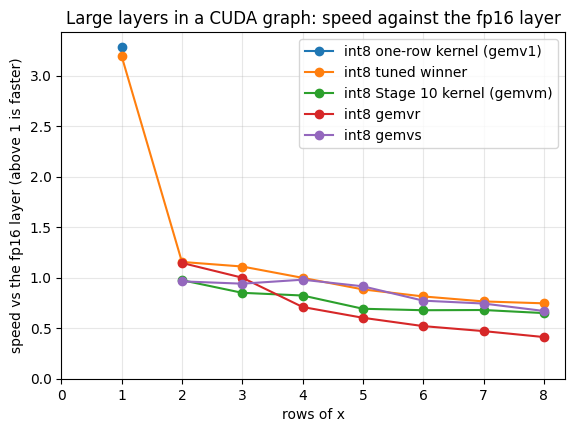

In [29]:
winner = layer_df[layer_df.way == "int8 tuned winner"]
by_rows = winner.groupby("batch").vs_fp.mean()
old_by_rows = layer_df[layer_df.way == "int8 Stage 10 kernel (gemvm)"].groupby("batch").vs_fp.mean()
tab = pd.DataFrame({"tuned winner vs fp16 layer": by_rows, "Stage 10 kernel (gemvm) vs fp16 layer": old_by_rows})
tab["winner over gemvm"] = tab["tuned winner vs fp16 layer"] / tab["Stage 10 kernel (gemvm) vs fp16 layer"]
if S10 is not None:
    tab["Stage 10 run: its tuned kernel vs fp16"] = s10_gate
print("on the large layers of the gate model, inside a CUDA graph, mean by rows of x (above 1 is faster than the fp16 layer):")
print(tab.round(2).to_string())
RATIO_1, RATIO_5, RATIO_8 = (float(by_rows.get(b, float("nan"))) for b in (1, 5, 8))
KERNEL_GO = RATIO_5 == RATIO_5 and RATIO_5 > 1.0
if KERNEL_GO:
    print(f"\nGATE: GO. At 5 rows the tuned int8 kernel is {RATIO_5:.2f}x the fp16 layer on the large layers (1 row: {RATIO_1:.2f}x, 8 rows: {RATIO_8:.2f}x).")
else:
    print(f"\nGATE: NO-GO. At 5 rows the tuned int8 kernel is {RATIO_5:.2f}x the fp16 layer on the large layers (1 row: {RATIO_1:.2f}x, 8 rows: {RATIO_8:.2f}x). "
          "The rest of the notebook still measures what it gives, and the tables above say where the time goes.")
mean_layer = layer_df[layer_df.way != "fp16 layer"].groupby(["way", "batch"], sort=False).vs_fp.mean().reset_index()
line_groups(mean_layer, "batch", "vs_fp", "way", "Large layers in a CUDA graph: speed against the fp16 layer", "speed vs the fp16 layer (above 1 is faster)",
            xlabel="rows of x", save="stage11_layer")

**How to read it.**

- **The correctness table** is a precondition, not a result: the notebook stops if a kernel disagrees with the dequantize path or if a wrong scale is not caught. It lists, per row count, which kernel ran.
- **The gate table.** `vs_fp` above one means the way is faster than the fp16 layer. The summary table compares the tuned winner with `gemvm` and with the number the Stage 10 run itself printed for its tuned kernel (read from its results file). The Stage 10 kernel measured here, in turns with the others, and the Stage 10 number measured then can differ by the clock; if they differ much, the earlier run was not at the same state.
- **`share_of_copy`** is the bandwidth the way reaches for the bytes it stores, as a share of the measured copy bandwidth. For the fp16 layer the bytes are twice as many, so the same share means half the time.
- **`noisy`** flags a comparison whose rounds disagree by more than a tenth of its median. A difference between two ways smaller than their spreads should not be read.
- **The figure** has one line per way: above the dashed line at one the way beats the fp16 layer. The bend of the lines is where the arithmetic of the extra rows stops hiding behind the memory reads.

---
## 3. Does it pay to convert x once?

**Goal:** the new kernels read an fp32 `x`, which the host makes with one small kernel per call. Measure what that conversion costs and what it saves.

**Concept.** Offline, an fp16 `x` converted at every use cost a quarter to two fifths more instructions in the loop. But converting once outside is an extra kernel in the graph for every linear layer, and a layer on a small model takes only a few dozen microseconds. For the best new configuration at 5 rows of each large layer the cell times three things in turns: the layer with `x_fp32` (the conversion is part of the call), the same configuration with `x_fp32` off (fp16 `x` converted inside the loop), and the conversion alone.

> **Predict** (written before running anything below). The conversion alone is a few percent of the layer on the large layers, and `x_fp32` is faster than converting in the loop on all of them. If it is not, the tuner's grids should carry `x_fp32` as a dimension of the search, which is exercise 2.

In [30]:
CAST = []
for name, n, k in [s for s in GATE_SHAPES if s[0] in LARGE]:
    w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
    qt = quantize_weight(w, path="triton")
    b = 5 if 5 in GATE_ROWS else GATE_ROWS[-1]
    new = {v: c for v, c in best_cfg[(n, k, b)].items() if v in ("gemvr", "gemvs")}
    v, cfg = min(new.items(), key=lambda t: next(r["best_by_variant"][t[0]]["median_ms"] for r in tune_rows if (r["out"], r["in"], r["batch"]) == (n, k, b)))
    x = torch.randn(b, k, device=device, dtype=dtype)
    cands = {"x converted once (x_fp32)": lambda: int8_matmul(x, qt.q, qt.scale, dict(cfg, x_fp32=True)),
             "fp16 x converted in the loop": lambda: int8_matmul(x, qt.q, qt.scale, dict(cfg, x_fp32=False)),
             "the conversion alone": lambda: x.float()}
    res = interleaved_times(cands, rounds=ROUNDS, reps=20, iters=ITERS)
    CAST.append({"layer": name, "batch": b, "variant": v, "BLOCK_N": cfg["BLOCK_N"], "BLOCK_K": cfg["BLOCK_K"], "num_warps": cfg["num_warps"],
                 **{f"{c} ms": st["median_ms"] for c, st in res.items()}, "noisy": any(st["noisy"] for st in res.values())})
    del w, qt
    gc.collect(); torch.cuda.empty_cache()
cast_df = pd.DataFrame(CAST)
cast_df["conversion share of layer"] = cast_df["the conversion alone ms"] / cast_df["x converted once (x_fp32) ms"]
cast_df["x_fp32 gain"] = cast_df["fp16 x converted in the loop ms"] / cast_df["x converted once (x_fp32) ms"]
cast_df.round(4)

,layer,batch,variant,BLOCK_N,BLOCK_K,num_warps,x converted once (x_fp32) ms,fp16 x converted in the loop ms,the conversion alone ms,noisy,conversion share of layer,x_fp32 gain
0,mlp gate/up,5,gemvs,32,64,1,0.1455,0.1130,0.0060,True,0.0411,0.7766
1,mlp down,5,gemvr,2,256,2,0.2377,0.0977,0.0058,True,0.0244,0.4111
2,lm_head,5,gemvs,64,64,2,2.8400,4.7184,0.0171,True,0.0060,1.6614


**How to read it.** `x_fp32 gain` above one means converting once is faster than converting in the loop; `conversion share of layer` is the cost of the extra kernel as a share of the whole call. The conversion is timed as a graph node here, as it runs in the decoder, so the launch cost that dominates a small kernel is not included. The gain can be below one even when the conversion alone is cheap: an fp32 `x` doubles the bytes each thread reads from the cache for it, which an instruction count does not show. All three rows are flagged noisy, so read the sign and not the size.

---
## 4. A checking pass in a graph: the `v` of the cost model

**Goal:** measure the number the speculation results hang on: how many plain steps a checking pass costs, for fp16, for int8 with the Stage 10 kernel and for int8 with the kernel of this stage.

**Concept.** `StaticForward` (Stage 10) is a forward pass for a fixed number of tokens over the static KV cache, captured in a CUDA graph. A pass of one token is the plain decode step; a pass of `k + 1` tokens is the checking pass of speculation with `k` drafts. With a free guesser, speculation gains `tokens per round / v`, where `v` is the time of the checking pass over the time of a plain step of the same weights. For each model size and each block length `T` in `BLOCK_TOKENS` this section captures the pass for fp16 (with the padded head, and the one-token pass without it for the comparison), and for int8 under the Stage 10 table and under the new table (the one-token pass is the same kernel in both). The passes of one set of weights are then timed in turns, `ROUNDS` rounds, the order rotated, so `v` is a ratio of numbers taken together. The Stage 10 values of `v` read from its results are shown next to it.

> **Predict** (written before running anything below), with the gate of the stage written down now: **go** if `v` of a 5-token pass of the int8 model is at most `V_GO` at every target, **partial** if it is above that but below `V_PARTIAL` (the kernel helped but int8 and the lookup will not yet multiply), **no-go** otherwise.
>
> - **fp16:** `v` of 1.0 to 1.15 at 5 tokens at every size, as in Stage 10 (the padded head changes the one-token step, not `v` by much).
> - **int8 with the Stage 10 kernel:** it reproduces Stage 10's `v` to within about 10%.
> - **int8 with the new kernel:** `v` of 1.4 to 1.9 at 5 tokens at 1.5B and 3B: better, short of the gate. Small blocks (2 and 3 tokens) are close to 1.1 to 1.3.
> - **The padded fp16 head** makes the fp16 one-token step shorter at every size, by an eighth or so at 1.5B (Stage 10 measured the cost of the one-row product on the head alone), more at 0.5B and less at 3B.

In [31]:
log_gpu("before the block passes", warm=True)
BLOCK = []


def capture(m, pad_head):
    # one captured pass per block length, each on its own static cache; the table installed at the time decides which int8 kernel is in the graph
    out = {}
    for T in BLOCK_TOKENS:
        cache = StaticKVCache(m.n_layers, m.n_kv, CTX + 16, m.hd, m.device, m.dtype)
        f = StaticForward(m, cache, T, all_logits=T > 1, capture=True, pad_head=pad_head)
        f.pos.copy_(torch.arange(CTX, CTX + T, device=device))
        out[T] = f
    return out


def time_passes(size, groups, m):
    # groups: {label: {T: StaticForward}}; every pass of every group is timed in turns, and v is taken against the same group's one-token pass
    fns = {f"{g}|{T}": (lambda f=f: f.replay().argmax(-1)) for g, fs in groups.items() for T, f in fs.items()}
    res = interleaved_times(fns, rounds=ROUNDS, iters=ITERS, use_graph=False)
    floor_ms = 1000 * weight_bytes_read(m) / (COPY_BW * 1e9)
    for g, fs in groups.items():
        for T, f in fs.items():
            st, one = res[f"{g}|{T}"], res[f"{g}|1"]["median_ms"]
            BLOCK.append({"model": size, "variant": g, "tokens": T, "ok": f.mode == "graph", "error": f.graph_error,
                          "median_ms": st["median_ms"], "spread": st["spread"], "noisy": st["noisy"], "rel_to_one_token": st["median_ms"] / one,
                          "floor_ms": floor_ms, "share": floor_ms / st["median_ms"]})


for size in SIZES:
    m16, _ = load_model(size)
    cache = StaticKVCache(m16.n_layers, m16.n_kv, CTX + 16, m16.hd, m16.device, m16.dtype)
    unpadded = StaticForward(m16, cache, 1, all_logits=False, capture=True, pad_head=False)        # the one-token pass without the padded head, for the comparison
    unpadded.pos.copy_(torch.arange(CTX, CTX + 1, device=device))
    groups = {"fp16": capture(m16, True), "fp16, head not padded": {1: unpadded}}
    time_passes(size, groups, m16)
    del groups, unpadded, cache
    gc.collect(); torch.cuda.empty_cache()
    q = quantize_model(m16, path="triton")           # shares the embedding table and the norms; the int8 matrices are new
    del m16                                          # not needed again: free the fp16 matrices before the int8 runs
    gc.collect(); torch.cuda.empty_cache()
    int8_kernel.set_configs(OLD_TABLE)
    old = capture(q, False)
    int8_kernel.set_configs(NEW_TABLE)
    new = capture(q, False)
    old[1] = new[1]                                  # the one-token kernel is the same in both tables
    time_passes(size, {"int8 Stage 10 kernel": old, "int8 this stage": new}, q)
    print(f"{size} done")
    del old, new, q
    gc.collect(); torch.cuda.empty_cache()
log_gpu("after the block passes")

block_df = pd.DataFrame(BLOCK)
if S10 is not None:
    s10_v = {(r["model"], r["tokens"], r["variant"]): r["rel_to_one_token"] for r in S10["block_cost"] if r["mode"] == "graph"}
    block_df["stage10_v"] = [s10_v.get((r.model, r.tokens, "int8" if r.variant.startswith("int8") else "fp16")) for r in block_df.itertuples()]
if not block_df.ok.all():
    print("WARNING: some passes could not be captured in a graph and were timed eagerly:", block_df[~block_df.ok].error.dropna().unique()[:2])
block_df[[c for c in ("model", "variant", "tokens", "ok", "median_ms", "spread", "noisy", "rel_to_one_token", "stage10_v", "floor_ms", "share", "error") if c in block_df]].round(3)

[before the block passes] 1140.0 MHz (max 1590.0), 79.0 C, 64.87 W of 70.0 W, throttle: 0x0000000000000004


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

0.5B done


... (8 outputs left out)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

3B done
[after the block passes] 1590.0 MHz (max 1590.0), 75.0 C, 51.03 W of 70.0 W, throttle: 0x0000000000000000


,model,variant,tokens,ok,median_ms,spread,noisy,rel_to_one_token,floor_ms,share,error
0,0.5B,fp16,1,True,8.719,0.390,True,1.000,4.062,0.466,None
1,0.5B,fp16,2,True,8.971,0.014,False,1.029,4.062,0.453,None
2,0.5B,fp16,3,True,8.894,0.013,False,1.020,4.062,0.457,None
3,0.5B,fp16,5,True,9.081,0.012,False,1.041,4.062,0.447,None
4,0.5B,fp16,7,True,9.154,0.007,False,1.050,4.062,0.444,None
5,0.5B,"fp16, head not padded",1,True,9.033,0.009,False,1.000,4.062,0.450,None
6,0.5B,int8 Stage 10 kernel,1,True,6.458,0.234,True,1.000,2.035,0.315,None
7,0.5B,int8 Stage 10 kernel,2,True,8.811,0.070,False,1.364,2.035,0.231,None
8,0.5B,int8 Stage 10 kernel,3,True,9.953,0.017,False,1.541,2.035,0.204,None
9,0.5B,int8 Stage 10 kernel,5,True,12.156,0.059,False,1.882,2.035,0.167,None


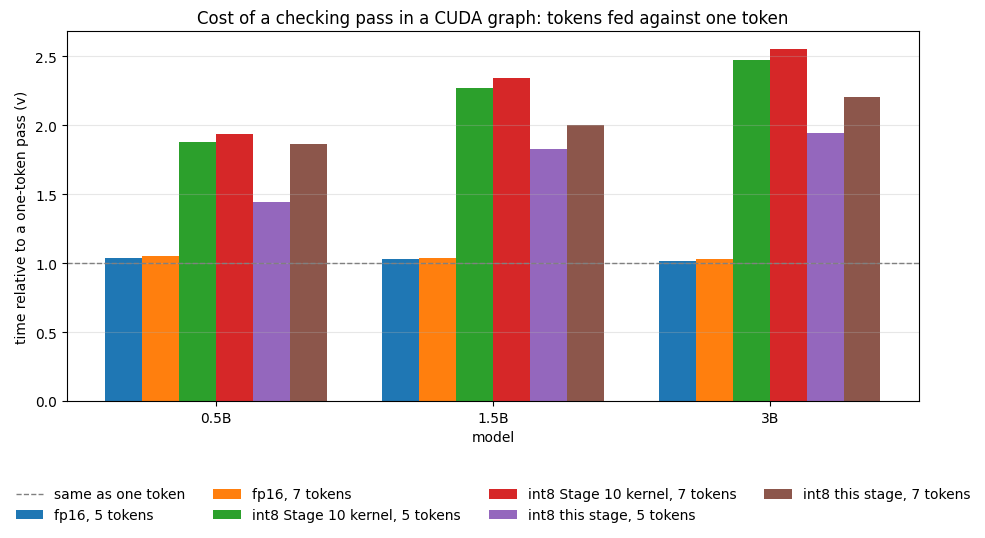

the one-token pass (argmax included), ms, and the share of the fp16 step the padded head saves:
variant    fp16  fp16, head not padded  int8 Stage 10 kernel  int8 this stage  padding the head saves
model                                                                                                
0.5B      8.719                  9.033                 6.458            6.434                   0.035
1.5B     19.410                 19.806                11.835           11.802                   0.020
3B       35.608                 36.028                20.078           20.271                   0.012

v of a 5-token pass at the targets: fp16 1.5B 1.03, 3B 1.01; int8 Stage 10 kernel 1.5B 2.27, 3B 2.47; int8 this stage 1.5B 1.83, 3B 1.94
GATE (NO-GO): the worst v of the new kernel is 1.94; go is at most 1.3, partial is below 1.7.


In [32]:
g = block_df[block_df.ok & (block_df.tokens > 1)]
labels = ["fp16", "int8 Stage 10 kernel", "int8 this stage"]
series = {f"{v}, {t} tokens": [float(g[(g.model == s) & (g.variant == v) & (g.tokens == t)].rel_to_one_token.iloc[0]) if len(g[(g.model == s) & (g.variant == v) & (g.tokens == t)]) else float("nan")
                              for s in SIZES] for v in labels for t in BLOCK_TOKENS if t in (5, 7)}
grouped_bar(SIZES, series, "Cost of a checking pass in a CUDA graph: tokens fed against one token", "time relative to a one-token pass (v)", hline=1.0,
            hline_label="same as one token", xlabel="model", figsize=(11, 4.8), save="stage11_block_cost")

step = block_df[(block_df.tokens == 1)].pivot_table(index="model", columns="variant", values="median_ms")
step["padding the head saves"] = 1 - step["fp16"] / step["fp16, head not padded"]
print("the one-token pass (argmax included), ms, and the share of the fp16 step the padded head saves:")
print(step.round(3).to_string())

T_GATE = 5 if 5 in BLOCK_TOKENS else BLOCK_TOKENS[-1]
v_new = block_df[(block_df.variant == "int8 this stage") & (block_df.tokens == T_GATE) & block_df.model.isin(TARGETS)].set_index("model").rel_to_one_token
v_old = block_df[(block_df.variant == "int8 Stage 10 kernel") & (block_df.tokens == T_GATE) & block_df.model.isin(TARGETS)].set_index("model").rel_to_one_token
v_fp = block_df[(block_df.variant == "fp16") & (block_df.tokens == T_GATE) & block_df.model.isin(TARGETS)].set_index("model").rel_to_one_token
V_WORST = float(v_new.max())
V_VERDICT = "GO" if V_WORST <= V_GO else "PARTIAL" if V_WORST < V_PARTIAL else "NO-GO"
print(f"\nv of a {T_GATE}-token pass at the targets: fp16 {', '.join(f'{s} {v_fp[s]:.2f}' for s in TARGETS)}; int8 Stage 10 kernel {', '.join(f'{s} {v_old[s]:.2f}' for s in TARGETS)}; "
      f"int8 this stage {', '.join(f'{s} {v_new[s]:.2f}' for s in TARGETS)}")
print(f"GATE ({V_VERDICT}): the worst v of the new kernel is {V_WORST:.2f}; go is at most {V_GO}, partial is below {V_PARTIAL}.")

**How to read it.**

- **`rel_to_one_token`** is the `v` of the cost model: the time of a checking pass over the time of a plain step of the same weights. Speculation with a free guesser pays off while `tokens per round / v` is above one, so every 0.1 of `v` matters. `stage10_v` is the value the Stage 10 run measured for the same model and block length. The `fp16, head not padded` row exists only for the one-token pass.
- **The verdict line** applies the gate that was written before the run. It is about the kernel inside a whole pass, which also has norms, attention, the KV cache and the graph's own overhead.
- **The one-token table** shows what padding the head buys the fp16 baseline, by model size. This is the part of Stage 10's fp16 result that was a cuBLAS artifact and not the weights.
- **`noisy`** has the same meaning as in section 2. The passes of one set of weights were timed in turns, so a ratio between two of them is taken at the same clock even when the absolute times drift.

---
## 5. Plain decoding, and what the fair fp16 baseline changes

**Goal:** the decode rate of a whole generation for fp16 in a graph with and without the padded head, and for int8 in a graph, at the three sizes.

**Concept.** `GraphDecoder.plain` prefills eagerly through the static cache and then feeds every new token through the captured one-token pass; the token never leaves the GPU between steps. The rate here is the decode rate (tokens after the first, over the sum of the per-token times, prefill excluded), the median over `PLAIN_RUNS` runs, with the runs of the compared setups taken in turns. Each output is compared with the eager output of the same weights; a difference must be an fp16 near-tie. The int8 one-token kernel is the same as in Stage 10, so this section isolates the head: the fp16 baseline that every int8 and speculation gain is measured against.

> **Predict** (written before running anything below). The padded head raises the fp16 graph decode rate at every size, most at 0.5B (where the head is a large share of the step) and least at 3B. The int8 graph rate does not change from Stage 10 within the noise. All outputs equal eager greedy or differ at a near-tie.

[before plain decoding] 1320.0 MHz (max 1590.0), 74.0 C, 65.81 W of 70.0 W, throttle: 0x0000000000000004


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

0.5B done


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

1.5B done


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

3B done


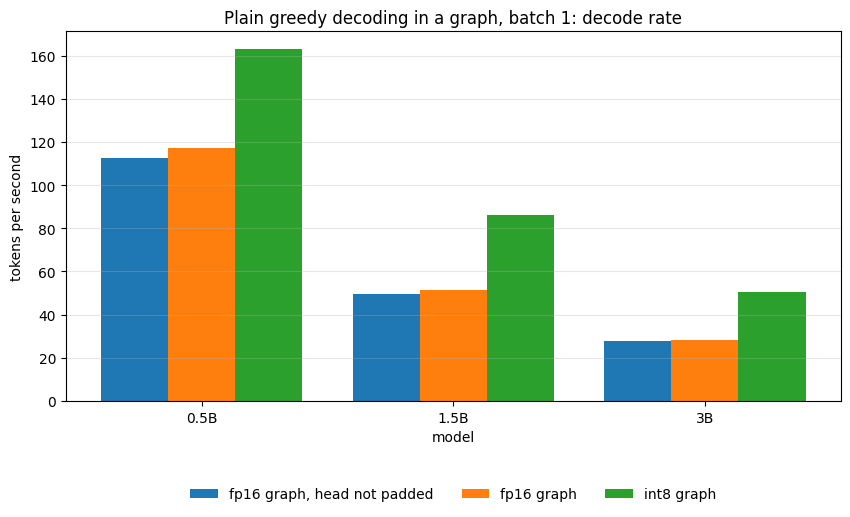

every output equals the eager output of the same weights, or differs at a near-tie: True


,model,setup,ok,decode_tok_s,spread,step_ms,same_as_eager,first_mismatch,logit_gap,error
0,0.5B,"fp16 graph, head not padded",True,112.655,0.003,8.877,True,None,None,None
1,0.5B,fp16 graph,True,116.980,0.006,8.548,True,None,None,None
2,0.5B,int8 graph,True,163.035,0.004,6.134,True,None,None,None
3,1.5B,"fp16 graph, head not padded",True,49.737,0.012,20.106,True,None,None,None
4,1.5B,fp16 graph,True,51.591,0.006,19.383,True,None,None,None
5,1.5B,int8 graph,True,85.952,0.004,11.634,True,None,None,None
6,3B,"fp16 graph, head not padded",True,27.813,0.068,35.955,True,None,None,None
7,3B,fp16 graph,True,28.121,0.031,35.561,True,None,None,None
8,3B,int8 graph,True,50.556,0.001,19.780,True,None,None,None


In [33]:
PLAIN = []


def time_plain(size, cands, m, ids):
    # cands: {label: GraphDecoder}; the runs of all candidates are taken in turns
    ref = greedy(m, ids, MAX_NEW)
    stats = {label: {"rates": [], "same": True, "tie": None} for label in cands}
    for label, dec in cands.items():
        dec.plain(ids, MAX_NEW)                                                 # warm-up
    for _ in range(PLAIN_RUNS):
        for label, dec in cands.items():
            tokens, st = dec.plain(ids, MAX_NEW)
            stats[label]["rates"].append((MAX_NEW - 1) / sum(st["itl"]))
            if tokens != ref:
                stats[label]["same"] = False
                stats[label]["tie"] = tie_gap(m, ids, ref, tokens)
    for label, dec in cands.items():
        r = stats[label]["rates"]
        med = float(np.median(r))
        tie = stats[label]["tie"]
        PLAIN.append({"model": size, "setup": label, "ok": dec.mode == "graph", "error": dec.graph_error, "decode_tok_s": med, "spread": (max(r) - min(r)) / med, "step_ms": 1000 / med,
                      "same_as_eager": stats[label]["same"], "first_mismatch": None if tie is None else tie[0], "logit_gap": None if tie is None else tie[1]})


log_gpu("before plain decoding", warm=True)
for size in SIZES:
    ids = PROMPT_IDS["open"][0]
    m16, _ = load_model(size)
    time_plain(size, {"fp16 graph, head not padded": GraphDecoder(m16, MAX_LEN), "fp16 graph": GraphDecoder(m16, MAX_LEN, pad_head=True)}, m16, ids)
    q = quantize_model(m16, path="triton")
    del m16
    gc.collect(); torch.cuda.empty_cache()
    int8_kernel.set_configs(NEW_TABLE)
    time_plain(size, {"int8 graph": GraphDecoder(q, MAX_LEN)}, q, ids)
    print(f"{size} done")
    del q
    gc.collect(); torch.cuda.empty_cache()

plain_df = pd.DataFrame(PLAIN)
PLAIN_EXACT = all(r["same_as_eager"] or (r["logit_gap"] is not None and r["logit_gap"] < NEAR_TIE) for r in PLAIN)


def rate(size, setup):
    r = plain_df[(plain_df.model == size) & (plain_df.setup == setup)]
    return float(r.decode_tok_s.iloc[0]) if len(r) else float("nan")


grouped_bar(SIZES, {s: [rate(z, s) for z in SIZES] for s in ("fp16 graph, head not padded", "fp16 graph", "int8 graph")}, "Plain greedy decoding in a graph, batch 1: decode rate",
            "tokens per second", xlabel="model", figsize=(10, 4.8), save="stage11_plain_rate")
ratio_plain = pd.DataFrame([{"model": s, "padded head / not padded (fp16)": rate(s, "fp16 graph") / rate(s, "fp16 graph, head not padded"),
                             "int8 graph / fp16 graph": rate(s, "int8 graph") / rate(s, "fp16 graph"),
                             "int8 graph / fp16 graph, head not padded": rate(s, "int8 graph") / rate(s, "fp16 graph, head not padded")} for s in SIZES])
print("every output equals the eager output of the same weights, or differs at a near-tie:", PLAIN_EXACT)
assert PLAIN_EXACT, f"a graph output differs from eager greedy where the two tokens are not nearly tied (gap of {NEAR_TIE} or more)"
plain_df[["model", "setup", "ok", "decode_tok_s", "spread", "step_ms", "same_as_eager", "first_mismatch", "logit_gap", "error"]].round(3)

In [34]:
ratio_plain.round(2)

,model,padded head / not padded (fp16),int8 graph / fp16 graph,"int8 graph / fp16 graph, head not padded"
0,0.5B,1.04,1.39,1.45
1,1.5B,1.04,1.67,1.73
2,3B,1.01,1.80,1.82


**How to read it.** The ratios table is the answer: the first column is what the padded head buys the fp16 decoder, the second the weight format against the fair baseline, the third against the baseline of Stage 10. The padded head can differ from the one-row product in the last fp16 bit (it is a different cuBLAS kernel), so the output of `fp16 graph` can differ from eager at a near-tie, which the check allows and reads.

---
## 6. Speculation in the graph: do int8 and the lookup multiply now?

**Goal:** answer the question Stage 10 left open with the new kernel, against a fair fp16 baseline, and read the effect of the kernel alone as a ratio of two setups measured in the same session.

**Concept.** `GraphDecoder.speculative` is the loop of Stage 6 with the checking pass in a graph. Each round the n-gram lookup proposes up to `k` tokens (no model, no cost to speak of), the block `[last accepted token] + drafts` is padded with zeros to length `k + 1`, one captured pass of that fixed length returns the model's own greedy choice after every fed token, and the decoder accepts the longest prefix of drafts that agree plus the one token the pass adds. A round with no draft at all runs the ordinary one-token pass. The output is the target's own greedy output for any proposer, up to fp16 near-ties. With a free guesser, Stage 7's cost model reduces to

```
tokens per round  =  (1 - alpha^(k+1)) / (1 - alpha)
speedup over plain decoding of the same weights  =  tokens per round / v
```

where `v` is the checking pass over a plain step (section 4). **Speculation cuts the number of weight reads per token; int8 cuts the bytes per read. If a step is bandwidth-bound the two multiply, exactly if `v` is the same for both weight formats.**

**What we measure.** Targets 1.5B and 3B, three workloads (`copy`, `code`, `open`), `k` in `{4, 6}`, the n-gram lookup and plain decoding, for four setups, each with its own plain baseline (the median of `BASELINE_RUNS` timings):

| setup | engine |
| --- | --- |
| fp16 | the eager engine of Stage 9 (the baseline of every earlier stage) |
| fp16 | the graph decoder, with the padded head (the fair fp16 baseline) |
| int8 with the Stage 10 kernel | the graph decoder |
| int8 with the kernel of this stage | the graph decoder |

Every speedup is a ratio of tokens per second of whole generations (prefill included) against each of fp16 eager plain, fp16 graph plain and int8 graph plain. Then the question itself, per workload and `k`: the gain of int8 alone, the gain of the lookup alone, their product, what int8 plus the lookup gave with each kernel, and how it compares with the best fp16 setup, **fp16 in a graph with the lookup**. That last ratio is the practical question: does int8 beat fp16 once both have the lookup?

**Exactness.** For each setup, the first prompt of each workload, 32 tokens: the speculative output against the same weights' plain eager greedy output; a difference must be an fp16 near-tie (the logit gap at the first difference is read, and the notebook stops if it is not), with an fp16 eager speculative run as the control that near-ties happen without any graph or int8. And a **control that must fail**: the same decoder with a mask that lets every row see all keys up to the end of the block must produce a different output.

> **Predict** (written before running anything below), from the gate of section 4 and the Stage 10 results:
>
> - **(a) The new kernel raises the int8 plus lookup rate** over the Stage 10 kernel on `copy` and `code` at both targets, by a factor of about `v` of the old kernel over `v` of the new (the cost model says so for a free guesser), and not on `open` text, where rounds mostly run the one-token pass.
> - **(b) The gains still do not fully multiply.** `both_over_product` rises but stays below 0.9 at 1.5B, and is higher at 3B than at 1.5B (3B's step is more bandwidth-bound).
> - **(c) The best setup on `copy` and `code` is still fp16 in a graph with the lookup** at 1.5B, unless the verdict of section 4 is a go. At 3B the two are within about a tenth of each other. On `open` text the best setup is int8 plain in a graph.
> - **(d) The fair fp16 baseline** (padded head) raises every fp16 graph rate and so lowers every `vs_fp16_graph` ratio of int8 relative to Stage 10.
> - **(e) The cost model fed with the measured `v` and `alpha` predicts the speedup to within about a quarter** and overstates `open` text.
> - **(f) Exactness:** every difference from plain greedy is a near-tie; the fp16 eager control shows near-ties without any graph or int8; the non-causal control breaks the output.

In [35]:
SPEC_ROWS, EXACT_ROWS, CONTROL_ROWS = [], [], []
NGRAM = {"n-gram": PromptLookup()}
WL = ["copy", "code", "open"]


def sweep(t, weights, engine, tm, dec=None):
    kw = {} if dec is None else {"plain_fn": dec.plain, "spec_fn": dec.speculative}
    rows = sweep_proposers(tm, PROMPT_IDS, MAX_NEW, KS, NGRAM, verbose=False, baseline_runs=BASELINE_RUNS, **kw)
    SPEC_ROWS.extend({"target": t, "weights": weights, "engine": engine, **r} for r in rows)


def exact_rows(t, setup, tm, run):
    # first prompt of each workload, 32 tokens: `run(ids)` against the same weights' plain eager greedy output, with the logit gap at a difference
    for name in WL:
        ids = PROMPT_IDS[name][0]
        ref = greedy(tm, ids, 32)
        i, gap = tie_gap(tm, ids, ref, run(ids))
        EXACT_ROWS.append({"target": t, "setup": setup, "workload": name, "first_mismatch": i, "logit_gap": gap})


log_gpu("before the speculation sweeps", warm=True)
for tsize in TARGETS:
    t16, _ = load_model(tsize)
    t8 = quantize_model(t16, path="triton")
    dec16 = GraphDecoder(t16, MAX_LEN, ks=KS, pad_head=True)
    int8_kernel.set_configs(OLD_TABLE)
    dec8_old = GraphDecoder(t8, MAX_LEN, ks=KS)
    int8_kernel.set_configs(NEW_TABLE)
    dec8 = GraphDecoder(t8, MAX_LEN, ks=KS)
    print(f"{tsize}: fp16 and int8 loaded, decoders captured ({dec16.mode}, {dec8_old.mode}, {dec8.mode}), {gib():.2f} GiB in use")
    if dec16.graph_error or dec8.graph_error:
        print("  graph capture problem:", dec16.graph_error or dec8.graph_error)
    sweep(tsize, "fp16", "eager", t16)
    print(f"  {tsize}: fp16 eager done")
    sweep(tsize, "fp16", "graph", t16, dec16)
    print(f"  {tsize}: fp16 graph done")
    sweep(tsize, "int8", "graph", t8, dec8)
    print(f"  {tsize}: int8 graph (this stage) done")
    sweep(tsize, "int8 Stage 10 kernel", "graph", t8, dec8_old)
    print(f"  {tsize}: int8 graph (Stage 10 kernel) done")
    exact_rows(tsize, "fp16 eager n-gram (control)", t16, lambda ids: generate_speculative(t16, ids, 32, k=4, proposer=PromptLookup())[0])
    exact_rows(tsize, "fp16 graph n-gram", t16, lambda ids: dec16.speculative(ids, 32, 4, PromptLookup())[0])
    exact_rows(tsize, "int8 graph n-gram", t8, lambda ids: dec8.speculative(ids, 32, 4, PromptLookup())[0])
    exact_rows(tsize, "int8 graph plain", t8, lambda ids: dec8.plain(ids, 32)[0])
    if tsize == TARGETS[0]:
        broken = GraphDecoder(t16, MAX_LEN, ks=(4,), causal=False)          # the negative control: rows may see keys after their own position
        for name in WL:
            ids = PROMPT_IDS[name][0]
            ref = greedy(t16, ids, 32)
            CONTROL_ROWS.append({"target": tsize, "workload": name, "differs": broken.speculative(ids, 32, 4, PromptLookup())[0] != ref})
        del broken
    del dec16, dec8, dec8_old, t16, t8
    gc.collect(); torch.cuda.empty_cache()
log_gpu("after the speculation sweeps")

exact_df, control_df = pd.DataFrame(EXACT_ROWS), pd.DataFrame(CONTROL_ROWS)
SPEC_EXACT = all(r["first_mismatch"] is None or r["logit_gap"] < NEAR_TIE for r in EXACT_ROWS)
CONTROL_BREAKS = bool(control_df.differs.any())
print(exact_df.round(3).to_string(index=False))
print("\nevery speculative difference is a near-tie:", SPEC_EXACT)
print("a mask that lets rows see later keys changes the output (so the check can fail):", CONTROL_BREAKS)
assert SPEC_EXACT, f"a speculative output differs from plain greedy where the two tokens are not nearly tied (logit gap of {NEAR_TIE} or more): that is not fp16 rounding"
assert CONTROL_BREAKS, "the non-causal control did not change any output, so the exactness check cannot be trusted"

[before the speculation sweeps] 1125.0 MHz (max 1590.0), 76.0 C, 65.71 W of 70.0 W, throttle: 0x0000000000000004


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

1.5B: fp16 and int8 loaded, decoders captured (graph, graph, graph), 4.65 GiB in use
  1.5B: fp16 eager done
  1.5B: fp16 graph done
  1.5B: int8 graph (this stage) done
  1.5B: int8 graph (Stage 10 kernel) done


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

3B: fp16 and int8 loaded, decoders captured (graph, graph, graph), 9.04 GiB in use
  3B: fp16 eager done
  3B: fp16 graph done
  3B: int8 graph (this stage) done
  3B: int8 graph (Stage 10 kernel) done
[after the speculation sweeps] 1590.0 MHz (max 1590.0), 76.0 C, 50.57 W of 70.0 W, throttle: 0x0000000000000000
target                       setup workload  first_mismatch  logit_gap
  1.5B fp16 eager n-gram (control)     copy             NaN        NaN
  1.5B fp16 eager n-gram (control)     code             NaN        NaN
  1.5B fp16 eager n-gram (control)     open             NaN        NaN
  1.5B           fp16 graph n-gram     copy             NaN        NaN
  1.5B           fp16 graph n-gram     code             NaN        NaN
  1.5B           fp16 graph n-gram     open             NaN        NaN
  1.5B           int8 graph n-gram     copy             NaN        NaN
  1.5B           int8 graph n-gram     code             2.0      0.008
  1.5B           int8 graph n-gram     open    

In [36]:
spec_df = pd.DataFrame(SPEC_ROWS)
spec_df["setup"] = spec_df.weights + " " + spec_df.engine + " " + spec_df.proposer


def plain_rate_of(weights, engine):
    r = spec_df[(spec_df.weights == weights) & (spec_df.engine == engine) & (spec_df.proposer == "plain")]
    return r.set_index(["target", "workload"]).tok_s


base_eager, base_g16, base_g8 = plain_rate_of("fp16", "eager"), plain_rate_of("fp16", "graph"), plain_rate_of("int8", "graph")
spec_df["vs_fp16_eager"] = [r.tok_s / base_eager[(r.target, r.workload)] for r in spec_df.itertuples()]
spec_df["vs_fp16_graph"] = [r.tok_s / base_g16[(r.target, r.workload)] for r in spec_df.itertuples()]
spec_df["vs_int8_graph"] = [r.tok_s / base_g8[(r.target, r.workload)] for r in spec_df.itertuples()]
plain_ms = spec_df[spec_df.proposer == "plain"].set_index(["target", "weights", "engine", "workload"]).target_ms
# the cost model fed with this row's own measured numbers (tokens per round from its alpha; v and the guess from its own timings), against plain of the same weights and engine
spec_df["v"] = [float("nan") if r.proposer == "plain" else r.target_ms / plain_ms[(r.target, r.weights, r.engine, r.workload)] for r in spec_df.itertuples()]
spec_df["pred_x"] = [float("nan") if r.proposer == "plain" else r.expected_tokens * plain_ms[(r.target, r.weights, r.engine, r.workload)] / (r.guess_ms + r.target_ms)
                     for r in spec_df.itertuples()]
view = spec_df[spec_df.proposer != "plain"][["target", "workload", "setup", "k", "alpha", "tokens_per_step", "draft_found_frac", "target_ms", "v", "speedup_x", "pred_x",
                                             "vs_fp16_eager", "vs_fp16_graph", "vs_int8_graph", "n_exact", "n_prompts"]]
view.round(2)

,target,workload,setup,k,alpha,tokens_per_step,draft_found_frac,target_ms,v,speedup_x,pred_x,vs_fp16_eager,vs_fp16_graph,vs_int8_graph,n_exact,n_prompts
1,1.5B,copy,fp16 eager n-gram,4,0.79,2.48,0.72,28.97,1.10,2.22,3.00,2.22,1.60,1.01,3,3
2,1.5B,copy,fp16 eager n-gram,6,0.80,2.71,0.70,28.77,1.09,2.44,3.62,2.44,1.76,1.11,3,3
4,1.5B,code,fp16 eager n-gram,4,0.70,2.18,0.68,28.67,1.07,1.98,2.59,1.98,1.43,0.90,3,3
5,1.5B,code,fp16 eager n-gram,6,0.71,2.36,0.66,28.41,1.06,2.16,2.94,2.16,1.56,0.98,3,3
7,1.5B,open,fp16 eager n-gram,4,0.29,1.14,0.37,27.75,1.05,1.09,1.34,1.09,0.79,0.49,3,3
8,1.5B,open,fp16 eager n-gram,6,0.30,1.15,0.37,28.37,1.07,1.07,1.33,1.07,0.77,0.48,2,3
10,1.5B,copy,fp16 graph n-gram,4,0.79,2.48,0.72,19.73,1.04,2.31,3.17,3.21,2.31,1.47,3,3
11,1.5B,copy,fp16 graph n-gram,6,0.80,2.71,0.70,19.83,1.05,2.52,3.78,3.49,2.52,1.60,3,3
13,1.5B,code,fp16 graph n-gram,4,0.72,2.18,0.69,19.81,1.04,2.04,2.75,2.84,2.04,1.29,3,3
14,1.5B,code,fp16 graph n-gram,6,0.71,2.36,0.67,19.92,1.05,2.20,3.02,3.05,2.20,1.39,3,3


In [37]:
# do the gains multiply? per target, workload and k: int8 alone, the lookup alone, their product, and int8 plus the lookup measured with each kernel
MULT = []
for t in TARGETS:
    for w in WL:
        for k in KS:
            def tok_s(weights, engine, proposer):
                r = spec_df[(spec_df.target == t) & (spec_df.workload == w) & (spec_df.weights == weights) & (spec_df.engine == engine) & (spec_df.proposer == proposer)
                            & ((spec_df.k == k) if proposer != "plain" else True)]
                return float(r.tok_s.iloc[0])
            def v_of(weights, engine):
                return float(spec_df[(spec_df.target == t) & (spec_df.workload == w) & (spec_df.weights == weights) & (spec_df.engine == engine) & (spec_df.proposer == "n-gram") & (spec_df.k == k)].v.iloc[0])
            fp_plain, i8_plain = tok_s("fp16", "graph", "plain"), tok_s("int8", "graph", "plain")
            fp_spec, i8_spec, old_spec = tok_s("fp16", "graph", "n-gram"), tok_s("int8", "graph", "n-gram"), tok_s("int8 Stage 10 kernel", "graph", "n-gram")
            product = (i8_plain / fp_plain) * (fp_spec / fp_plain)
            MULT.append({"target": t, "workload": w, "k": k, "int8_alone": i8_plain / fp_plain, "ngram_alone_fp16": fp_spec / fp_plain, "ngram_alone_int8": i8_spec / i8_plain,
                         "product": product, "measured_both": i8_spec / fp_plain, "measured_both_stage10_kernel": old_spec / fp_plain,
                         "both_over_product": (i8_spec / fp_plain) / product, "both_over_product_stage10_kernel": (old_spec / fp_plain) / product,
                         "new_kernel_gain": i8_spec / old_spec, "int8_spec_over_fp16_spec": i8_spec / fp_spec,
                         "v_int8": v_of("int8", "graph"), "v_int8_stage10_kernel": v_of("int8 Stage 10 kernel", "graph"), "v_fp16": v_of("fp16", "graph"),
                         "vs_fp16_eager_plain": i8_spec / tok_s("fp16", "eager", "plain")})
mult_df = pd.DataFrame(MULT)
mult_df.round(2)

,target,workload,k,int8_alone,ngram_alone_fp16,ngram_alone_int8,product,measured_both,measured_both_stage10_kernel,both_over_product,both_over_product_stage10_kernel,new_kernel_gain,int8_spec_over_fp16_spec,v_int8,v_int8_stage10_kernel,v_fp16,vs_fp16_eager_plain
0,1.5B,copy,4,1.58,2.31,1.50,3.65,2.36,2.01,0.65,0.55,1.17,1.02,1.63,1.94,1.04,3.27
1,1.5B,copy,6,1.58,2.52,1.55,3.96,2.45,2.17,0.62,0.55,1.13,0.97,1.71,1.96,1.05,3.40
2,1.5B,code,4,1.58,2.04,1.33,3.24,2.11,1.82,0.65,0.56,1.16,1.03,1.56,1.83,1.04,2.93
3,1.5B,code,6,1.58,2.20,1.36,3.48,2.15,1.91,0.62,0.55,1.12,0.98,1.63,1.86,1.05,2.99
4,1.5B,open,4,1.61,1.11,0.89,1.79,1.43,1.29,0.80,0.72,1.11,1.28,1.33,1.49,1.02,1.98
5,1.5B,open,6,1.61,1.12,0.87,1.80,1.40,1.28,0.78,0.71,1.09,1.25,1.38,1.51,1.02,1.94
6,3B,copy,4,1.72,4.19,2.21,7.19,3.80,3.21,0.53,0.45,1.18,0.91,1.87,2.28,1.03,4.47
7,3B,copy,6,1.72,5.33,2.54,9.14,4.37,3.96,0.48,0.43,1.10,0.82,2.08,2.34,1.04,5.14
8,3B,code,4,1.70,1.88,1.16,3.21,1.98,1.70,0.62,0.53,1.17,1.05,1.60,1.89,1.02,2.02
9,3B,code,6,1.70,1.99,1.11,3.39,1.90,1.73,0.56,0.51,1.10,0.95,1.75,1.93,1.02,1.94


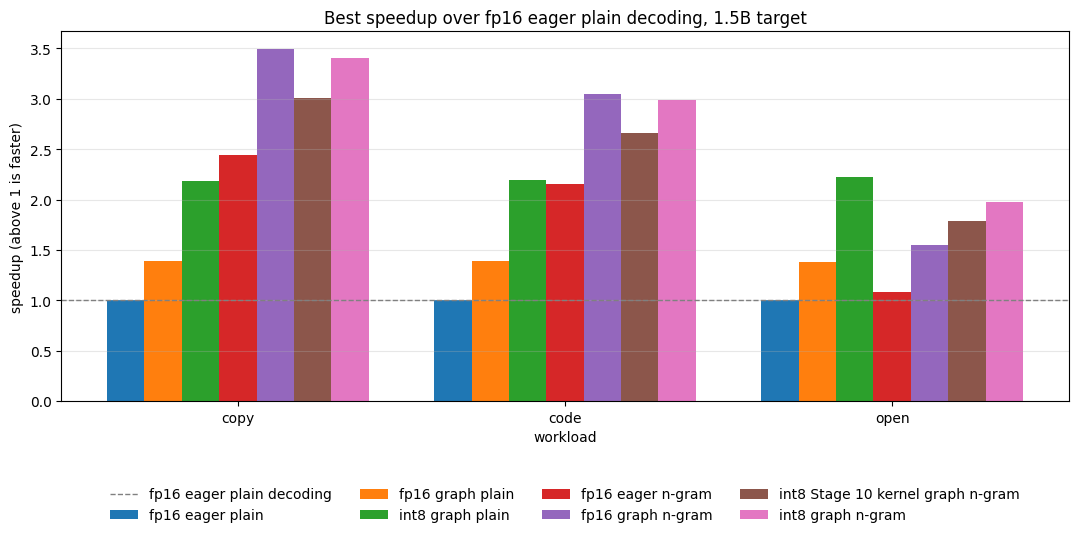

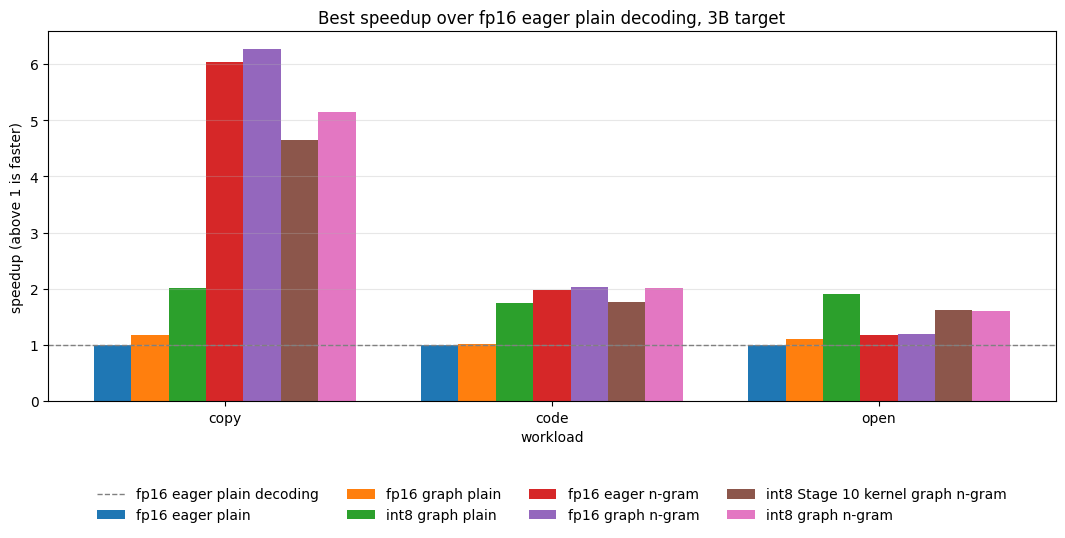

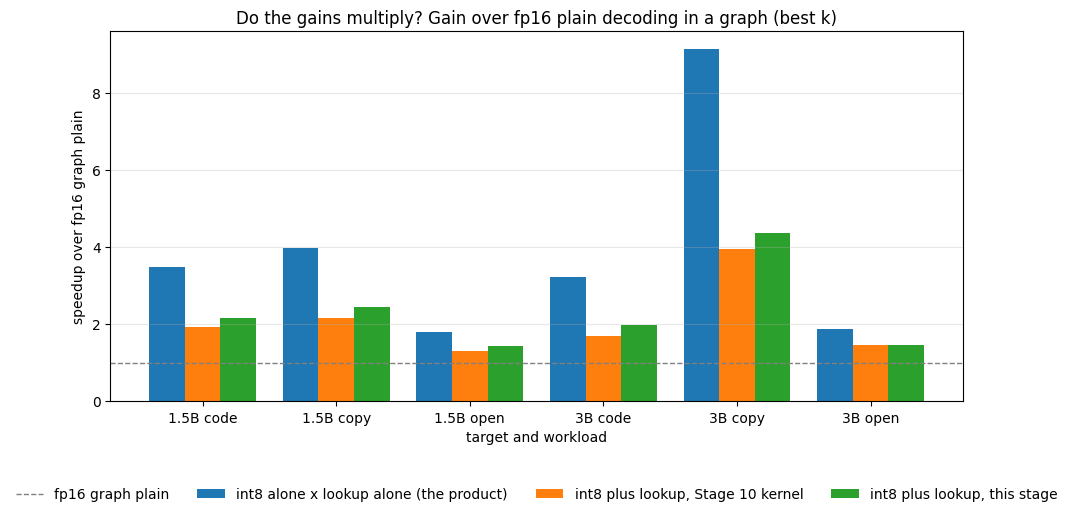

,target,workload,setup,k,vs_fp16_eager,vs_fp16_graph,alpha,tokens_per_step
0,1.5B,code,fp16 eager n-gram,6,2.16,1.56,0.71,2.36
1,1.5B,code,fp16 eager plain,0,1.00,0.72,0.00,1.00
2,1.5B,code,fp16 graph n-gram,6,3.05,2.20,0.71,2.36
3,1.5B,code,fp16 graph plain,0,1.39,1.00,0.00,1.00
4,1.5B,code,int8 Stage 10 kernel graph n-gram,6,2.66,1.91,0.71,2.28
6,1.5B,code,int8 graph n-gram,6,2.99,2.15,0.71,2.28
7,1.5B,code,int8 graph plain,0,2.20,1.58,0.00,1.00
8,1.5B,copy,fp16 eager n-gram,6,2.44,1.76,0.80,2.71
9,1.5B,copy,fp16 eager plain,0,1.00,0.72,0.00,1.00
10,1.5B,copy,fp16 graph n-gram,6,3.49,2.52,0.80,2.71


In [38]:
idx = spec_df.groupby(["target", "workload", "setup"])["vs_fp16_eager"].idxmax()       # the best draft length of each setup
best = spec_df.loc[idx].reset_index(drop=True)
ORDER = ["fp16 eager plain", "fp16 graph plain", "int8 graph plain", "fp16 eager n-gram", "fp16 graph n-gram", "int8 Stage 10 kernel graph n-gram", "int8 graph n-gram"]
for tsize in TARGETS:
    b = best[best.target == tsize].set_index(["setup", "workload"]).vs_fp16_eager
    grouped_bar(WL, {s: [float(b.get((s, w), float("nan"))) for w in WL] for s in ORDER},
                f"Best speedup over fp16 eager plain decoding, {tsize} target", "speedup (above 1 is faster)", hline=1.0, hline_label="fp16 eager plain decoding",
                xlabel="workload", figsize=(13, 4.8), save=f"stage11_speedup_{tsize.replace('.', 'p').lower()}")
m_best = mult_df.loc[mult_df.groupby(["target", "workload"]).measured_both.idxmax()]
labels = [f"{r.target} {r.workload}" for r in m_best.itertuples()]
grouped_bar(labels, {"int8 alone x lookup alone (the product)": list(m_best["product"]), "int8 plus lookup, Stage 10 kernel": list(m_best["measured_both_stage10_kernel"]),
                     "int8 plus lookup, this stage": list(m_best["measured_both"])},
            "Do the gains multiply? Gain over fp16 plain decoding in a graph (best k)", "speedup over fp16 graph plain", hline=1.0, hline_label="fp16 graph plain",
            xlabel="target and workload", figsize=(11, 4.8), save="stage11_multiply")
best[best.setup.isin(ORDER)][["target", "workload", "setup", "k", "vs_fp16_eager", "vs_fp16_graph", "alpha", "tokens_per_step"]].round(2)

**How to read it.**

- **The three baselines.** `vs_fp16_eager` is the speedup against the engine of every earlier stage; `vs_fp16_graph` isolates what the graph decoder does on its own for fp16 (now with the padded head); `vs_int8_graph` is the gain of the lookup on int8 weights alone.
- **`v`** is the measured checking cost for this setup (mean time of a round over the mean plain step of the same weights and engine), with rounds that found no draft (cheap one-token passes) included, so it can be below the section 4 number on `open` text. `draft_found_frac` says how often a round had anything to check.
- **The multiplication table.** `product` is the gain of int8 alone times the gain of the lookup alone on fp16. `measured_both` is what int8 plus the lookup gave with the new kernel and `measured_both_stage10_kernel` with the old one, both against fp16 plain in a graph; `new_kernel_gain` is the ratio of the two, measured in the same session. `both_over_product` near one means the gains compose. **`int8_spec_over_fp16_spec`** is the practical question: above one, int8 with the lookup beats fp16 with the lookup.
- **`pred_x` against `speedup_x`.** The cost model fed with this row's own measured numbers. A gap on `open` text is expected: the model charges every round for `k` drafts and the lookup usually finds none.
- **Noise.** The baseline is the median of several timings; the rows of one workload and target share it. The speculative rows are single passes, so read differences of a few percent as noise.
- **Exactness.** `n_exact` counts outputs identical to plain greedy for each row. Differences are fp16 near-ties (the check above reads the logit gap at the first difference of a few prompts and stops the notebook if one is not a tie), and the eager fp16 control shows that near-ties appear without any graph or int8. The non-causal decoder must differ, which is what shows the check can fail.

---
## 7. Save results

`results/stage11.json` holds everything needed to re-plot without re-running:

- `env`, `config` and `gpu_log`: GPU, library versions, model revisions, every experiment parameter and the state of the GPU at the start and end of each timed section,
- `tuning`, `tuning_best`, `compile_check` and `kernel_check`: section 1 and the correctness half of section 2 (the tuned kernels, the best configuration of every family, registers and spills as the GPU compiler reports them, correctness with the wrong-scale control),
- `layer_gate` and `cast`: sections 2 and 3,
- `block_cost`: section 4,
- `plain`: section 5,
- `speculation`, `multiply` and `exactness`: section 6,
- `verdict`: the two gates of the stage, computed by cells.

Final published numbers should come from one consistent environment.

In [39]:
def records(df):
    # JSON has no NaN: missing values become null
    return df.round(5).astype(object).where(pd.notnull(df), None).to_dict(orient="records")

ENV["model"] = ", ".join(MODEL_IDS[s] for s in SIZES)
ENV["model_revision"] = "; ".join(f"{m.split('/')[-1]} {str(h)[:8]}" for m, h in ENV.get("revisions", {}).items())
tuning_best = [{"layer": r["layer"], "out": r["out"], "in": r["in"], "batch": r["batch"], "variant": v, "median_ms": x["median_ms"], "cfg": x["cfg"]}
               for r in tune_rows for v, x in r["best_by_variant"].items()]
out = {
    "env": {**ENV, "max_pos": MAX_POS},
    "config": {
        "seed": SEED, "quick": QUICK, "sizes": SIZES, "targets": TARGETS, "models": {s: MODEL_IDS[s] for s in SIZES}, "context": CTX, "iters": ITERS, "rounds": ROUNDS,
        "warm_up_s": WARM_S, "tuning_seconds": TUNE_SECONDS, "fma_per_weight": None if FMA_PER_WEIGHT != FMA_PER_WEIGHT else FMA_PER_WEIGHT, "sms": SMS,
        "kernel": {"tune_rows": list(TUNE_ROWS), "check_rows": CHECK_ROWS, "gate_rows": GATE_ROWS, "gate_model": MODEL_IDS[GATE_SIZE], "max_rows": int8_kernel.MAX_GEMVM_ROWS},
        "block": {"tokens": BLOCK_TOKENS, "v_go": V_GO, "v_partial": V_PARTIAL},
        "plain": {"max_new": MAX_NEW, "runs": PLAIN_RUNS},
        "speculation": {"max_new": MAX_NEW, "prompts_per_workload": N_PROMPTS, "ks": KS, "baseline_runs": BASELINE_RUNS, "near_tie_gap": NEAR_TIE, "cache_len": MAX_LEN},
    },
    "gpu_log": GPU_LOG,
    "tuning": records(tune_df.drop(columns=["best_by_variant"])),
    "tuning_best": tuning_best,
    "compile_check": records(compile_df),
    "kernel_check": records(check_df),
    "layer_gate": {"copy_bw_gbps": COPY_BW, "spec_bw_gbps": SPEC_BW, "go": bool(KERNEL_GO),
                   "ratio_1_row": None if RATIO_1 != RATIO_1 else RATIO_1, "ratio_5_rows": None if RATIO_5 != RATIO_5 else RATIO_5, "ratio_8_rows": None if RATIO_8 != RATIO_8 else RATIO_8,
                   "rows": records(layer_df)},
    "cast": records(cast_df),
    "block_cost": records(block_df),
    "plain": {"rows": records(plain_df), "exact": bool(PLAIN_EXACT)},
    "speculation": records(spec_df),
    "multiply": records(mult_df),
    "exactness": {"rows": records(exact_df), "speculative_exact": bool(SPEC_EXACT), "control": records(control_df), "control_breaks": CONTROL_BREAKS},
    "verdict": {"kernel_gate_go": bool(KERNEL_GO), "block_tokens": T_GATE, "v_worst_new": V_WORST, "v_verdict": V_VERDICT,
                "v_new": {s: float(v_new[s]) for s in TARGETS}, "v_old": {s: float(v_old[s]) for s in TARGETS}, "v_fp16": {s: float(v_fp[s]) for s in TARGETS}},
}
save_results("results/stage11.json", out)

saved results/stage11.json


### Figure inventory

Every figure was written to `results/` by the cell that produced it. This cell lists them and fails if one is missing.

In [40]:
FIGURES = {
    "stage11_layer.png": "Speed of each int8 kernel against the fp16 layer by rows of x on the large layers, timed in turns in a CUDA graph (section 2)",
    "stage11_block_cost.png": "Cost of a checking pass of 5 and 7 tokens relative to a one-token pass: fp16, int8 with the Stage 10 kernel and int8 with the new one (section 4)",
    "stage11_plain_rate.png": "Decode rate of plain greedy decoding in a graph: fp16 with and without the padded head, and int8 (section 5)",
    "stage11_multiply.png": "Gain of int8 plus the lookup, with each kernel, against the product of the two separate gains (section 6)",
}
for t in TARGETS:
    FIGURES[f"stage11_speedup_{t.replace('.', 'p').lower()}.png"] = f"Best speedup over fp16 eager plain decoding by workload and setup, {t} target (section 6)"
missing = [f for f in FIGURES if not os.path.exists(f"results/{f}")]
assert not missing, f"missing figures: {missing}"
pd.DataFrame({"file": list(FIGURES), "what it shows": list(FIGURES.values())})

,file,what it shows
0,stage11_layer.png,Speed of each int8 kernel against the fp16 lay...
1,stage11_block_cost.png,Cost of a checking pass of 5 and 7 tokens rela...
2,stage11_plain_rate.png,Decode rate of plain greedy decoding in a grap...
3,stage11_multiply.png,"Gain of int8 plus the lookup, with each kernel..."
4,stage11_speedup_1p5b.png,Best speedup over fp16 eager plain decoding by...
5,stage11_speedup_3b.png,Best speedup over fp16 eager plain decoding by...


---
## Publish results (and code, if this is the newest notebook) to GitHub (optional)

Set `PUSH = True` to push this run to your repo. The cell below is identical in every notebook of the series except `PUSH` and `COMMIT_MSG`. It calls `publish()` from `bench/publish.py`, which clones the repo, pulls, copies `results/` in, and copies `minivllm/` and `bench/` in only if this notebook's stage is at least the stage recorded in the repo (`minivllm/STAGE`). It then commits and pushes, printing git's output and raising an error if any git step fails. This is the newest notebook, so it publishes code as well as results. An older notebook rerun later pushes results only and cannot overwrite this code.

It needs a Kaggle secret named `minivllm-github-token` holding a GitHub token with write access. The repo name and git identity are constants at the top of `bench/publish.py`. The token is used only for the clone, pull and push commands and is not stored in the repo's git config.

In [42]:
PUSH = True                              # True: publish to GitHub at the end of the run
COMMIT_MSG = "Stage 11: row-exact multi-row int8 kernels"   # the only other line that differs between notebooks
FORCE_CODE = False                       # leave False: code is published automatically from the newest stage

if PUSH:
    from kaggle_secrets import UserSecretsClient
    from bench.publish import publish, SECRET_NAME
    publish(token=UserSecretsClient().get_secret(SECRET_NAME), message=COMMIT_MSG, force_code=FORCE_CODE)

Cloning into 'mini-vllm'...
remote: Enumerating objects: 1406, done.        
remote: Counting objects: 100% (251/251), done.        
remote: Compressing objects: 100% (163/163), done.        
remote: Total 1406 (delta 155), reused 161 (delta 84), pack-reused 1155 (from 1)        
Receiving objects: 100% (1406/1406), 26.87 MiB | 26.18 MiB/s, done.
Resolving deltas: 100% (793/793), done.
Already up to date.
From https://github.com/chizkidd/minivllm
 * branch            HEAD       -> FETCH_HEAD
notebook stage 11, repo code stage 11: publishing code and results
[main aa382fb] Stage 11: row-exact multi-row int8 kernels
 7 files changed, 20939 insertions(+)
 create mode 100644 results/stage11.json
 create mode 100644 results/stage11_block_cost.png
 create mode 100644 results/stage11_layer.png
 create mode 100644 results/stage11_multiply.png
 create mode 100644 results/stage11_plain_rate.png
 create mode 100644 results/stage11_speedup_1p5b.png
 create mode 100644 results/stage11_speedup_3b.pn

---
## 8. Summary and lessons

In [43]:
from IPython.display import Markdown, display

def show_table(rows, headers=("Metric", "Result", "Note")):
    esc = lambda c: str(c).replace("|", "\\|")   # a literal | would break the table
    out_ = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        out_.append("| " + " | ".join([f"**{esc(r[0])}**"] + [esc(c) for c in r[1:]]) + " |")
    display(Markdown("\n".join(out_)))

rows = []
rows.append(("Layer gate", f"{'GO' if KERNEL_GO else 'NO-GO'}: {RATIO_5:.2f}x the fp16 layer on the large layers at 5 rows, in a graph",
             f"1 row {RATIO_1:.2f}x, 8 rows {RATIO_8:.2f}x; largest error {check_df.rel_err.max():.1e}; copy bandwidth {COPY_BW:.0f} GB/s; tuning took {TUNE_SECONDS / 60:.0f} minutes"))
rows.append(("Pass gate", f"{V_VERDICT}: worst v of a {T_GATE}-token pass is {V_WORST:.2f}", f"go is at most {V_GO}, partial is below {V_PARTIAL}"))
for s in TARGETS:
    rows.append((f"Checking pass of {T_GATE} tokens, {s}", f"fp16 {v_fp[s]:.2f}, int8 with the Stage 10 kernel {v_old[s]:.2f}, int8 with the new kernel {v_new[s]:.2f} plain steps", "in a CUDA graph"))
for r in ratio_plain.itertuples(index=False):
    rows.append((f"Plain decoding, {r[0]}", f"padded head {r[1]:.2f}x; int8 graph / fp16 graph {r[2]:.2f}x", f"against the unpadded baseline of Stage 10 {r[3]:.2f}x"))
for t in TARGETS:
    for w in WL:
        m = m_best[(m_best.target == t) & (m_best.workload == w)].iloc[0]
        rows.append((f"int8 + n-gram, {t}, {w}", f"{m.measured_both:.2f}x fp16 graph plain (Stage 10 kernel {m.measured_both_stage10_kernel:.2f}x); the product {m['product']:.2f}x",
                     f"over fp16 graph + n-gram: {m.int8_spec_over_fp16_spec:.2f}x (k = {int(m.k)})"))
rows.append(("Exactness", f"every difference a near-tie: {SPEC_EXACT}; non-causal control breaks the output: {CONTROL_BREAKS}", f"fp16 eager control included, gap bound {NEAR_TIE}"))
show_table(rows)

| Metric | Result | Note |
|---|---|---|
| **Layer gate** | NO-GO: 0.88x the fp16 layer on the large layers at 5 rows, in a graph | 1 row 3.19x, 8 rows 0.75x; largest error 9.5e-04; copy bandwidth 243 GB/s; tuning took 18 minutes |
| **Pass gate** | NO-GO: worst v of a 5-token pass is 1.94 | go is at most 1.3, partial is below 1.7 |
| **Checking pass of 5 tokens, 1.5B** | fp16 1.03, int8 with the Stage 10 kernel 2.27, int8 with the new kernel 1.83 plain steps | in a CUDA graph |
| **Checking pass of 5 tokens, 3B** | fp16 1.01, int8 with the Stage 10 kernel 2.47, int8 with the new kernel 1.94 plain steps | in a CUDA graph |
| **Plain decoding, 0.5B** | padded head 1.04x; int8 graph / fp16 graph 1.39x | against the unpadded baseline of Stage 10 1.45x |
| **Plain decoding, 1.5B** | padded head 1.04x; int8 graph / fp16 graph 1.67x | against the unpadded baseline of Stage 10 1.73x |
| **Plain decoding, 3B** | padded head 1.01x; int8 graph / fp16 graph 1.80x | against the unpadded baseline of Stage 10 1.82x |
| **int8 + n-gram, 1.5B, copy** | 2.45x fp16 graph plain (Stage 10 kernel 2.17x); the product 3.96x | over fp16 graph + n-gram: 0.97x (k = 6) |
| **int8 + n-gram, 1.5B, code** | 2.15x fp16 graph plain (Stage 10 kernel 1.91x); the product 3.48x | over fp16 graph + n-gram: 0.98x (k = 6) |
| **int8 + n-gram, 1.5B, open** | 1.43x fp16 graph plain (Stage 10 kernel 1.29x); the product 1.79x | over fp16 graph + n-gram: 1.28x (k = 4) |
| **int8 + n-gram, 3B, copy** | 4.37x fp16 graph plain (Stage 10 kernel 3.96x); the product 9.14x | over fp16 graph + n-gram: 0.82x (k = 6) |
| **int8 + n-gram, 3B, code** | 1.98x fp16 graph plain (Stage 10 kernel 1.70x); the product 3.21x | over fp16 graph + n-gram: 1.05x (k = 4) |
| **int8 + n-gram, 3B, open** | 1.45x fp16 graph plain (Stage 10 kernel 1.45x); the product 1.87x | over fp16 graph + n-gram: 1.34x (k = 4) |
| **Exactness** | every difference a near-tie: True; non-causal control breaks the output: True | fp16 eager control included, gap bound 0.5 |

### What we learned

#### Questions

- **Was the loss of Stage 10 the kernel or the idea?** (Sections 1 to 4: does a kernel with no shared memory and exact rows read the weights once at about the cost of one row?)
- **What does a checking pass cost now, in plain steps, for fp16 and for int8?** (Section 4: the `v` of the cost model and the gate written before the run.)
- **Did the compiler do what the offline compile said?** (Section 1: registers, spills and shared memory on the device.)
- **What does the fair fp16 baseline change?** (Sections 4 and 5: the padded head.)
- **Do int8 and the lookup multiply, and does int8 with the lookup beat fp16 with the lookup?** (Section 6.)

#### Answers

- **Was the loss of Stage 10 the kernel or the idea?** Both, and the kernel part is smaller than hoped. The row-exact kernels are better than `gemvm`: the tuned winner is 1.12x to 1.31x faster than it at 2 to 8 rows on the large layers, and a 5-token checking pass costs 1.83 plain steps at 1.5B and 1.94 at 3B instead of 2.27 and 2.47. But the winner is still slower than the fp16 layer from 5 rows up (0.88x at 5 rows, 0.75x at 8), its time keeps growing with the rows, and both gates are a no-go (go was at most 1.3, partial below 1.7). The narrow layers still prefer `gemvm`.
- **What does a checking pass cost now?** About one plain step for fp16 (1.03 at 1.5B, 1.01 at 3B), 2.27 and 2.47 for int8 with the Stage 10 kernel, 1.83 and 1.94 with the new one.
- **Did the compiler do what the offline compile said?** On spills yes: none of the 113 kept configurations spills and 15 of the 89 removed ones do. On shared memory no: 74 of the 113 kept configurations report some.
- **What does the fair fp16 baseline change?** Little: the padded head raises the fp16 graph decode rate by 1.04x at 0.5B and 1.5B and 1.01x at 3B, far less than predicted. int8 in a graph is 1.39x, 1.67x and 1.80x the padded fp16 graph rate.
- **Do int8 and the lookup multiply, and does int8 with the lookup beat fp16 with the lookup?** No. The new kernel raises int8 with the lookup over the Stage 10 kernel by 1.10x to 1.18x on copy and code, but only 48% to 65% of the product of the two separate gains survives. int8 with the lookup is about equal to fp16 with the lookup on copy and code at 1.5B, loses on copy at 3B, and wins on open text only because int8 plain decoding does.

### Next: what the data points at

The run says where the remaining time is. The tuner times candidates one after another while the clock moves, and in the layer table the winner chosen for `mlp gate/up` at 5 rows is slower than the `gemvs` configuration timed in turns, so tuning in turns should lower `v`. The narrow layers still choose `gemvm`, which suggests the new tiles do not fill the GPU there (split `K`). `x_fp32` loses on two of three layers, so it should be a search dimension. Shorter drafts cost fewer rows. After that, the guessers that cost something and the engine outside the notebook, as before.

### Exercises

1. **`x_fp32` as a search dimension.** The grids carry `x_fp32=True` only. Add `False` for the tiles that need fewest instructions and see whether the tuner ever picks it, and for which layers.
2. **Share the conversion.** `q`, `k` and `v` read the same input, and so do `gate` and `up`. Convert `x` once per input (or have the norm write fp32) and measure the whole pass, not the layer.
3. **Read the machine code.** Dump the SASS of the winning kernels (`cuobjdump` on the compiled binary) and count the instructions of the main loop per weight. How far is the winner from the arithmetic bound for its row count?
4. **Prefetch.** Load the next weight tile into registers while the current one is multiplied, so more bytes are in flight at the low occupancy these kernels have.
5. **Where the curve bends.** The time of the winner against the rows has a knee. Move it: change what is unrolled, split the rows across two programs, or process a row pair per weight read, and measure where the knee goes.
6. **A tensor-core kernel for 5 to 16 rows.** `tl.dot` needs 16 rows, so a checking pass pads. Use a transposed formulation (weights as the 16-row operand, the few activation rows as the narrow one) and see if the tensor cores beat the FMA units.
7. **Split-K for the narrow layers.** The `k/v` projections have few output rows. Split the `K` loop across programs and reduce the partial sums.
8. **Draft models with a captured feed.** Make `DraftModel` feed the tokens the target accepted as one captured fixed-length pass, so a round with a 0.5B draft is graph launches end to end.
9. **Variable-length blocks.** Capture checking passes for several lengths and run the smallest that fits the drafts found, instead of padding to `k + 1`.
10. **Sampling.** Replace the greedy acceptance with speculative sampling (accept a draft with probability `min(1, p / q)` and resample on rejection). What changes in the rollback?

### References

- Leviathan, Kalman, Matias, *Fast Inference from Transformers via Speculative Decoding*: https://arxiv.org/abs/2211.17192
- Chen et al., *Accelerating Large Language Model Decoding with Speculative Sampling*: https://arxiv.org/abs/2302.01318
- Saxena, *Prompt Lookup Decoding*: https://github.com/apoorvumang/prompt-lookup-decoding
- PyTorch, *Accelerating PyTorch with CUDA Graphs*: https://pytorch.org/blog/accelerating-pytorch-with-cuda-graphs/
- PyTorch, *gpt-fast* (weight-only int8 with `torch.compile` and a static cache): https://github.com/pytorch-labs/gpt-fast
- Tillet, Kung, Cox, *Triton: An Intermediate Language and Compiler for Tiled Neural Network Computations*: https://dl.acm.org/doi/10.1145/3315508.3329973
- Williams, Waterman, Patterson, *Roofline: An Insightful Visual Performance Model*: https://dl.acm.org/doi/10.1145/1498765.1498785